In [153]:
# load a matrix from a space-separated file and show it as an image
import sys
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/')
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import os
from stat_utils import bic_gaussian_from_rmse
from model_utils import force_model_params, migrate_output_scale_to_input_scale_state_dict



def compute_k_params(model_state_dict, 
                     exclude_by_startwith=['_'], 
                     exclude_by_name=['sigma_x'], 
                     count_for_one={'sigma_b', 'direct_injection_scale','output_scale','u_feedback_scale', 
                                    'x_slow_alpha', 'x_fast_gain', 'x_fast_alpha'}):
    k_params = 0
    for key in model_state_dict:
        if any([key.startswith(excl) for excl in exclude_by_startwith]):
            continue
        if key in exclude_by_name:
            continue
        param_tensor = model_state_dict[key]
        this_param_size = param_tensor.shape[-1] if key not in count_for_one else 1
        print(f'param: {key}, size: {this_param_size}')
        k_params += this_param_size
    return k_params

def read_rmse_and_bic_from_path(bic_path,seeds):
    model_state_dict = torch.load(os.path.join(bic_path, 'model_state_dict.pt'), map_location='cpu')
    k_params = compute_k_params(model_state_dict)
    print(f'detected k_params: {k_params}')
    a_exp = np.loadtxt(os.path.join(bic_path, 'a_exp.txt'))
    a_pred = np.loadtxt(os.path.join(bic_path, 'a_pred.txt'))

    subjs = a_exp.shape[1] // seeds
    print(f'detected subjs: {subjs}')

    se = np.nansum((a_exp - a_pred) ** 2,axis=0).reshape([subjs, seeds])
    bad_seeds = np.any(np.isnan(a_pred), axis=0).reshape([subjs, seeds])

    se = se + bad_seeds * 1e100

    # print(f'se: {se}')
    se_per_seed = np.sum(se, axis=0)
    print(f'se_per_seed: {se_per_seed}')
    best_seed = np.argmin(se_per_seed)
    seeds_ranked = np.argsort(se_per_seed)
    best_seed_idx = [best_seed + i*seeds for i in range(subjs)]
    print(f'best_seed_idx: {best_seed_idx}')

    rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0))
    n_samples = np.sum(~np.isnan(a_exp),axis=0).reshape([subjs, seeds])
    assert np.all(n_samples == n_samples[:, [0]])
    n_samples = n_samples[:, 0]

    # best_seed_idx = np.nanargmin(rmse, axis=1)
    best_rmse = rmse[best_seed_idx]
    best_bics = [bic_gaussian_from_rmse(this_rmse, n=this_n, k=k_params) for this_rmse, this_n in zip(best_rmse, n_samples)]
    return {"best_rmse": np.array(best_rmse), 
            "best_bics": np.array(best_bics), 
            'best_seed_idx': np.array(best_seed_idx),
            'seeds_ranked': seeds_ranked,
            'se_per_seed': se_per_seed,
            }


def myplot(data, color=None, style='-', label=None, align_by_endpoint=True, subj=[0,16], add_sem=True,**kwargs):
    if align_by_endpoint:
        x_data = np.arange(data.shape[0]) - (data.shape[0]-1)
    else:
        x_data = np.arange(data.shape[0])
    y_data = data[:, subj[0]:subj[1]]
    plt.plot(x_data, pooling_fun(y_data, axis=1), color=color, linestyle=style, label=label, **kwargs)
    if add_sem:
        n = np.sum(~np.isnan(y_data), axis=1)
        sem = np.divide(
            np.nanstd(y_data, axis=1, ddof=1),
            np.sqrt(n),
            out=np.zeros_like(x_data, dtype=float),
            where=n > 1,
        )
        plt.fill_between(
            x_data,
            pooling_fun(y_data, axis=1) - sem,
            pooling_fun(y_data, axis=1) + sem,
            color=color,
            alpha=0.2,
            linewidth=0,
        )

# default seed count
seeds = 128//2 # 128*2#*2 # 18#72#18 #128
#


#result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_try2/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_basicPlusInjPlusUfb/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_XLsigmoidFull_noAwithUfb/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_XLsigmoidFull/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_XLsigmoidFRMSprop/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_inj/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_LRflr1e/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/deleteme_u/' #U fbk
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/experimental_um1a/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/zz1_deleteme/'


# result_path_aux = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_injLim0p45/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_inj_REDO/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_inj_REDO_Noi/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_inj_REDOsigmoid/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_inj/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_2rates/'


#Big REF1
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_2ratesBound/'; seeds = 128*2



# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_2ratesNLdecays/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_1ratesNLdecaysBound/'

# our power law decay variant
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_2ratesNLdecaysBound/'


# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_1ratesNLdecaysNLerror/'

#important models
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/clnn_2ratesU_Bound_v2/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp_repeat/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp_x8/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp_x8_v2/' # adjusted the initial learning rates.
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp_x8_v2_NOa/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp_x8_v2_Ufb/'



# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_LRmin_basicBwdCapatRMSprop_NEW/'
# result_path ='/homes/ar2342/one_more_dir/contextual_frogs/results_part2/zz1_deleteme/'

#main lerner reference
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m2/'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m1/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/clnn_2ratesU_Bound_v3LNG/'


# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_inj_decCap0p3/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_inj_REDO_NoiNewIC/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_inj_REDO_NoiNewICSWeights/'


# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_M2noAnoLRD_injMU/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_tryMU5opt3withSaves/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_tryMU5opt3withSavesRMSprop/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_tryMU5opt3withSavesRMSprop_LRflr1em1/'



# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_tryMulti102/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_tryMulti104trySchV2_m2u/'

#=======================
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWinj0/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEW/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWvery/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryInjTuned/'
# result_path ='/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_recover/'
# result_path ='/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRmin/'
# result_path ='/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRminDwout1/'


# a Wout rather than Delta Wout based LR candidate.
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRminWout/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmp_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov20m_inj0p4_with_seeds_1'

#current baselines - VERY CURRENT IS MARKED BY !!!
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/xlpfWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
#!!!
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/xlpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/xlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/MEANxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_injX_with_Nseeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/MEAN3KxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/froB_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'; at_y_eq_inf = 'skip_plasticity'
result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/froBmedian_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'; at_y_eq_inf = 'skip_plasticity'

#Dual Rate:
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/DualRate_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1'; at_y_eq_inf = 'skip_slow_timescale_plasticity'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/xlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_injX_with_Nseeds_1'
# xlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_injX_with_Nseeds_$uu
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/NoINJxlpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/SkipNoINJxlpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/rescSigmoidxlpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/InjChangexlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p5_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/InjTUNExlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_injX_with_seeds_1'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LERNERxlpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/tuneUxlpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/U0p8lpfSftPlusV2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# SftPlus

# surrounding experiments
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/InjOpt2WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/Ufb0p8WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/UTuneWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'

#MU
# result_path =    '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/MUWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1/'


# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/Ufb0p8WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'

# result_path = f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/default_with_seeds_{4}/'
# result_path = f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/inj0p25_with_seeds_{1}/'
# result_path = f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/inj0p4_with_seeds_{6}/'


# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/scaleOutClmp_inj0p4_with_seeds_1/'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRminUopt/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover1em3_noLRminUopt/'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRminInjOpt0/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRminInjOpt3Trained/'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover1em3_noLRmin/'

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_2ratesXconsolidation/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_CLNNm1Xconsolidation/'

# lerner_dual_rate_bics = read_rmse_and_bic_from_path('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m2/', seeds=128)


# 

# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_g1_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRmin/'
# result_path = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/LernerWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1/'


In [154]:
rcConf = {
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
}
# ufigx,ufigy = (8.5 / 2, 4.2 / 1.5)
ufigx,ufigy = (7.5 / 2, 4.2 / 1.5)

In [155]:
%history

# load a matrix from a space-separated file and show it as an image
import sys
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/')
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import os
from stat_utils import bic_gaussian_from_rmse
from model_utils import force_model_params, migrate_output_scale_to_input_scale_state_dict



def compute_k_params(model_state_dict, 
                     exclude_by_startwith=['_'], 
                     exclude_by_name=['sigma_x'], 
                     count_for_one={'sigma_b', 'direct_injection_scale','output_scale','u_feedback_scale', 
                                    'x_slow_alpha', 'x_fast_gain', 'x_fast_alpha'}):
    k_params = 0
    for key in model_state_dict:
        if any([key.startswith(excl) for excl in exclude_by_startwith]):
            continue
        if key in exclude_by_name:
            continue
      

In [156]:
#read saved model parameters
model_state_dict = torch.load(os.path.join(result_path, 'model_state_dict.pt'), map_location='cpu')
# if result_path_aux is not None:
#     model_state_dict_aux = torch.load(os.path.join(result_path_aux, 'model_state_dict.pt'), map_location='cpu')
# plt.hist(model_state_dict['output_scale'].cpu().numpy(), bins=30)
k_params = compute_k_params(model_state_dict)
print(f'detected k_params: {k_params}')

detected k_params: 0


In [157]:


a_exp = np.loadtxt(os.path.join(result_path, 'a_exp.txt'))
a_pred = np.loadtxt(os.path.join(result_path, 'a_pred.txt'))


# seeds = 128*2 # 128*2#*2 # 18#72#18 #128
# seeds = 128 # 128*2#*2 # 18#72#18 #128

subjs = a_exp.shape[1] // seeds

In [158]:
rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])

rmse_ = np.sqrt(np.nanmean((a_exp - a_pred)[192:,:] ** 2,axis=0)).reshape([subjs, seeds]) 
n_samples = np.sum(~np.isnan(a_exp),axis=0).reshape([subjs, seeds])
#ensure n_samples is same in every row
assert np.all(n_samples == n_samples[:, [0]])
n_samples = n_samples[:, 0]

seed_data = read_rmse_and_bic_from_path(result_path, seeds=seeds)
best_seed_idx = seed_data['best_seed_idx']

#sanity che


# best_seed_idx = np.nanargmin(rmse, axis=1)
# best_rmse = np.nanmin(rmse, axis=1)
best_rmse = rmse[np.arange(subjs), best_seed_idx%seeds]
best_rmse_ = rmse_[np.arange(subjs), best_seed_idx%seeds]

# best_seed_idx  = read_rmse_and_bic_from_path(result_path, seeds=seeds)['best_seed_idx']
# seed_data = read_rmse_and_bic_from_path(result_path, seeds=seeds)


detected k_params: 0
detected subjs: 16
se_per_seed: [6.25785234e+001 6.18425458e+001 1.71226117e+002 6.21110384e+001
 6.17865934e+001 6.18773580e+001 1.71207377e+002 6.21010634e+001
 1.71460880e+002 6.28232051e+001 6.17899836e+001 1.71387572e+002
 1.71617684e+002 6.20416766e+001 1.70236491e+002 6.18161745e+001
 1.71748766e+002 1.69816208e+002 1.71270522e+002 1.71266005e+002
 6.47553307e+001 6.55832232e+001 6.27338985e+001 6.46671361e+001
 6.22970649e+001 6.56611789e+001 6.17536347e+001 1.71383980e+002
 1.71568568e+002 1.60000000e+101 6.75785717e+001 6.64442830e+001
 6.17536383e+001 6.17540021e+001 6.18503430e+001 6.19582763e+001
 1.71231894e+002 6.86139229e+001 6.17535875e+001 6.17706815e+001
 6.19289061e+001 1.71228138e+002 1.71613290e+002 1.70469403e+002
 6.83074149e+001 1.71615442e+002 6.50532335e+001 1.71605764e+002
 1.71563868e+002 6.17591070e+001 1.70959664e+002 6.17540207e+001
 1.71596264e+002 1.71348142e+002 6.18926497e+001 1.71613951e+002
 6.55854800e+001 1.70221610e+002 6.77

/tmp/ipykernel_3691958/4215794704.py:1: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])
/tmp/ipykernel_3691958/4215794704.py:3: RuntimeWarning: Mean of empty slice
  rmse_ = np.sqrt(np.nanmean((a_exp - a_pred)[192:,:] ** 2,axis=0)).reshape([subjs, seeds])
/tmp/ipykernel_3691958/2346907040.py:55: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0))


In [159]:
best_seed_idx

array([ 38, 102, 166, 230, 294, 358, 422, 486, 550, 614, 678, 742, 806,
       870, 934, 998])

In [160]:
subjs

16

In [161]:
seed_data['seeds_ranked']

array([38, 26, 32, 61, 33, 51, 49, 39,  4, 10, 15,  1, 34,  5, 54, 40, 35,
       13,  7,  3, 24,  0, 22,  9, 23, 20, 46, 60, 21, 56, 25, 31, 59, 30,
       58, 44, 37, 17, 57, 14, 43, 50,  6,  2, 41, 36, 19, 62, 18, 53, 27,
       11,  8, 63, 48, 28, 52, 47, 42, 55, 45, 12, 16, 29])

Text(0, 0.5, 'adaptation')

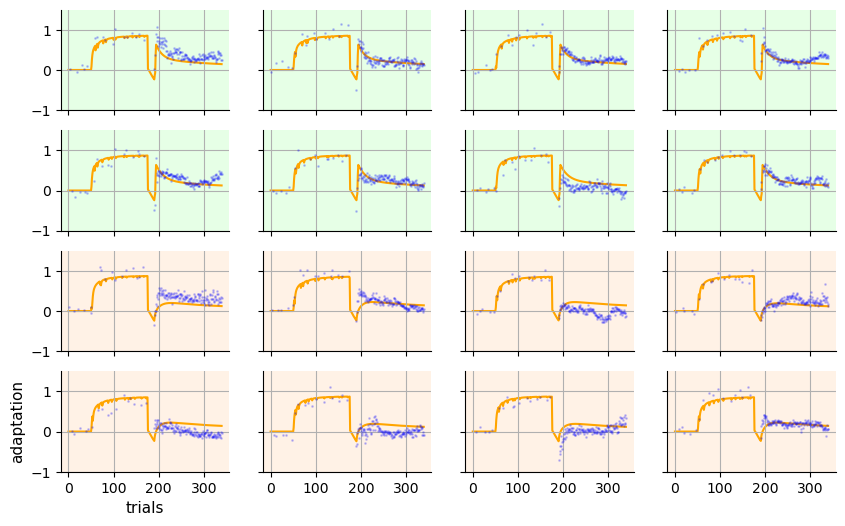

In [162]:
lerner_switch = False


plt.figure(figsize=(10, 6))
plt.subplot(4, 4, 1)
cnt=0
for ii, (this_exp, this_pred) in enumerate(zip(a_exp.T, a_pred.T)):
    this_sub = ii//seeds
    plt.subplot(4, 4, 1 + this_sub)
    polarity = np.sign(np.nanmean(this_exp[:175]))
    if ii % seeds == 0:
        plt.plot(polarity*this_exp,'.', label='Experimental', color='blue', markersize=2, alpha=0.2)
    # if ii == best_seed_idx[this_sub]:
    if ii % seeds == best_seed_idx[0]:
        plt.plot(polarity*this_pred, label='Predicted', color='orange',zorder=0)
        plt.grid() #; print(cnt); cnt+=1
        plt.ylim([-1,1.5])

    if this_sub % 4 > 0:
        plt.gca().set_yticklabels([])
    if this_sub < 12:
        plt.gca().set_xticklabels([])

    if not lerner_switch:
        if this_sub <8:
            # plt.axvspan(0, 340, color='green', alpha=0.01)
            plt.gca().set_facecolor((0.9,1,0.9))
        else:
            # plt.axvspan(0,340, color='orange', alpha=0.1)
            plt.gca().set_facecolor((1,0.95,0.9))
    else:
        if this_sub <15:
            # plt.axvspan(0, 340, color='green', alpha=0.01)
            plt.gca().set_facecolor((0.9,0.9,1))
        else:
            # plt.axvspan(0,340, color='orange', alpha=0.1)
            plt.gca().set_facecolor((0.8,0.7,1))
plt.subplot(4, 4, 13)
plt.xlabel('trials')
plt.ylabel('adaptation')
# plt.title('Experimental vs Predicted Data')
# plt.savefig('/homes/ar2342/one_more_dir/contextual_frogs/figs/ersrFitsM19.pdf', format='pdf', bbox_inches='tight')# 
# plt.savefig('/homes/ar2342/one_more_dir/contextual_frogs/figs/lernerFitsM19.pdf', format='pdf', bbox_inches='tight')

In [163]:
these_bics = [bic_gaussian_from_rmse(this_rmse, n=this_n, k=k_params) for this_rmse, this_n in zip(best_rmse, n_samples)]

Found NaN in prediction for seed index 29


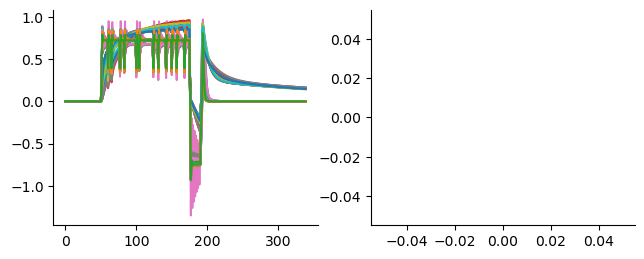

In [164]:
plt.figure(figsize=(2*ufigx, ufigy))
for ii, (this_exp, this_pred) in enumerate(zip(a_exp.T[0:64], a_pred.T[0:64])):
    if np.isnan(this_pred).any():
        print(f'Found NaN in prediction for seed index {ii}')
        plt.subplot(1,2,2)
        plt.plot(this_pred)
    else:
        plt.subplot(1,2,1)
        plt.plot(this_pred)

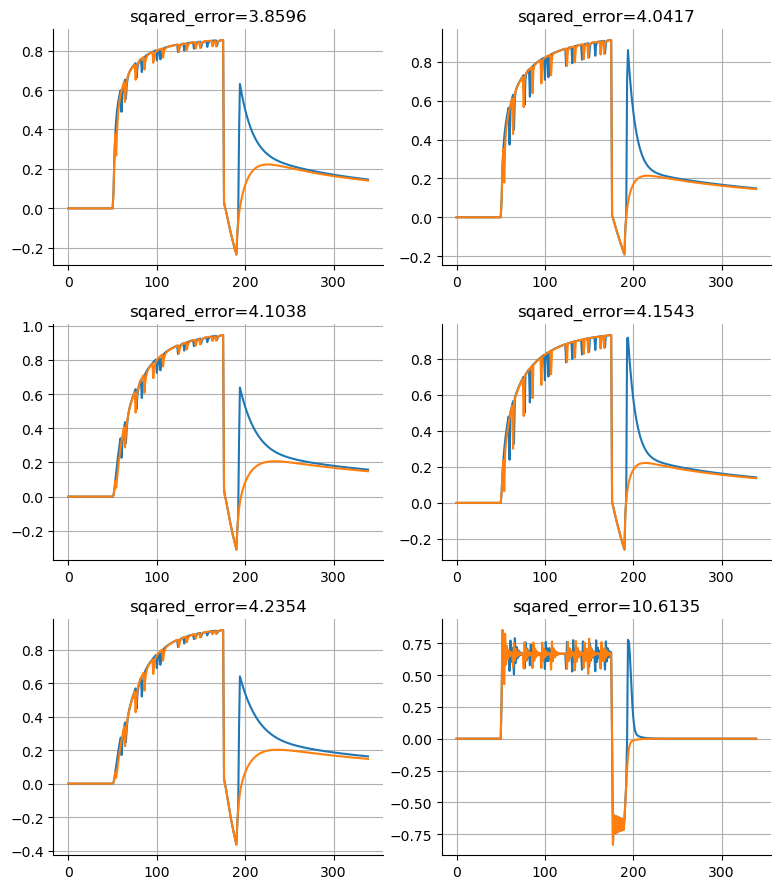

In [165]:
plt.figure(figsize=(8, 9))

prev_pred_ER = np.zeros_like(a_pred[:,0])
prev_pred_SR = np.zeros_like(a_pred[:,64*15]) #64 seeds times 8 participants
skipped = 0
jj = 1
for ii, ss in enumerate(seed_data['seeds_ranked']):
    this_pred_ER = a_pred[:, ss]  
    this_pred_SR = a_pred[:, ss + 64*15] 
    if np.isnan(this_pred_ER).any() or np.isnan(this_pred_SR).any():
        print(f'Found NaN in prediction for seed index {ss}')
    else:
        this_diff_ER = np.abs(this_pred_ER - prev_pred_ER).max()
        this_diff_SR = np.abs(this_pred_SR - prev_pred_SR).max()
        if this_diff_ER > 10e-2 or this_diff_SR > 10e-2:
            plt.subplot(3, 2, jj)

            plt.plot(this_pred_ER)
            plt.plot(this_pred_SR)
            plt.grid()
            # plt.title(f'Seed index {ss}, max diff from previous:\nER={this_diff_ER:.4f}, SR={this_diff_SR:.4f}\n sqared_error={seed_data["se_per_seed"][ss]}\n skipped {skipped} seeds so far')
            plt.title(f'sqared_error={seed_data["se_per_seed"][ss]/16:.4f}')
            skipped = 0
            jj += 1
            if jj > 6:
                break
        else:
            skipped +=1
        prev_pred_ER = this_pred_ER + 0.
        prev_pred_SR = this_pred_SR + 0.
plt.tight_layout()

In [166]:
seed_data['seeds_ranked']

array([38, 26, 32, 61, 33, 51, 49, 39,  4, 10, 15,  1, 34,  5, 54, 40, 35,
       13,  7,  3, 24,  0, 22,  9, 23, 20, 46, 60, 21, 56, 25, 31, 59, 30,
       58, 44, 37, 17, 57, 14, 43, 50,  6,  2, 41, 36, 19, 62, 18, 53, 27,
       11,  8, 63, 48, 28, 52, 47, 42, 55, 45, 12, 16, 29])

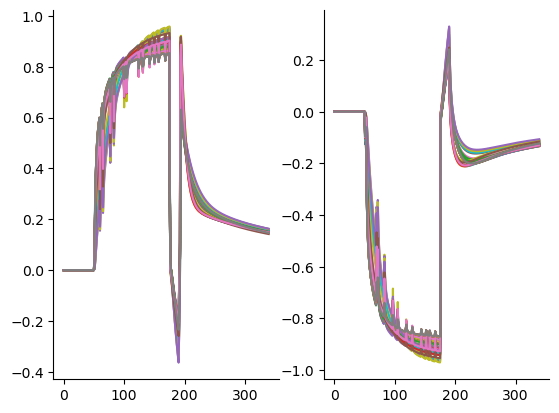

In [167]:
for seed in range(seeds):
    this_predER = a_pred.T[seed]
    this_predSR = a_pred.T[seed+128*4]
    if this_predER[-10]<0.1:
        continue
    if np.isnan(this_pred).any():
        print(f'Found NaN in prediction for seed index {ii}')
    else:
        plt.subplot(1,2,1)
        plt.plot(this_predER)
        plt.subplot(1,2,2)
        plt.plot(this_predSR)

In [168]:
coin_bics_path = '/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/coin_bics1000.txt'
coin_bics = np.loadtxt(coin_bics_path)

In [169]:
n_samples

array([165, 165, 165, 165, 165, 165, 165, 165, 167, 167, 167, 167, 167,
       167, 167, 167])

<StemContainer object of 3 artists>

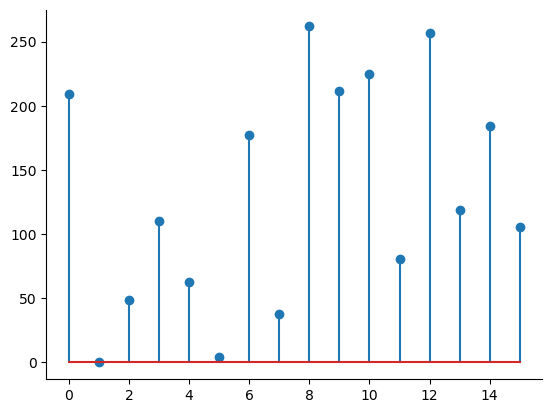

In [170]:
plt.stem(these_bics-coin_bics)

In [171]:
best_rmse

array([0.18764704, 0.09585674, 0.09450599, 0.1268499 , 0.13358008,
       0.11068122, 0.17827136, 0.0962094 , 0.20201744, 0.1351933 ,
       0.20721041, 0.12827674, 0.19756944, 0.16769559, 0.18744035,
       0.10071444])

In [172]:
these_bics-coin_bics

array([209.08599063,  -0.39366286,  48.18064547, 110.02544911,
        62.58905302,   3.63744791, 177.30675013,  37.14012159,
       261.8116473 , 211.32177645, 224.51221658,  80.29165642,
       256.70160521, 118.80092484, 183.97517155, 105.65650026])

In [173]:
np.sum((these_bics-coin_bics)[:8])

647.5717949899267

In [174]:
dual_rate_bics = np.loadtxt('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/dual_rate_bics_v1.txt')
dual_rateNL_bics = np.loadtxt('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/dual_rateNL_bics_v1.txt')


In [175]:
print( np.sum((these_bics-coin_bics)[:8]) , np.sum((these_bics-coin_bics)[8:]) )
print( np.sum((these_bics-dual_rate_bics)[:8]) , np.sum((these_bics-dual_rate_bics)[8:]) )
print( np.sum((these_bics-dual_rateNL_bics)[:8]) , np.sum((these_bics-dual_rateNL_bics)[8:]) )
print('-'*20)
print( np.sum((dual_rate_bics-coin_bics)[:8]) , np.sum((dual_rate_bics-coin_bics)[8:]) )


647.5717949899267 1443.0714986122266
283.3288495321745 1192.344721501942
382.7369650113768 1370.3294849768354
--------------------
364.24294545775217 250.72677711028442


<StemContainer object of 3 artists>

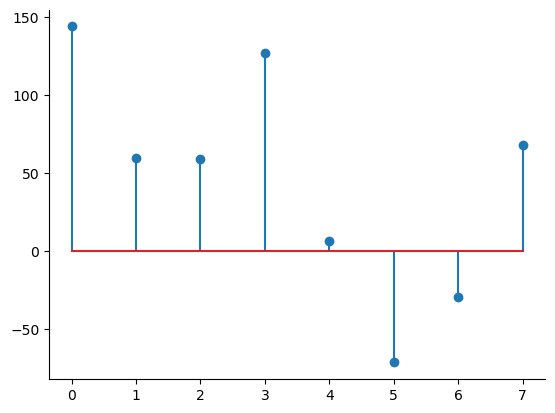

In [176]:
plt.stem((dual_rate_bics-coin_bics)[:8])

<StemContainer object of 3 artists>

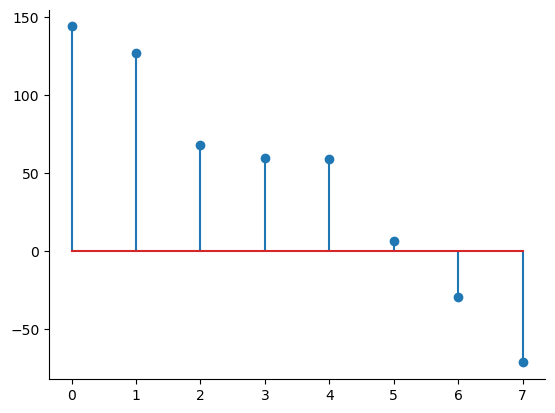

In [177]:
plt.stem(-np.sort(-(dual_rate_bics-coin_bics)[:8]))

<StemContainer object of 3 artists>

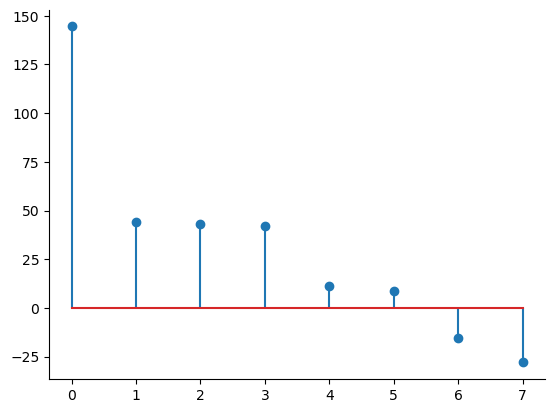

In [178]:
plt.stem(-np.sort(-(dual_rate_bics-coin_bics)[8:]))

In [179]:
these_bics

[-83.90380937200473,
 -305.5674628649685,
 -310.250654532622,
 -213.11805089087122,
 -196.0581469794255,
 -258.1136520879542,
 -100.81824987394629,
 -304.355578408281,
 -60.27455270096053,
 -194.42512354912068,
 -51.79738341517483,
 -211.96534358152854,
 -67.71069478825046,
 -122.46657515837602,
 -85.2889284494323,
 -292.7601997449301]

In [180]:
# np.savetxt('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/dual_rateNL_bics_v1.txt', these_bics)

Text(11, -50, 'SR')

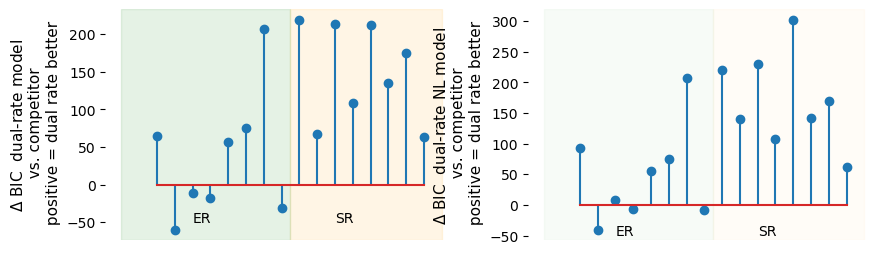

In [181]:
plt.figure(figsize=(10, 3))
plt.subplot(1,2,1)
plt.stem(np.arange(1, 17), these_bics - dual_rate_bics)
plt.axvspan(-1, 8.5, color='green', alpha=0.1)
plt.axvspan(8.5,17, color='orange', alpha=0.1)
plt.box('off')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.xticks([])
# plt.ylabel('\Delta BIC  dual-rate model\n linear decay vs. power law decay \n positive = linear better')
plt.ylabel('$\Delta$ BIC  dual-rate model\n  vs. competitor \n positive = dual rate better')
plt.text(3,-50,'ER')
plt.text(8+3,-50,'SR')


plt.subplot(1,2,2)
plt.stem(np.arange(1, 17), these_bics - dual_rateNL_bics)
plt.axvspan(-1, 8.5, color='green', alpha=0.03)
plt.axvspan(8.5,17, color='orange', alpha=0.03)
plt.box('off')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.xticks([])
# plt.ylabel('\Delta BIC  dual-rate model\n linear decay vs. power law decay \n positive = linear better')
plt.ylabel('$\Delta$ BIC  dual-rate NL model\n  vs. competitor \n positive = dual rate better')
plt.text(3,-50,'ER')
plt.text(8+3,-50,'SR')

Text(11, -50, 'SR')

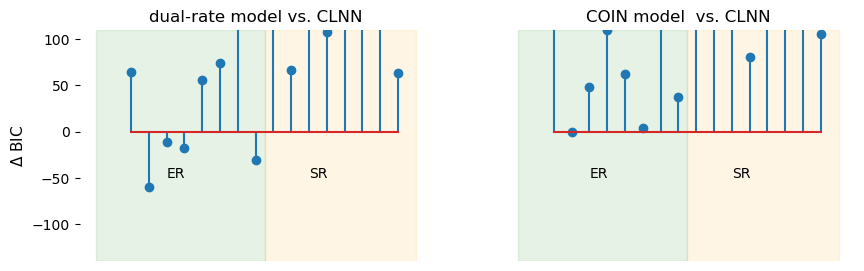

In [182]:
plt.figure(figsize=(10, 3))
plt.subplot (1, 2, 1)
plt.stem(np.arange(1, 17), these_bics - dual_rate_bics)
plt.axvspan(-1, 8.5, color='green', alpha=0.1)
plt.axvspan(8.5,17, color='orange', alpha=0.1)
plt.box('off')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.ylim([-140, 110])
plt.xticks([])
# plt.ylabel('\Delta BIC  dual-rate model\n linear decay vs. power law decay \n positive = linear better')
plt.ylabel('$\Delta$ BIC')
plt.title('dual-rate model vs. CLNN')# \n positive = dual rate better')
plt.text(3,-50,'ER')
plt.text(8+3,-50,'SR')

plt.subplot (1, 2, 2)
plt.stem(np.arange(1, 17), these_bics - coin_bics)
plt.axvspan(-1, 8.5, color='green', alpha=0.1)
plt.axvspan(8.5,17, color='orange', alpha=0.1)
plt.box('off')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.ylim([-140, 110])

plt.xticks([])
plt.yticks([])
# plt.ylabel('\Delta BIC  dual-rate model\n linear decay vs. power law decay \n positive = linear better')
# plt.ylabel('$\Delta$ BIC')
plt.title('COIN model  vs. CLNN') # \n positive = COIN model better')
plt.text(3,-50,'ER')
plt.text(8+3,-50,'SR')
# plt.savefig('/homes/ar2342/one_more_dir/contextual_frogs/figs/ersrBIC.pdf', format='pdf', bbox_inches='tight')

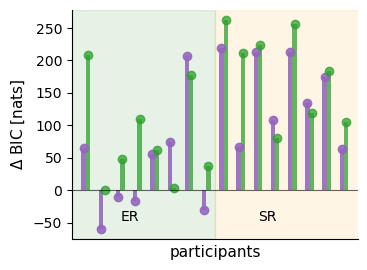

In [183]:
# combined BIC panel
# CLNN is the baseline; dual-rate model in purple; coin model in magenta (bars)
# background shades as in the previous fig

clnn_bics = np.asarray(these_bics)
dual_bics = np.asarray(dual_rate_bics)
coin_bics_arr = np.asarray(coin_bics)

if not (clnn_bics.shape == dual_bics.shape == coin_bics_arr.shape):
    raise ValueError(
        f'Shape mismatch: CLNN {clnn_bics.shape}, dual-rate {dual_bics.shape}, COIN {coin_bics_arr.shape}'
    )

x = np.arange(1, clnn_bics.size + 1)
delta_dual = clnn_bics - dual_bics
delta_coin = clnn_bics - coin_bics_arr

fig, ax = plt.subplots(1, 1, figsize=(ufigx, ufigy))

# ER / SR background shading (same style as previous panel)
split_x = 8.5
ax.axvspan(-1, split_x, color='green', alpha=0.1)
ax.axvspan(split_x, clnn_bics.size + 1, color='orange', alpha=0.1)

bar_w = 0.36
ax.bar(x - bar_w*0.35 , delta_dual, width=bar_w*0.7, color='tab:purple', alpha=0.9, label='dual-rate vs CLNN')
ax.bar(x + bar_w*0.35, delta_coin, width=bar_w*0.7, color='tab:green', alpha=0.75, label='COIN vs CLNN')
ax.plot(x - bar_w*0.35 , delta_dual, 'o', color='tab:purple', alpha=0.9, label='dual-rate vs CLNN')
ax.plot(x + bar_w*0.35, delta_coin, 'o', color='tab:green', alpha=0.75, label='COIN vs CLNN')


ax.axhline(0, color='k', linewidth=0.8, alpha=0.6)
ax.set_xlim(0.2, clnn_bics.size + 0.8)
ax.set_ylabel('$\\Delta$ BIC [nats]')
ax.set_xlabel('participants')
# ax.set_title('Model comparison vs CLNN')
ax.set_xticks([])
ax.text(3, ax.get_ylim()[0] + 0.08 * (ax.get_ylim()[1] - ax.get_ylim()[0]), 'ER')
ax.text(11, ax.get_ylim()[0] + 0.08 * (ax.get_ylim()[1] - ax.get_ylim()[0]), 'SR')
# ax.legend(frameon=False, loc='best')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

In [184]:

#Lerner's variant

# plt.figure(figsize=(5, 3))
# plt.subplot (1, 1, 1)
# plt.stem(np.arange(1, 17), these_bics - (lerner_dual_rate_bics['best_bics']))
# plt.axvspan(-1, 15.5, color=(0.9,0.9,1))#, alpha=0.1)
# plt.axvspan(15.5,17, color=(0.8,0.7,1))#, alpha=0.1)
# plt.box('off')
# plt.gca().spines['top'].set_visible(False)
# plt.gca().spines['right'].set_visible(False)
# plt.gca().spines['left'].set_visible(False)
# plt.gca().spines['bottom'].set_visible(False)
# plt.ylim([-60, 20])
# plt.xticks([])
# # plt.ylabel('\Delta BIC  dual-rate model\n linear decay vs. power law decay \n positive = linear better')
# plt.ylabel('$\Delta$ BIC')
# plt.title('dual-rate model vs. CLNN')# \n positive = dual rate better')
# plt.text(3,-50,'Individual  Fits \n (Anterograde Interference)')
# plt.text(16.2,-40,'Mean Fit', rotation=90, va='center')


# plt.subplot (1, 2, 2)
# plt.stem(np.arange(1, 17), these_bics - coin_bics)
# plt.axvspan(-1, 8.5, color='green', alpha=0.1)
# plt.axvspan(8.5,17, color='orange', alpha=0.1)
# plt.box('off')
# plt.gca().spines['top'].set_visible(False)
# plt.gca().spines['right'].set_visible(False)
# plt.gca().spines['left'].set_visible(False)
# plt.gca().spines['bottom'].set_visible(False)
# plt.ylim([-110, 110])

# plt.xticks([])
# plt.yticks([])
# # plt.ylabel('\Delta BIC  dual-rate model\n linear decay vs. power law decay \n positive = linear better')
# # plt.ylabel('$\Delta$ BIC')
# plt.title('COIN model  vs. CLNN') # \n positive = COIN model better')
# plt.text(3,-50,'ER')
# plt.text(8+3,-50,'SR')
# plt.savefig('/homes/ar2342/one_more_dir/contextual_frogs/figs/lernerBICg1.pdf', format='pdf', bbox_inches='tight')

In [185]:
ref_temp_rmse = np.array([0.14388285, 0.13275064, 0.18496574, 0.09147181, 0.16228775,
       0.1605799 , 0.18684085, 0.13883465, 0.11473347, 0.169773  ,
       0.20617779, 0.20484355, 0.10975336, 0.09605098, 0.18166255,
       0.1527941 , 0.16023854, 0.13980691, 0.16267194, 0.13959636,
       0.1403273 , 0.14730662, 0.12016405, 0.15779249])

In [ ]:
best_seed_idx_within_batch = np.array([best_seed_idx[0]]*16) # +(np.arange(subjs) * seeds)

#create a new model state dict with only the best seeds (seeds are the leading dimension of each parameter tensor)
best_model_state_dict = {}
for key, value in model_state_dict.items():
        print(key, value.shape)
        if key.endswith('_periodic_base'):
                cropped_key = key[:-len('_periodic_base')]
                cropper_key = cropped_key[1:]
                best_model_state_dict[cropper_key] = value[best_seed_idx_within_batch]
        else:
                best_model_state_dict[key] = value

In [188]:
from models_part2 import BatchedElboGenerativeModelTopMulti
import yaml
from types import SimpleNamespace
args_path = os.path.join(result_path, 'args.yaml')
with open(args_path, 'r') as f:
    args_dict = yaml.unsafe_load(f) #safe_load(f)
args = SimpleNamespace(**args_dict)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


In [189]:
import pickle

In [190]:
args_path

'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/froBmedian_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1/args.yaml'

In [191]:
args.bs = subjs  #set batch size to number of subjects

In [192]:
best_model_state_dict

{'log_learning_rate': tensor([[-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907],
         [-6.6907]]),
 'log_learning_rate_decay': tensor([[4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764],
         [4.3764]]),
 'output_scale': tensor([2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831,
         2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831, 2.7831]),
 'sp_weight_decay': tensor([[-7.0095],
         [-7.0095],
         [-7.0095],
         [-7.0095],
         [-7.0095],
         [-7.0095],
         [-7.0095],
 

In [193]:
# if args.enable_output_scale_tuning:
#     if hasattr(args, 'enable_input_scale_tuning') and args.enable_input_scale_tuning:
#         raise ValueError('Both output scale tuning and input scale tuning cannot be enabled at the same time, for now.')
#     if args.nl_activation != 'relu':
#         raise ValueError('Scaling migration is currently only implemented for ReLU nonlinearity'
#         '.')
#     args.enable_output_scale_tuning = False
#     args.enable_input_scale_tuning = True
#     # args.softclamp_input_scale_0to1 = args.softclamp_output_scale_0to1 if hasattr(args, 'softclamp_output_scale_0to1') else False

#     best_model_state_dict = migrate_output_scale_to_input_scale_state_dict(best_model_state_dict, 
#                                                                            remove_output_scale=True,
#                                                                            apply_softclamp_output_scale_0to1=args.softclamp_output_scale_0to1 if hasattr(args, 'softclamp_output_scale_0to1') else False,
#                                                                            model_for_softclamp=BatchedElboGenerativeModelTopMulti(device=device, args=args) ) 
#     print('Migrated output scale parameters to input scale parameters in the model state dict, and disabled output scale tuning while enabling input scale tuning.')
#     args.softclamp_output_scale_0to1 = False

# args.fixed_injection_param = 0.4



In [194]:
args.at_y_eq_inf = at_y_eq_inf
if at_y_eq_inf=="skip_slow_timescale_plasticity":
    #ensure that in best_model_state_dict learning rates are sorted from low to high (and weight decays accordingly)
    #'log_learning_rate', 'sp_weight_decay' are the effected parameters
    # lr_order = np.argsort(best_model_state_dict['log_learning_rate'])
    # sorted_lr = best_model_state_dict['log_learning_rate'][:,lr_order]
    # sorted_weight_decay = best_model_state_dict['sp_weight_decay'][:,lr_order]

    sorted_lr, lr_order = torch.sort(best_model_state_dict['log_learning_rate'], dim=1, descending=False)
    sorted_weight_decay = torch.gather(best_model_state_dict['sp_weight_decay'], dim=1, index=lr_order)
    best_model_state_dict['log_learning_rate'] = sorted_lr
    best_model_state_dict['sp_weight_decay'] = sorted_weight_decay

In [195]:
model = BatchedElboGenerativeModelTopMulti(device=device, args=args, 
                                           **(dict(fudge=args.fudge) if hasattr(args, 'fudge') else {}  )).to(device)
model.get_biases_and_w_in(args.n, device=device)
model.load_state_dict(best_model_state_dict, strict=False) #allow missing keys since we may have removed the output scale parameters during migration

_IncompatibleKeys(missing_keys=[], unexpected_keys=['sigma_b', 'input_scale', 'u_feedback_scale', 'weight_decay_exp', 'weight_learning_exp', 'q_scale', 'bias_lr', 'tauqlpf_m1', 'tauylpf_m1', 'tauelpf_m1', 'direct_injection_scale'])

In [303]:
# #save arguments and model state dict for future reference into results_path/best_model_state_dict/
best_model_dir = os.path.join(result_path, 'best_model_state_dict')
os.makedirs(best_model_dir, exist_ok=True)
args_save_path = os.path.join(best_model_dir, 'args.yaml')
with open(args_save_path, 'w') as f:
    yaml.dump(vars(args), f)
model_state_dict_save_path = os.path.join(best_model_dir, 'model_state_dict.pt')
torch.save(model.state_dict(), model_state_dict_save_path)

In [196]:
# best_model_state_dict = migrate_output_scale_to_input_scale_state_dict(best_model_state_dict, remove_output_scale=True)


In [197]:
def eval_single_paradigm(model, 
                         paradigm, 
                         args, 
                         paradigm_name=None, 
                         record_internals=False, 
                         record_vectors=False,
                         noise_spikes=[]):
    if paradigm_name is not None:
        print(f"evaluating paradigm {paradigm_name} with {len(paradigm)} steps")
    ys = torch.tensor(paradigm, device=next(model.parameters()).device)
    # duplicate ys across batch size
    ys = ys.unsqueeze(0).repeat(args.bs, 1)  # [bs, t]
    # noises = torch.randn((args.bs, ys.shape[1]), device=next(model.parameters()).device) * model.sigma_x  # [bs, t]
    noises = torch.zeros((args.bs, ys.shape[1]), device=next(model.parameters()).device)  # [bs, t]
    for t in noise_spikes:
        if t < noises.shape[1]:
            noises[:, t] = 1

    noises = [noises[:, t_idx] for t_idx in range(noises.shape[1])]
    ys = [ys[:, t_idx] for t_idx in range(ys.shape[1])]
    if paradigm_name is not None:
        print(f"noises shape: {noises[0].shape}, ys shape: {ys[0].shape}")
    model_setting = args.model
    outputs_ = model.f(
        args.n,
        noises,
        ys,
        model_setting,
        qs=None,
        record_internals=record_internals,
        record_vectors=record_vectors,
    )
    if record_internals:
        outputs_, internals = outputs_
        return outputs_, internals
    return outputs_, None


def local_eval_paradigms(model, playlist_file, args, record_internals=False, record_vectors=False):
    with open(playlist_file, "rb") as f:
        playlist = pickle.load(f)

    model.eval()
    with torch.no_grad():
        outputs = {}
        internals_by_paradigm = {} if record_internals else None
        for paradigm_name, paradigm in playlist.items():
            outputs_, internals = eval_single_paradigm(
                model,
                paradigm,
                args,
                paradigm_name=paradigm_name,
                record_internals=record_internals,
                record_vectors=record_vectors,
            )
            outputs[paradigm_name] = np.array([z.cpu().numpy().reshape(-1) for z in outputs_])
            if record_internals:
                internals_by_paradigm[paradigm_name] = internals
    if record_internals:
        return outputs, internals_by_paradigm
    return outputs

In [198]:
# paradigm_file='/homes/ar2342/one_more_dir/contextual_frogs/signoffrepertoire4.3h100.pkl'
paradigm_file='/homes/ar2342/one_more_dir/contextual_frogs/signoffrepertoire4.3.pkl'

with open(paradigm_file, "rb") as f:
        playlist = pickle.load(f)

In [199]:
model.state_dict()

OrderedDict([('log_learning_rate',
              tensor([[-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907],
                      [-6.6907]], device='cuda:0')),
             ('log_learning_rate_decay',
              tensor([[4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4.3764],
                      [4

In [296]:

# force_model_params(model, forced_params)

ooo = local_eval_paradigms(model, paradigm_file, args)

evaluating paradigm savings with 440 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB0 with 280 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB1 with 293 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB2 with 321 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB3 with 392 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB4 with 510 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB5 with 690 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm spontaneous with 340 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm evoked with 340 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm visw1p2 with 1150 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


In [297]:
# pooling_fun = np.nanmedian
# pooling_fun = np.nanmean
pooling_fun = np.mean

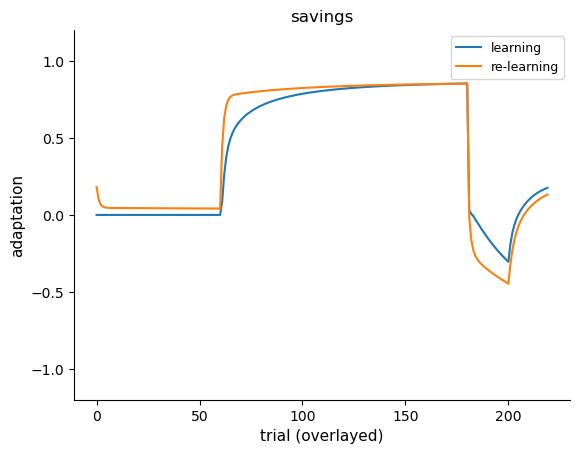

In [298]:
learning = ooo['savings'][:220]
relearning = ooo['savings'][220:]

learning_mean = pooling_fun(learning, axis=1)
relearning_mean = pooling_fun(relearning, axis=1)

learning_n = np.sum(~np.isnan(learning), axis=1)
relearning_n = np.sum(~np.isnan(relearning), axis=1)
learning_sem = np.divide(
    np.nanstd(learning, axis=1, ddof=1),
    np.sqrt(learning_n),
    out=np.zeros_like(learning_mean, dtype=float),
    where=learning_n > 1,
)
relearning_sem = np.divide(
    np.nanstd(relearning, axis=1, ddof=1),
    np.sqrt(relearning_n),
    out=np.zeros_like(relearning_mean, dtype=float),
    where=relearning_n > 1,
)

x_learning = np.arange(learning_mean.shape[0])
x_relearning = np.arange(relearning_mean.shape[0])

plt.plot(learning_mean, label='learning', color='tab:blue')
plt.fill_between(
    x_learning,
    learning_mean - learning_sem,
    learning_mean + learning_sem,
    color='tab:blue',
    alpha=0.2,
    linewidth=0,
)

plt.plot(relearning_mean, label='re-learning', color='tab:orange')
plt.fill_between(
    x_relearning,
    relearning_mean - relearning_sem,
    relearning_mean + relearning_sem,
    color='tab:orange',
    alpha=0.2,
    linewidth=0,
)

plt.title('savings')
plt.xlabel('trial (overlayed)')
plt.ylabel('adaptation')
plt.ylim([-1.2, 1.2])
plt.legend()

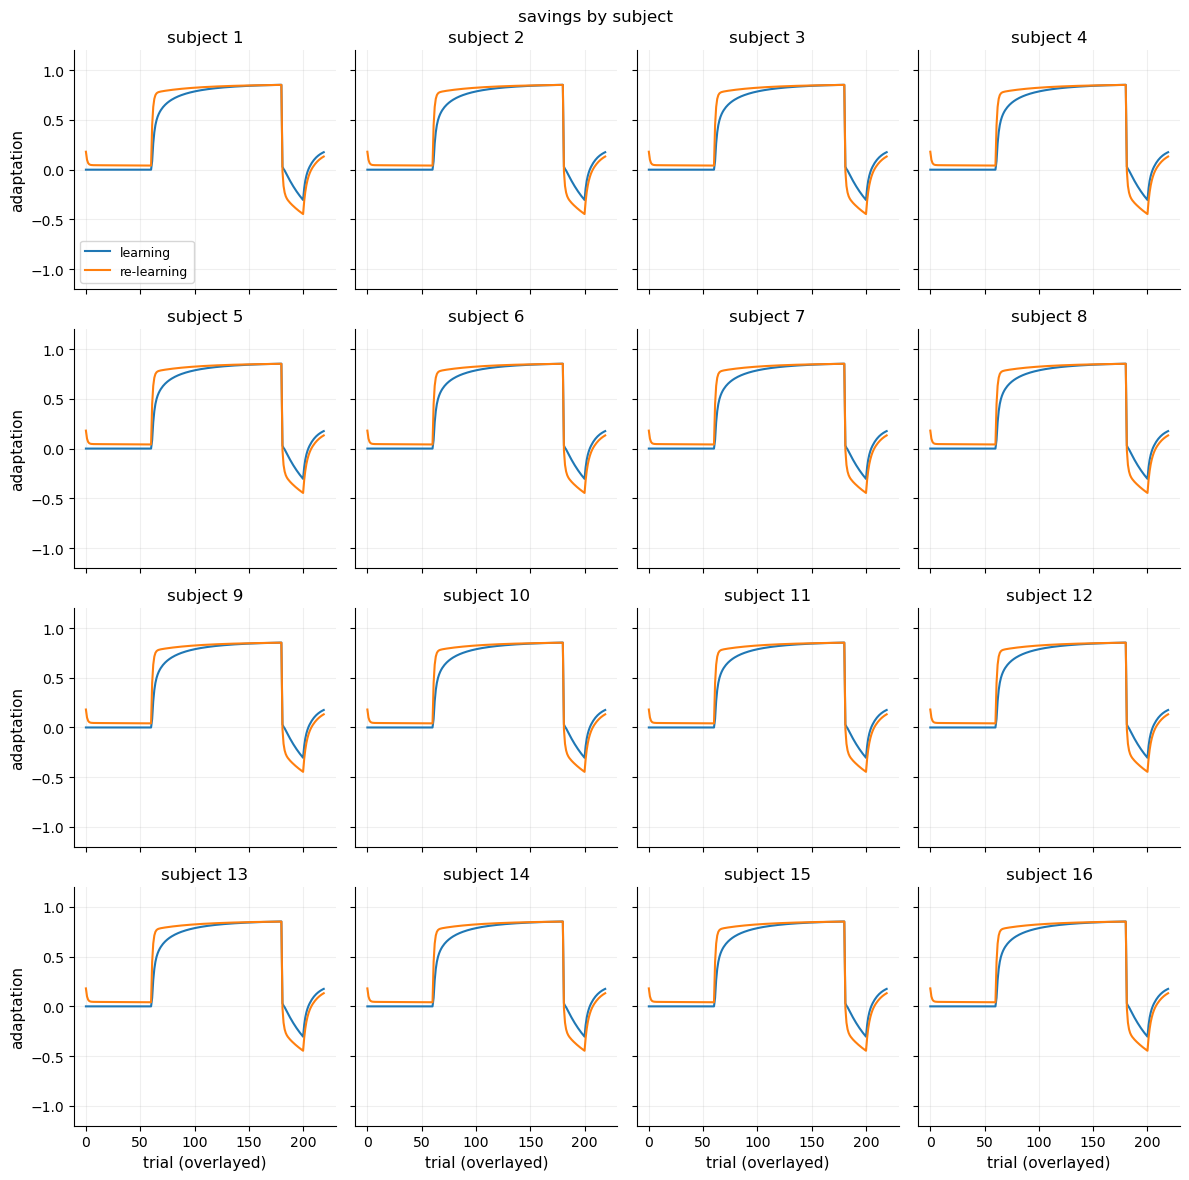

In [203]:
savings = ooo['savings']
split_idx = savings.shape[0] // 2

fig, axes = plt.subplots(4, 4, figsize=(12, 12), sharex=True, sharey=True)
for subj, ax in enumerate(axes.flat):
    ax.plot(savings[:split_idx, subj], label='learning')
    ax.plot(savings[split_idx:, subj], label='re-learning')
    ax.set_title(f'subject {subj + 1}')
    ax.set_ylim([-1.2, 1.2])
    ax.grid(alpha=0.2)

for ax in axes[-1, :]:
    ax.set_xlabel('trial (overlayed)')

for ax in axes[:, 0]:
    ax.set_ylabel('adaptation')

axes[0, 0].legend()
fig.suptitle('savings by subject')
fig.tight_layout()

In [204]:
from dsp_utils import smooth_signal

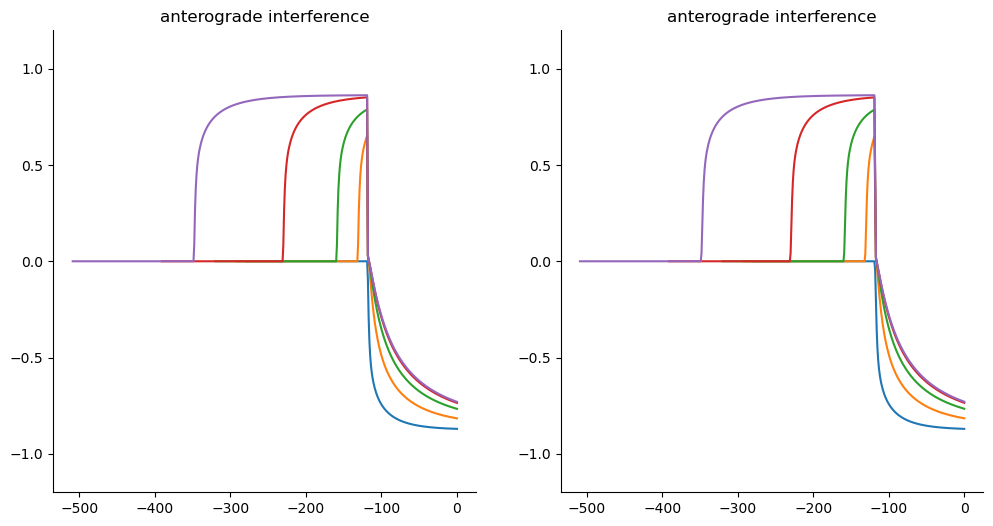

In [299]:
ant_list = [f'AB{i}' for i in range(0,5)]

plt.figure(figsize=(12,6))
for ii, smooth_fun in enumerate([lambda x: x,lambda x: smooth_signal(x, 2)]):
    plt.subplot(1,2,ii+1)
    plt.title('anterograde interference')
    for ant in ant_list:
        x_data = np.arange(len(ooo[ant].mean(axis=1)))
        # plt.plot(x_data,smooth_fun(pooling_fun(ooo[ant], axis=1)))
        plt.plot(x_data-np.max(x_data),smooth_fun(pooling_fun(ooo[ant], axis=1)))
        # for subj in range(subjs):
        #     plt.plot(x_data-np.max(x_data),ooo[ant][:, subj], color='gray', alpha=0.3)
    plt.ylim([-1.2, 1.2])

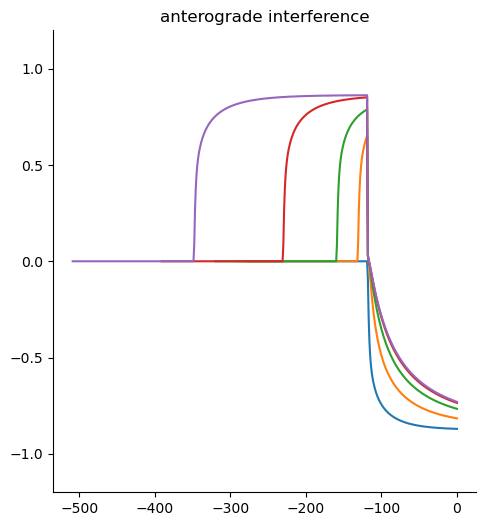

In [206]:
ant_list = [f'AB{i}' for i in range(0,5)]

plt.figure(figsize=(12,6))
for ii, smooth_fun in enumerate([lambda x: x]): #,lambda x: smooth_signal(x, 2)]):
    plt.subplot(1,2,ii+1)
    plt.title('anterograde interference')
    for ant in ant_list:
        x_data = np.arange(len(ooo[ant].mean(axis=1)))
        plt.plot(x_data-np.max(x_data),smooth_fun(pooling_fun(ooo[ant], axis=1)))
    plt.ylim([-1.2, 1.2])

Text(0.5, 1.0, 'environmental consistency')

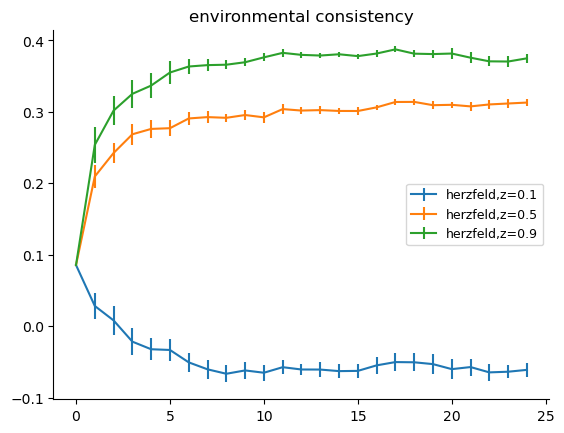

In [301]:
deltas_by_super_scenario = {}
for i, this_data in enumerate([ooo]):

    for iz, z in enumerate(ooo.keys()):
        if 'herzfeld' not in z:
            continue
        else:
            scenario = z
            super_scenario = z.split('$')[0]
        deltas = []
        mm = lambda x: np.mean(x,axis=0)
        this_result = pooling_fun(this_data[scenario],axis=1)
        pointer = 0
        for bb in range(25):
            block_length = len(this_result)//25
            deltas.append(this_result[pointer+2]-this_result[pointer])
            pointer += block_length

        if super_scenario not in deltas_by_super_scenario:
            deltas_by_super_scenario[super_scenario] = []
        deltas_by_super_scenario[super_scenario].append(deltas)

plt.figure()
for k in deltas_by_super_scenario:

    data = np.array(deltas_by_super_scenario[k])
    mean = np.mean(data,axis=0)
    std = np.std(data,axis=0)
    plt.errorbar(np.arange(len(mean)),mean,yerr=std/np.sqrt(data.shape[0]),label=k)

plt.legend()
plt.title('environmental consistency')
# plt.ylim(-1,1.2)

Text(0, 0.5, 'single trial learning')

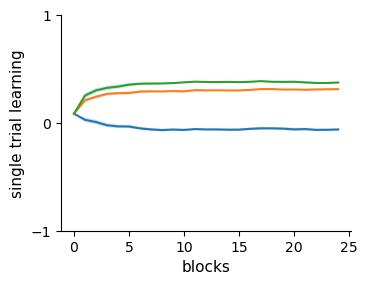

In [208]:
plt.rcParams.update(rcConf)

fig1, ax_traj = plt.subplots(figsize=(ufigx, ufigy))

# myplot(savings[:220],align_by_endpoint=False)
# myplot(savings[220:],align_by_endpoint=False)

for k in deltas_by_super_scenario:

    data = np.array(deltas_by_super_scenario[k])
    myplot(data.T, label=k,align_by_endpoint=False)
# ax_traj.set_xticklabels([ '$P^+$\n onset', '$P^-$\n onset', '$P^c$\n onset'])
# ax_traj.set_xticklabels([ '$P^+$', '$P^-$', '$P^c$'])
ax_traj.set_xlabel('blocks')


ax_traj.set_yticks([-1, 0, 1])
ax_traj.set_ylabel('single trial learning')
# fig1.savefig('part2_herzf_adapt.svg', format='svg', bbox_inches='tight')
# fig1.savefig('part2_herzf_linear.svg', format='svg', bbox_inches='tight')

Text(0, 0.5, 'adaptation')

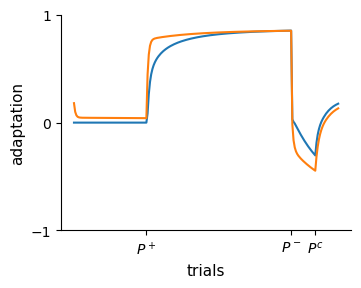

In [209]:
requested_timepoints = [60, 180, 200]

plt.rcParams.update(rcConf)

fig1, ax_traj = plt.subplots(figsize=(ufigx, ufigy))

myplot(savings[:220],align_by_endpoint=False)
myplot(savings[220:],align_by_endpoint=False)

ax_traj.set_xticks(requested_timepoints[:3])
# ax_traj.set_xticklabels([ '$P^+$\n onset', '$P^-$\n onset', '$P^c$\n onset'])
ax_traj.set_xticklabels([ '$P^+$', '$P^-$', '$P^c$'])
ax_traj.set_xlabel('trials')


ax_traj.set_yticks([-1, 0, 1])
ax_traj.set_ylabel('adaptation')
# fig1.savefig('part2_savings_linear.svg', format='svg', bbox_inches='tight')
# ax_traj.set_yticklabels([ '$P^+$', '$P^0$', '$P^+$'])

(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)
(1125, 16)

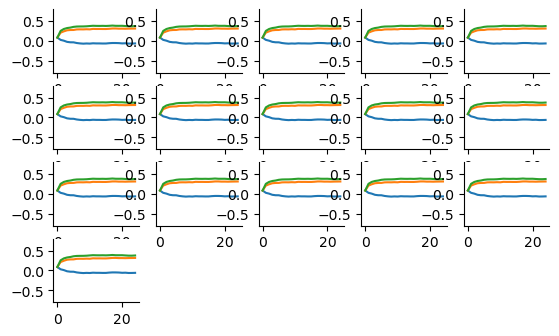

In [210]:
for pp in range(subjs):
    plt.subplot(5,5,pp+1)
    deltas_by_super_scenario = {}

    for i, this_data in enumerate([ooo]):
        # print(i)
        for iz, z in enumerate(ooo.keys()):
            if 'herzfeld' not in z:
                continue
            else:
                scenario = z
                super_scenario = z.split('$')[0]
            deltas = []
            mm = lambda x: np.mean(x,axis=0)
            # scenario = f'herzfeld,z={z}'
            # this_result = this_data[scenario].mean(axis=1)
            # print(f'processing subject {pp}, scenario {scenario}, result shape {this_data[scenario].shape}')
            # this_result = pooling_fun(this_data[scenario],axis=1)
            print(this_data[scenario].shape)
            this_result = this_data[scenario][:,pp]
            pointer = 0
            for bb in range(25):
                block_length = len(this_result)//25
                # print(this_result.shape)
                deltas.append(this_result[pointer+2]-this_result[pointer])
                pointer += block_length

            if super_scenario not in deltas_by_super_scenario:
                deltas_by_super_scenario[super_scenario] = []
            deltas_by_super_scenario[super_scenario].append(deltas)

        for k in deltas_by_super_scenario:
            # plt.plot(np.mean(deltas_by_super_scenario[k],axis=0),label=k)
            #present with error bars
            data = np.array(deltas_by_super_scenario[k])
            mean = np.mean(data,axis=0)
            # std = np.std(data,axis=0)
            # plt.errorbar(np.arange(len(mean)),mean,yerr=std/np.sqrt(data.shape[0]),label=k)
            plt.plot(np.arange(len(mean)),mean,label=k)

        # plt.legend()
        # plt.title('environmental consistency')
        plt.ylim(-0.8,0.8)

In [211]:
deltas_by_super_scenario

{'herzfeld,z=0.1': [[0.08564757130418446,
   -0.00943600892569867,
   -0.004435455705734562,
   -0.05513378964497269,
   -0.032084811387387516,
   -0.07764243140599861,
   -0.09309117571557413,
   -0.11988246726948214,
   -0.11670115264960627,
   -0.12160446206848273,
   -0.12689313203966776,
   -0.09633886231783635,
   -0.09534321114798223,
   -0.10880419549415889,
   -0.09565577082474772,
   -0.09147585034616477,
   -0.08222403308244781,
   -0.08822875045291186,
   -0.09321849169135359,
   -0.1042045129369015,
   -0.11407657068181049,
   -0.1261614315373926,
   -0.13047652077063426,
   -0.11588465683632904,
   -0.11935401596127074],
  [0.08564757130418446,
   0.09651998419973923,
   0.05810677621805851,
   0.04894701905069715,
   0.011322694889923348,
   -0.017830922282827382,
   -0.05236083468752479,
   -0.04097172130087294,
   -0.05926847584868021,
   -0.054321047420875165,
   -0.048835340778328525,
   -0.0487040734144774,
   -0.05775831338852753,
   -0.05070887071922611,
   -0.060

In [212]:
ooo_int = local_eval_paradigms(model, paradigm_file, args, record_internals=True,)

evaluating paradigm savings with 440 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB0 with 280 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB1 with 293 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB2 with 321 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB3 with 392 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB4 with 510 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm AB5 with 690 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm spontaneous with 340 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm evoked with 340 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm visw1p2 with 1150 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


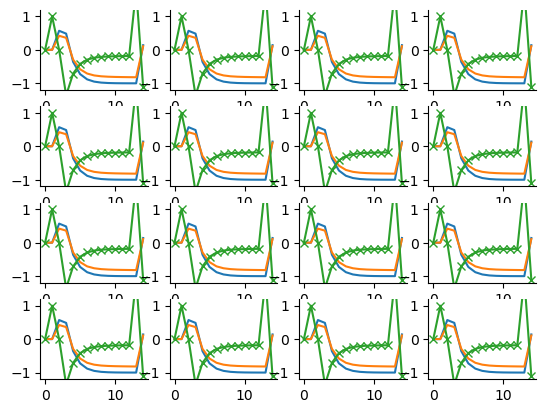

In [213]:
x_traj = ooo_int[1]['herzfeld,z=0.9$3']['x'].cpu().numpy()
u_traj = ooo_int[1]['herzfeld,z=0.9$3']['u'].cpu().numpy()
e_traj = ooo_int[1]['herzfeld,z=0.9$3']['e'].cpu().numpy()
t0 = 45*20
tw = 15
for s in range(x_traj.shape[1]):
    plt.subplot(4,4,s+1)
    plt.plot(x_traj[t0:t0+tw,s])
    plt.plot(u_traj[t0:t0+tw,s])
    plt.plot(e_traj[t0:t0+tw,s],'-x')
    plt.ylim(-1.2,1.2)

In [214]:
dd = []
herz_z = 0.1

for ii in range(5):
    x_traj = ooo_int[1][f'herzfeld,z={herz_z}${ii}']['x'].cpu().numpy()
    u_traj = ooo_int[1][f'herzfeld,z={herz_z}${ii}']['u'].cpu().numpy()
    e_traj = ooo_int[1][f'herzfeld,z={herz_z}${ii}']['e'].cpu().numpy()
    t0 = 45*20
    tw = 15
    t1 = np.arange(0,25*45,45)
    t2 = t1+2
    dd.append(u_traj[t2,:] - u_traj[t1,:])
    # dd.append(u_traj[t0+2,:] - u_traj[t0,:])
    # for s in range(x_traj.shape[1]):
        # plt.subplot(4,4,s+1)
        # plt.plot(x_traj[t0:t0+tw,s])
        # plt.plot(u_traj[t0:t0+tw,s])
        # plt.plot(e_traj[t0:t0+tw,s],'-x')
        # plt.ylim(-1.2,1.2)


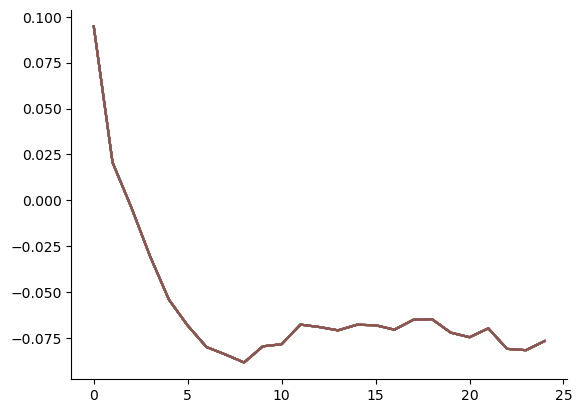

In [215]:
dd = np.array(dd)
dd.mean(axis=0), dd.mean()
plt.plot(dd.mean(axis=0))

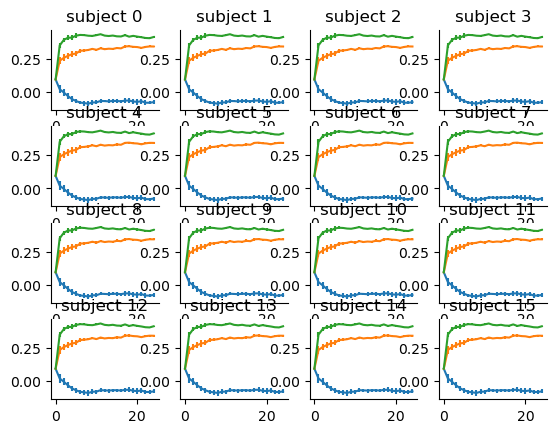

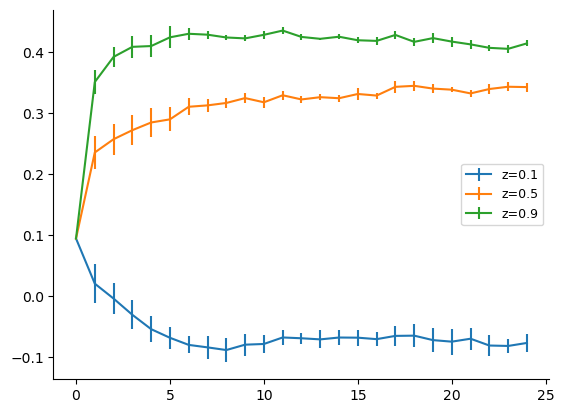

In [216]:
dd = {}
herz_z = [0.1,0.5,0.9]
for this_herz_z in herz_z:
    dd[this_herz_z] = []

    for ii in range(5):
        x_traj = ooo_int[1][f'herzfeld,z={this_herz_z}${ii}']['x'].cpu().numpy()
        u_traj = ooo_int[1][f'herzfeld,z={this_herz_z}${ii}']['u'].cpu().numpy()
        e_traj = ooo_int[1][f'herzfeld,z={this_herz_z}${ii}']['e'].cpu().numpy()
        t1 = np.arange(0,25*45,45)
        t2 = t1+2
        dd[this_herz_z].append(u_traj[t2,:] - u_traj[t1,:])

plt.figure()
for this_herz_z in herz_z:
    for ss in range(dd[this_herz_z][0].shape[1]):
        plt.subplot(4,4,ss+1)
        data = np.array(dd[this_herz_z])[:,:,ss]
        mean = np.mean(data,axis=0)
        std = np.std(data,axis=0)
        plt.errorbar(np.arange(len(mean)),mean,yerr=std/np.sqrt(data.shape[0]), label=f'z={this_herz_z}')
        plt.title(f'subject {ss}')
        # plt.ylim(-0.8,0.8)
plt.figure()
for this_herz_z in herz_z:
    data = np.mean(dd[this_herz_z],axis=-1)
    mean = np.mean(data,axis=0)
    std = np.std(data,axis=0)
    plt.errorbar(np.arange(len(mean)),mean,yerr=std/np.sqrt(data.shape[0]), label=f'z={this_herz_z}')
plt.legend()
# plt.ylim(-0.8,0.8)  

In [217]:
(std/np.sqrt(data.shape[0])).shape

(25,)

In [218]:
np.arange(mean.shape[0])

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24])

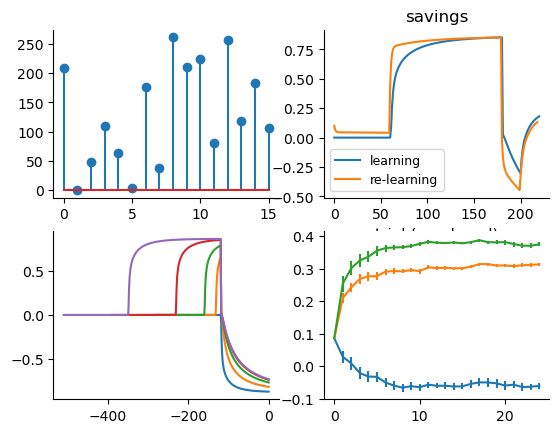

In [219]:
plt.subplot(2,2,1)
plt.stem(these_bics-coin_bics)
plt.subplot(2,2,2)
plt.plot(pooling_fun(ooo['savings'][:221], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['savings'][221:], axis=1), label='re-learning')
# for subj in range(subjs):
    # plt.plot(ooo['savings'][221:, subj], color='gray', alpha=0.3)
plt.title('savings')
plt.xlabel('trial (overlayed)')
# plt.ylabel('adaptation')
plt.legend()
plt.subplot(2,2,3)
# plt.title('anterograde interference')
for ant in ant_list:
    x_data = np.arange(len(ooo[ant].mean(axis=1)))
    plt.plot(x_data-np.max(x_data),pooling_fun(ooo[ant], axis=1))
    # for subj in range(subjs):
    #     plt.plot(x_data-np.max(x_data),ooo[ant][:, subj], color='gray', alpha=0.3)
plt.subplot(2,2,4)
for k in deltas_by_super_scenario:
    # plt.plot(np.mean(deltas_by_super_scenario[k],axis=0),label=k)
    #present with error bars
    data = np.array(deltas_by_super_scenario[k])
    mean = pooling_fun(data,axis=0)
    std = np.std(data,axis=0)
    plt.errorbar(np.arange(len(mean)),mean,yerr=std/np.sqrt(data.shape[0]),label=k)
    # plt.plot(np.arange(len(mean)),mean,label=k)


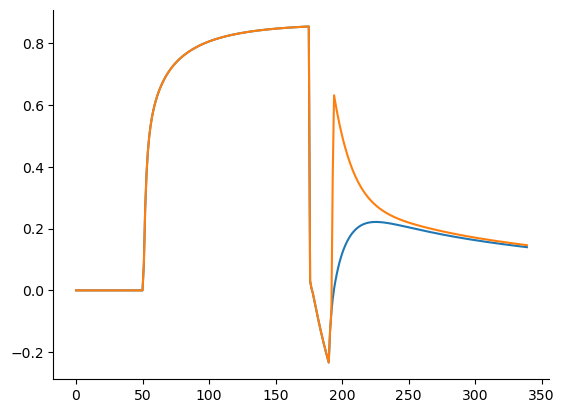

In [220]:
plt.plot(pooling_fun(ooo['spontaneous'], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['evoked'], axis=1) , label='learning')

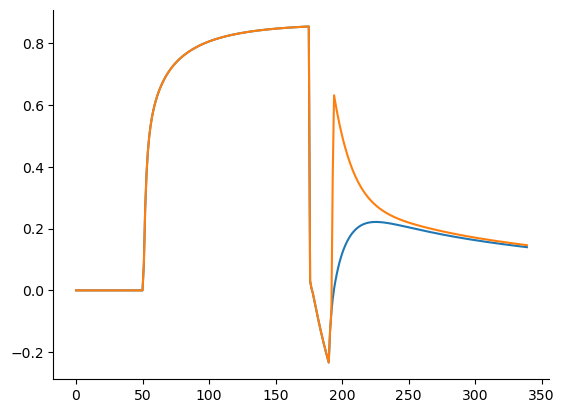

In [221]:
plt.plot(pooling_fun(ooo['spontaneous'], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['evoked'][:,list(range(14))+[15]], axis=1) , label='learning')

In [222]:
list(range(16))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

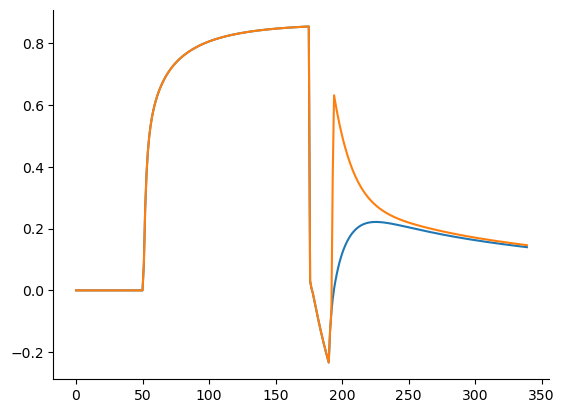

In [223]:
plt.plot(pooling_fun(ooo['spontaneous'][:,8:], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['evoked'][:,8:], axis=1) , label='learning')

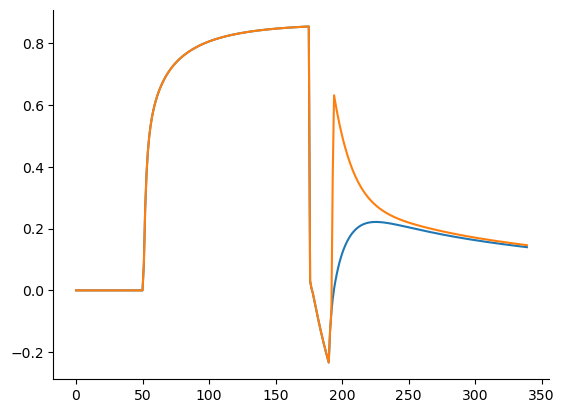

In [224]:
plt.plot(pooling_fun(ooo['spontaneous'][:,[8,9,10,11,12,13,15]], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['evoked'][:,[8,9,10,11,12,13,15]], axis=1) , label='learning')

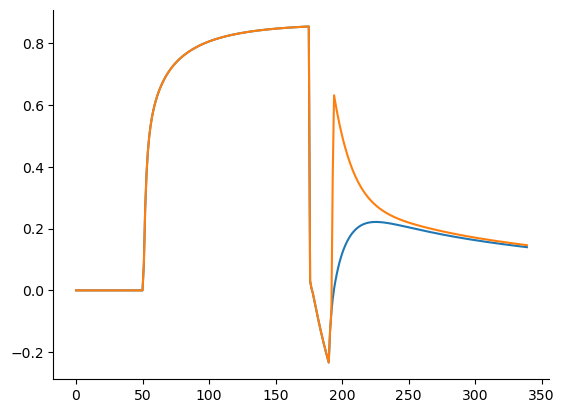

In [225]:
plt.plot(np.median(ooo['spontaneous'][:,8:], axis=1) , label='learning')
plt.plot(np.median(ooo['evoked'][:,8:], axis=1) , label='learning')

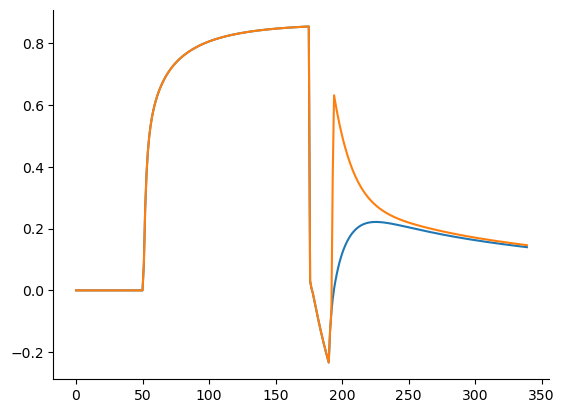

In [226]:
plt.plot(pooling_fun(ooo['spontaneous'][:,:8], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['evoked'][:,:8], axis=1) , label='learning')

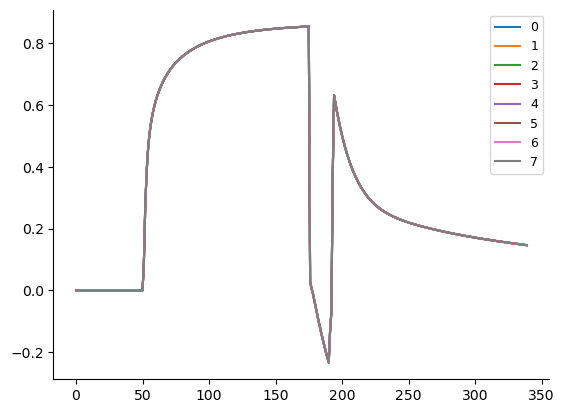

In [227]:
# plt.plot(ooo['spontaneous'][:,8:] , label='learning')
plt.plot(ooo['evoked'][:,8:])
plt.legend(np.arange(ooo['evoked'].shape[1]))

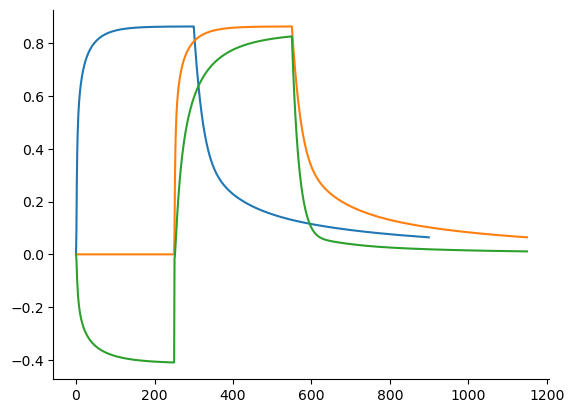

In [228]:
plt.plot(pooling_fun(ooo['visw1p1'], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['visw1p2'], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['visw1p3'], axis=1) , label='learning')

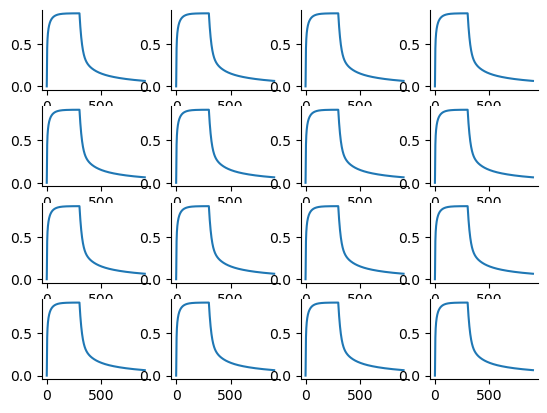

In [229]:
for i in range(ooo['visw1p1'].shape[1]):
    plt.subplot(4,4,i+1)
    plt.plot(ooo['visw1p1'][:,i], label=f'learning {i}')


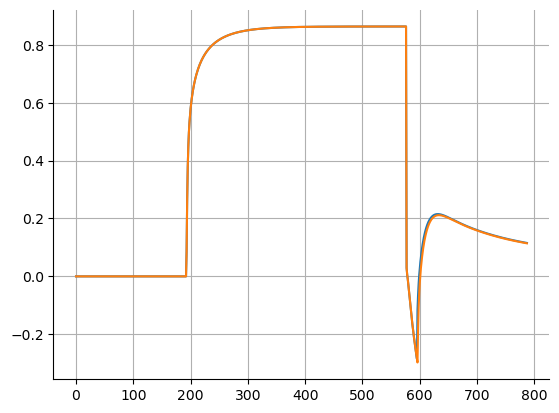

In [230]:
plt.plot(pooling_fun(ooo['wm_sr_manipulation'], axis=1) , label='learning')
plt.plot(pooling_fun(ooo['wm_sr_baseline'], axis=1) , label='learning')
plt.grid()

In [231]:
# # with open('/homes/ar2342/one_more_dir/contextual_frogs/aux_part2/dataMar18_Inj0.pkl', 'wb') as f:
# with open('/homes/ar2342/one_more_dir/contextual_frogs/aux_part2/dataMar18.pkl', 'wb') as f:
#     pickle.dump(ooo, f)

(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)
(25,)


/tmp/ipykernel_3691958/3457295834.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


(-1.0, 1.2)

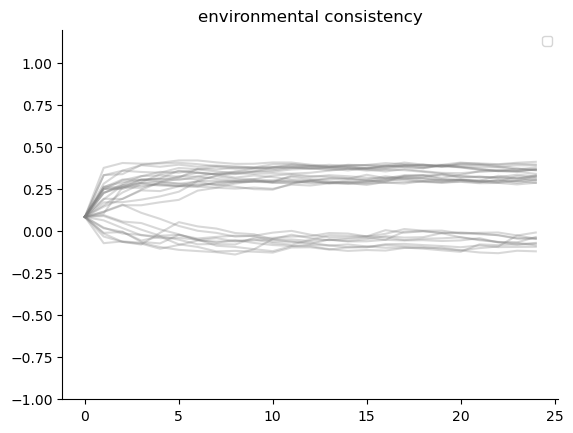

In [232]:
for k in deltas_by_super_scenario:
    # plt.plot(np.mean(deltas_by_super_scenario[k],axis=0),label=k)
    #present with error bars
    data = np.array(deltas_by_super_scenario[k])
    for datum in data:
        plt.plot(datum, color='gray', alpha=0.3)
        print(datum.shape)
    # mean = np.median(data,axis=0)
    # std = np.std(data,axis=0)
    # plt.errorbar(np.arange(len(mean)),mean,yerr=std/np.sqrt(data.shape[0]),label=k)
    # plt.plot(np.arange(len(mean)),mean,label=k)

plt.legend()
plt.title('environmental consistency')
plt.ylim(-1,1.2)

In [233]:
# plt.figure(figsize=(2,2.5))
# kk = 15/14
# plt.plot(kk*ooo['albert_block_0'].mean(axis=1), label='noiseless albert block', color='black')

# # noisy_trials = [ooo[f'albert_block_{ii}'].mean(axis=1) for ii in range(1,101)]
# noisy_trials = [ooo[f'albert_block_{ii}'].mean(axis=1) for ii in range(1,100)]
# plt.plot(kk*np.mean(noisy_trials, axis=0), label='noisy albert blocks mean', color='red')
# plt.axvspan(360, 400, facecolor='gray',  alpha=0.12, zorder=0)
# plt.ylim(-0.1,1.1)


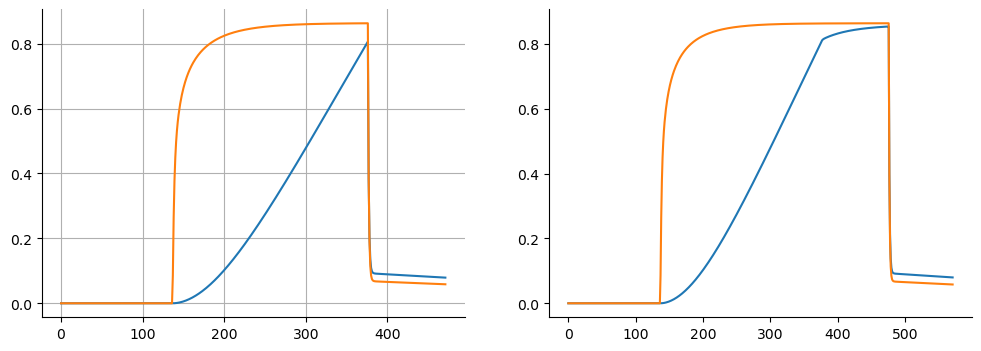

In [237]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(pooling_fun(ooo['frogs'], axis=1))
plt.plot(pooling_fun(ooo['anti_frogs'], axis=1))
plt.grid()

plt.subplot(1,2,2)
plt.plot(pooling_fun(ooo['frogs_plato'], axis=1))
plt.plot(pooling_fun(ooo['anti_frogs_plato'], axis=1))

In [235]:
k_for_frogs = 0.75
scaled_frogs, scaled_frogs_internal = eval_single_wrap(model, k_for_frogs * playlist['frogs'], args, paradigm_name='half_frogs', record_internals=True, record_vectors=False)
scaled_anti_frogs, scaled_anti_frogs_internal = eval_single_wrap(model, k_for_frogs * playlist['anti_frogs'], args, paradigm_name='half_anti_frogs', record_internals=True, record_vectors=False)

scaled_frogs_plato, scaled_frogs_plato_internal = eval_single_wrap(model, k_for_frogs * playlist['frogs_plato'], args, paradigm_name='half_frogs_plato', record_internals=True, record_vectors=False)
scaled_anti_frogs_plato, scaled_anti_frogs_plato_internal = eval_single_wrap(model, k_for_frogs * playlist['anti_frogs_plato'], args, paradigm_name='half_anti_frogs_plato', record_internals=True, record_vectors=False)

NameError: name 'eval_single_wrap' is not defined

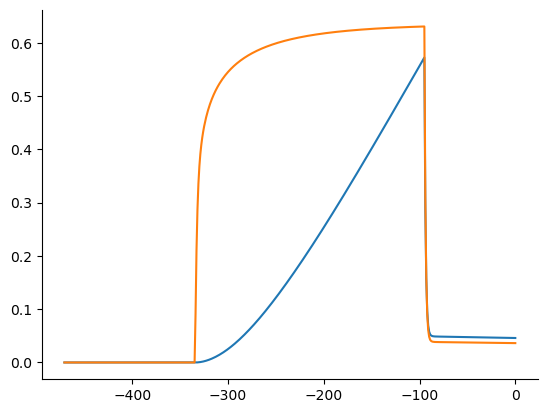

In [ ]:
# plt.subplot(1,2,1)
myplot(half_frogs)
myplot(half_anti_frogs)

# plt.subplot(1,2,2)
# # plt.plot(half_frogs)
# plt.plot(half_anti_frogs[:,0],'x-')

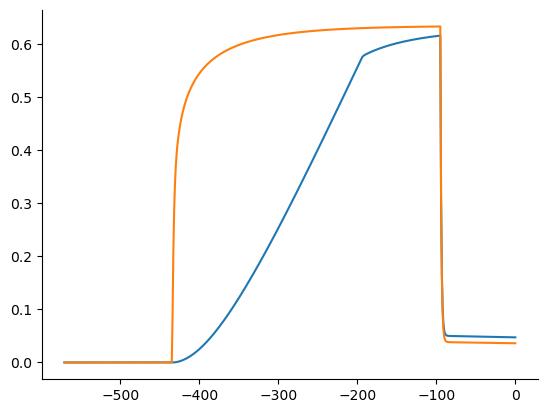

In [ ]:
myplot(half_frogs_plato)
myplot(half_anti_frogs_plato)

In [ ]:
ooo_int[1]

{'savings': {'u': tensor([[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0846, 0.0846, 0.0846,  ..., 0.0846, 0.0846, 0.0846],
          [0.0919, 0.0919, 0.0919,  ..., 0.0919, 0.0919, 0.0919],
          [0.0987, 0.0987, 0.0987,  ..., 0.0987, 0.0987, 0.0987]],
         device='cuda:0', dtype=torch.float64),
  'e': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0', dtype=torch.float64),
  'qlp': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,

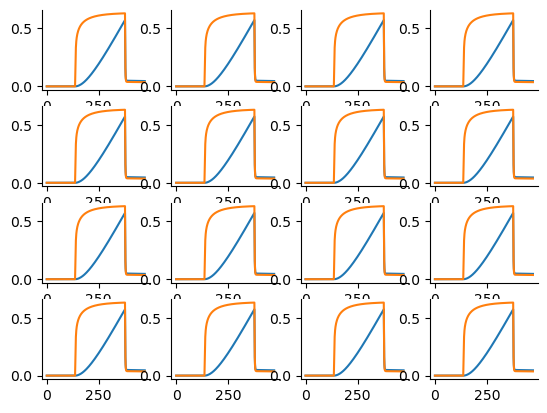

In [ ]:
for ii in range(16):
    plt.subplot(4,4,ii+1)
    plt.plot(half_frogs[:,ii])
    plt.plot(half_anti_frogs[:,ii])

(16, 16)

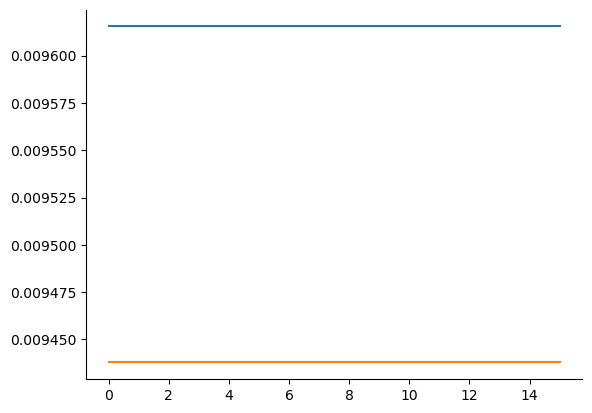

In [ ]:
plt.plot(half_frogs[-1,:] - half_anti_frogs[-1,:])
plt.plot((ooo['frogs'][-1,:] - ooo['anti_frogs'][-1,:]))

sum((half_frogs[-1,:] - half_anti_frogs[-1,:])>0), sum((ooo['frogs'][-1,:] - ooo['anti_frogs'][-1,:])>0)

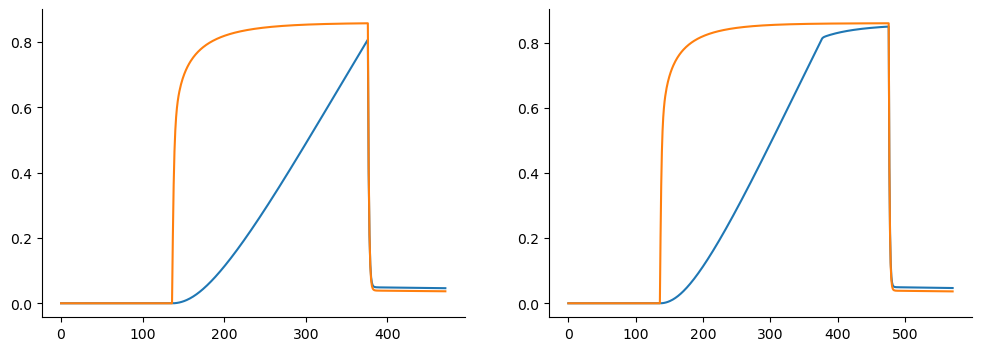

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(pooling_fun(ooo['frogs'], axis=1))
plt.plot(pooling_fun(ooo['anti_frogs'], axis=1))

plt.subplot(1,2,2)
plt.plot(pooling_fun(ooo['frogs_plato'], axis=1))
plt.plot(pooling_fun(ooo['anti_frogs_plato'], axis=1))

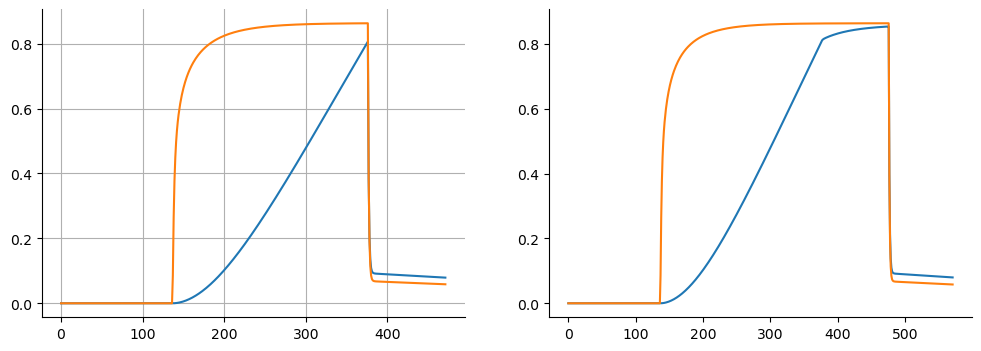

In [239]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(pooling_fun(ooo['frogs'][:,:8], axis=1))
plt.plot(pooling_fun(ooo['anti_frogs'][:,:8], axis=1))
plt.grid()

plt.subplot(1,2,2)
plt.plot(pooling_fun(ooo['frogs_plato'][:,:8], axis=1))
plt.plot(pooling_fun(ooo['anti_frogs_plato'][:,:8], axis=1))

Text(0, 0.5, 'adaptation')

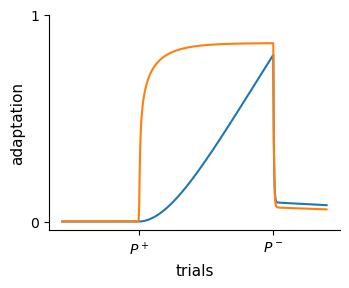

In [238]:
requested_timepoints = [136, 136+240]

plt.rcParams.update(rcConf)

fig1, ax_traj = plt.subplots(figsize=(ufigx, ufigy))

myplot(ooo['frogs'],align_by_endpoint=False)
myplot(ooo['anti_frogs'],align_by_endpoint=False)

ax_traj.set_xticks(requested_timepoints[:3])
# ax_traj.set_xticklabels([ '$P^+$\n onset', '$P^-$\n onset', '$P^c$\n onset'])
ax_traj.set_xticklabels([ '$P^+$', '$P^-$',])
ax_traj.set_xlabel('trials')


ax_traj.set_yticks([ 0, 1])
ax_traj.set_ylabel('adaptation')
# fig1.savefig('part2_frogs_ada.svg', format='svg', bbox_inches='tight')
# ax_traj.set_yticklabels([ '$P^+$', '$P^0$', '$P^+$'])

Text(0, 0.5, 'adaptation')

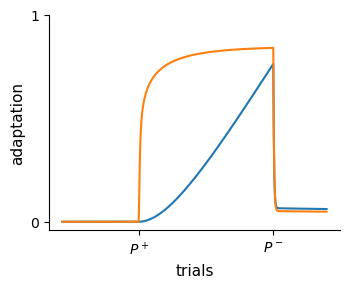

In [ ]:
requested_timepoints = [136, 136+240]

plt.rcParams.update(rcConf)

fig1, ax_traj = plt.subplots(figsize=(ufigx, ufigy))

myplot(scaled_frogs/k_for_frogs,align_by_endpoint=False)
myplot(scaled_anti_frogs/k_for_frogs,align_by_endpoint=False)

ax_traj.set_xticks(requested_timepoints[:3])
# ax_traj.set_xticklabels([ '$P^+$\n onset', '$P^-$\n onset', '$P^c$\n onset'])
ax_traj.set_xticklabels([ '$P^+$', '$P^-$',])
ax_traj.set_xlabel('trials')


ax_traj.set_yticks([ 0, 1])
ax_traj.set_ylabel('adaptation')
# fig1.savefig('part2_frogs_ada.svg', format='svg', bbox_inches='tight')
# ax_traj.set_yticklabels([ '$P^+$', '$P^0$', '$P^+$'])

Text(0, 0.5, 'adaptation')

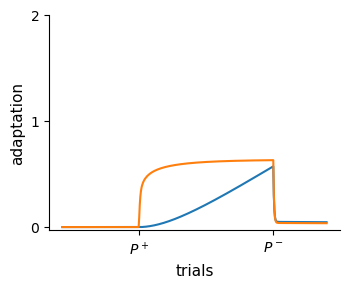

In [ ]:
requested_timepoints = [136, 136+240]

plt.rcParams.update(rcConf)

fig1, ax_traj = plt.subplots(figsize=(ufigx, ufigy))

myplot(half_frogs,align_by_endpoint=False)
myplot(half_anti_frogs,align_by_endpoint=False)

ax_traj.set_xticks(requested_timepoints[:3])
# ax_traj.set_xticklabels([ '$P^+$\n onset', '$P^-$\n onset', '$P^c$\n onset'])
ax_traj.set_xticklabels([ '$P^+$', '$P^-$',])
ax_traj.set_xlabel('trials')


ax_traj.set_yticks([ 0, 1, 2])
ax_traj.set_ylabel('adaptation')
# fig1.savefig('part2_2frogs_ada.svg', format='svg', bbox_inches='tight')
# ax_traj.set_yticklabels([ '$P^+$', '$P^0$', '$P^+$'])

In [245]:
# huberdeau5min_paradigm = np.array([0]*20+[1]*5+[np.nan]*15+[1]*50)
huberdeau5min_paradigm = np.array([0]*20+[1]*5+[np.inf]*15+[1]*30)
huberdeau5min_ctrl = np.array([0]*20+[1]*5+[np.nan]*15+[1]*30)
huberdeau0_paradigm = np.array([0]*20+[1]*30)

wait_time_equiv = 30*4
rot_num = [0,2,5,10,40]
huberdeau_rot_paradigms = {rot:np.array([0]*20+[1]*rot+[np.nan]*wait_time_equiv+[1]*30) for rot in rot_num}

huberdeau_anti_paradigm = np.array([0]*20+[-1]*5+[np.nan]*wait_time_equiv+[1]*30)
huberdeau_half_paradigm = np.array([0]*20+[0.5]*30+[np.nan]*wait_time_equiv+[1]*30)


huberdeau5min_out = eval_single_wrap(model, huberdeau5min_paradigm, args, paradigm_name='huberdeau5min', record_internals=False, record_vectors=False)[0]
huberdeau5min_ctrl_out = eval_single_wrap(model, huberdeau5min_ctrl, args, paradigm_name='huberdeau5min_ctrl', record_internals=False, record_vectors=False)[0]
huberdeau0_out = eval_single_wrap(model, huberdeau0_paradigm, args, paradigm_name='huberdeau0', record_internals=False, record_vectors=False)[0]
huberdeau_rot_outs = {}
for rot in rot_num:
    huberdeau_rot_outs[rot] = eval_single_wrap(model, huberdeau_rot_paradigms[rot], args, paradigm_name=f'huber_rot_{rot}', record_internals=False, record_vectors=False)[0]

huberdeau_anti_out = eval_single_wrap(model, huberdeau_anti_paradigm, args, paradigm_name='huberdeau_anti', record_internals=False, record_vectors=False)[0]
huberdeau_half_out = eval_single_wrap(model, huberdeau_half_paradigm, args, paradigm_name='huberdeau_half', record_internals=False, record_vectors=False)[0]


evaluating paradigm huberdeau5min with 70 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huberdeau5min_ctrl with 70 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huberdeau0 with 50 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huber_rot_0 with 170 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huber_rot_2 with 172 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huber_rot_5 with 175 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huber_rot_10 with 180 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huber_rot_40 with 210 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huberdeau_anti with 175 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm huberdeau_half w

(-30.0, 0.0)

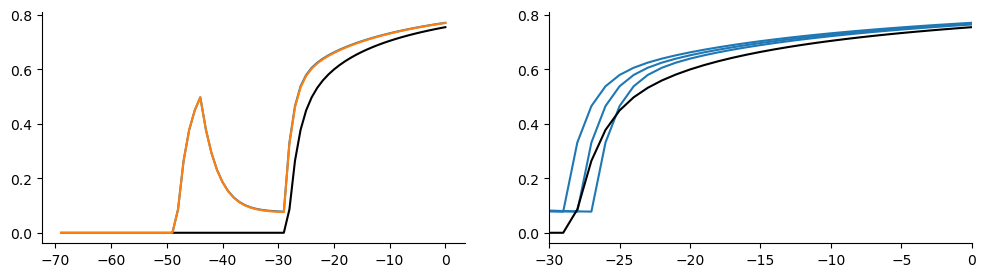

In [246]:
plt.figure(figsize=(12,3)
           )
plt.subplot(1,2,1)
myplot(huberdeau5min_out)
myplot(huberdeau0_out,'k')
myplot(huberdeau5min_ctrl_out,'tab:orange')
plt.subplot(1,2,2)
myplot(huberdeau5min_out)
myplot(huberdeau5min_out[:-1],'tab:blue')
myplot(huberdeau5min_out[:-2],'tab:blue')
myplot(huberdeau0_out,'k')
plt.xlim(-50, -20)
plt.xlim(-30, 0)

<Axes: >

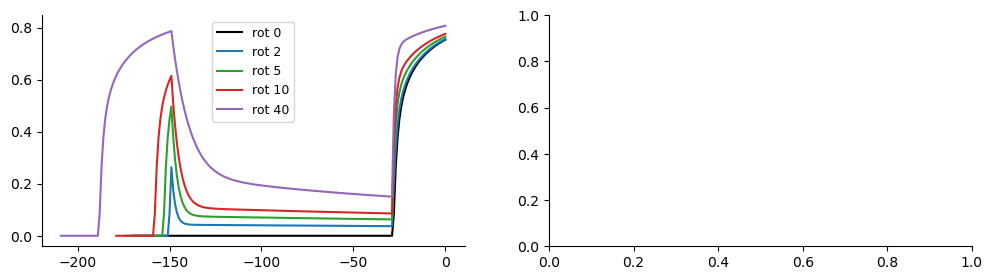

In [247]:
plt.figure(figsize=(12,3)
           )
plt.subplot(1,2,1)
rot_colors = ['k', 'tab:blue', 'tab:green', 'tab:red', 'tab:purple']
for i, rot in enumerate(rot_num):
    myplot(huberdeau_rot_outs[rot], color=rot_colors[i], label=f'rot {rot}')
plt.legend()
plt.subplot(1,2,2)


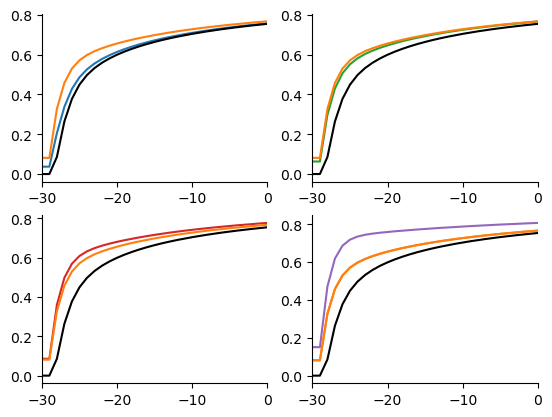

In [248]:
plt.subplot(2,2,1)
for i, rot in enumerate(rot_num[1:]):
    plt.subplot(2,2,i+1)
    myplot(huberdeau_rot_outs[rot], color=rot_colors[i+1], label=f'rot {rot}') 
    myplot(huberdeau_rot_outs[0], color=rot_colors[0], label=f'rot 0')
    myplot(huberdeau_half_out[:,:8],'tab:orange')
    plt.xlim(-30, 0)
plt.subplot(2,2,4)
myplot(huberdeau_half_out[:,:8],'tab:orange')

([<matplotlib.axis.YTick at 0x7ac73a961970>,
 [Text(0, 0.0, '0.0000'),
  Text(0, 0.16666666666666666, '0.1667'),
  Text(0, 0.3333333333333333, '0.3333'),
  Text(0, 0.5, '0.5000'),
  Text(0, 0.6666666666666666, '0.6667'),
  Text(0, 0.8333333333333333, '0.8333')])

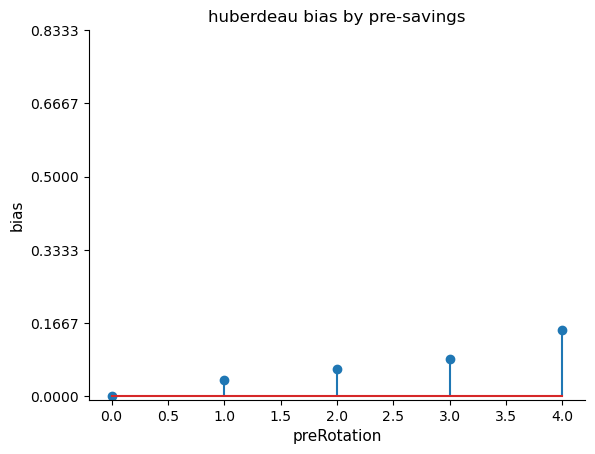

In [249]:
huberdeau_bias = [np.mean(huberdeau_rot_outs[rot][-30,:]) for i, rot in enumerate(rot_num)]
plt.stem( huberdeau_bias)
plt.xlabel('preRotation')
plt.ylabel('bias')
plt.title('huberdeau bias by pre-savings')
plt.yticks(np.arange(0,1,1/6))
    

(-30.0, 0.0)

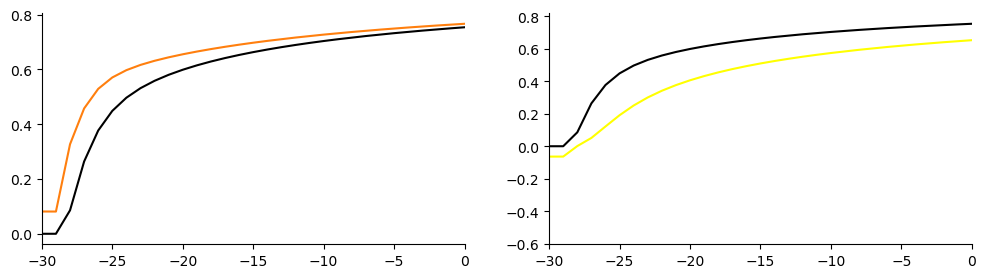

In [250]:
plt.figure(figsize=(12,3)
           )
plt.subplot(1,2,1)
myplot(huberdeau_rot_outs[0][:,:8],'k')
myplot(huberdeau_half_out[:,:8],'tab:orange')
plt.xlim(-30, 0)
plt.subplot(1,2,2)
myplot(huberdeau_rot_outs[0][:,:8],'k')
myplot(huberdeau_anti_out[:,:8],'yellow')
plt.xlim(-30, 0)

(-30.0, 0.0)

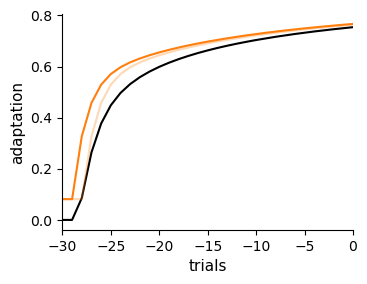

In [251]:
plt.figure(figsize=(ufigx, ufigy)
           )
myplot(huberdeau_rot_outs[0][:,:8],'k')
myplot(huberdeau_half_out[:,:8],'tab:orange')
myplot(huberdeau_half_out[:-1,:8],'tab:orange',alpha=0.3)
plt.ylabel('adaptation')
plt.xlabel('trials')
plt.xlim(-30, 0)

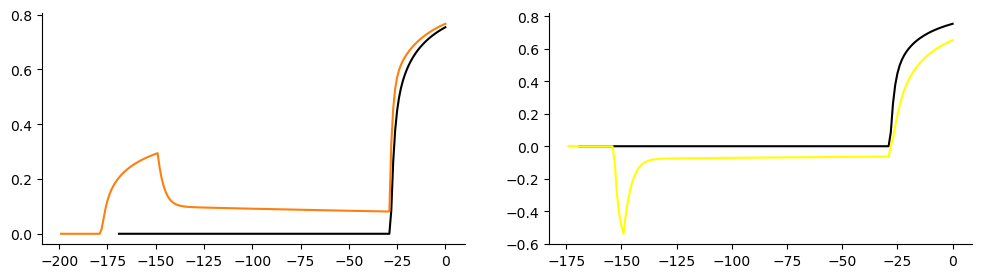

In [253]:
plt.figure(figsize=(12,3)
           )
plt.subplot(1,2,1)
myplot(huberdeau_rot_outs[0][:,:8],'k')
myplot(huberdeau_half_out[:,:8],'tab:orange')
# plt.xlim(-30, 0)
plt.subplot(1,2,2)
myplot(huberdeau_rot_outs[0][:,:8],'k')
myplot(huberdeau_anti_out[:,:8],'yellow')
# plt.xlim(-30, 0)

In [257]:
joiner_trial_num = [11,30,103,160]
eff_trials_min = 30 // 10
joiner_paradigms = {tt:np.array([0]*20+[1]*tt+[np.nan]*wait_time_equiv) for tt in joiner_trial_num}
joiner_paradigms['short_wait'] = np.array([0]*20+[1]*160+[np.inf]*3*eff_trials_min)
joiner_outs = {}
for tt in joiner_paradigms:
    joiner_outs[tt] = eval_single_wrap(model, joiner_paradigms[tt], args, paradigm_name=f'joiner_{tt}', record_internals=False, record_vectors=False)[0]



evaluating paradigm joiner_11 with 151 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm joiner_30 with 170 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm joiner_103 with 243 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm joiner_160 with 300 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm joiner_short_wait with 189 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


/tmp/ipykernel_3691958/1709533915.py:38: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


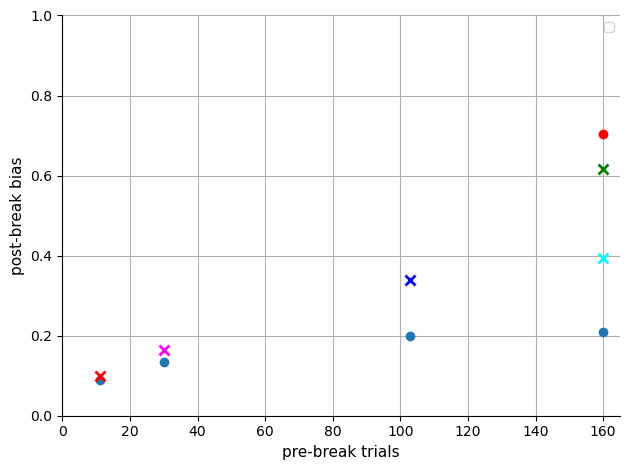

In [258]:
joiner_post_wait_outs = [joiner_outs[tt][-1,:] for tt in joiner_trial_num]
plt.figure()
# plt.plot(joiner_trial_num, np.mean(joiner_post_wait_outs, axis=1),'x')
plt.errorbar(joiner_trial_num, np.mean(joiner_post_wait_outs, axis=1), yerr=np.std(joiner_post_wait_outs, axis=1)/np.sqrt(len(joiner_post_wait_outs[0])), fmt='o')
# plt.plot([160], [np.mean(joiner_outs['short_wait'][-1,:])],'x')
plt.errorbar([160], [np.mean(joiner_outs['short_wait'][-1,:])], yerr=np.std(joiner_outs['short_wait'][-1,:])/np.sqrt(len(joiner_outs['short_wait'][0])), fmt='o', color='red')
plt.xlabel('pre-break trials')
plt.ylabel('post-break bias')
plt.xlim([0,170])
plt.ylim([0,1.05])
plt.grid()

import matplotlib.pyplot as plt

# Approximate symbol-centre coordinates extracted from the plot
points = {
    "red":     (11, 0.099),
    "magenta": (30, 0.165),
    "blue":    (103, 0.339),
    "green":   (160, 0.617),
    "cyan":    (160, 0.395),
}

x = [p[0] for p in points.values()]
y = [p[1] for p in points.values()]
colors = list(points.keys())

# plt.figure(figsize=(6, 4))

for color, (xi, yi) in points.items():
    plt.plot(xi, yi, marker="x", markersize=7, markeredgewidth=2,
             linestyle="None", color=color,zorder=8)

# plt.xlabel("Duration of the Initial Adaptation Period (Trials)")
# plt.ylabel("Value")
plt.xlim(0, 165)
plt.ylim(0, 1.0)
plt.legend()
plt.tight_layout()
plt.show()


In [260]:
wm_manipu_program = {'exp1': {'ref_paradigm':'wm_sr_baseline',    'noise_trial':596},
                     'exp2': {'ref_paradigm':'wmE2_sr_baseline',  'noise_trial':212},
                     'exp3': {'ref_paradigm':'wmE3_sr_baseline',  'noise_trial':576}}

In [261]:
perturbed_results = {}
wait_results = {}

n_perturbs = 100
n_waits = 30// 10 *3   
for exp in wm_manipu_program:
    ref_paradigm = wm_manipu_program[exp]['ref_paradigm']
    # at noise_trial, insert 30 trials with np.inf value to simulate working memory unroll
    noise_trial = wm_manipu_program[exp]['noise_trial']
    noise_seq = [np.inf]*n_perturbs
    wait_seq = [np.inf]*n_waits
    perturbed_paradigm = np.concatenate([playlist[ref_paradigm][:noise_trial], noise_seq, playlist[ref_paradigm][noise_trial:]])
    wait_paradigm = np.concatenate([playlist[ref_paradigm][:noise_trial], wait_seq, playlist[ref_paradigm][noise_trial:]])
    perturbed_out = eval_single_wrap(model, perturbed_paradigm, args, paradigm_name=f'{exp}_perturbed', record_internals=False, record_vectors=False)[0]
    wait_out = eval_single_wrap(model, wait_paradigm, args, paradigm_name=f'{exp}_wait', record_internals=False, record_vectors=False)[0]
    perturbed_results[exp] = (perturbed_out, noise_trial)
    wait_results[exp] = (wait_out, noise_trial)

evaluating paradigm exp1_perturbed with 888 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm exp1_wait with 797 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm exp2_perturbed with 462 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm exp2_wait with 371 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm exp3_perturbed with 868 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm exp3_wait with 777 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


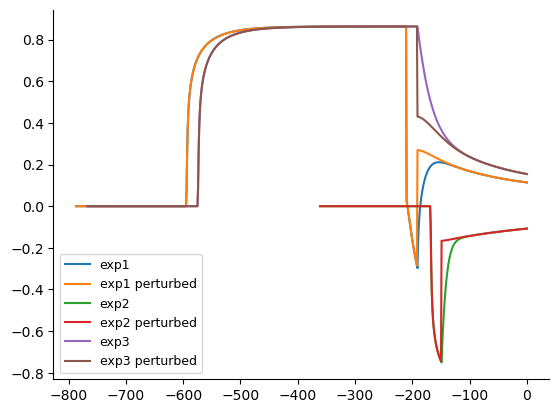

In [262]:
for exp in wm_manipu_program:
    myplot(ooo[wm_manipu_program[exp]['ref_paradigm']], label=exp)
    base_result = perturbed_results[exp][0]
    #remove the 30 noise trials from the perturbed result for plotting
    noise_trial = wm_manipu_program[exp]['noise_trial']
    base_result = np.concatenate([base_result[:noise_trial], base_result[noise_trial+n_perturbs:]])
    myplot(base_result, label=f'{exp} perturbed')
plt.legend()

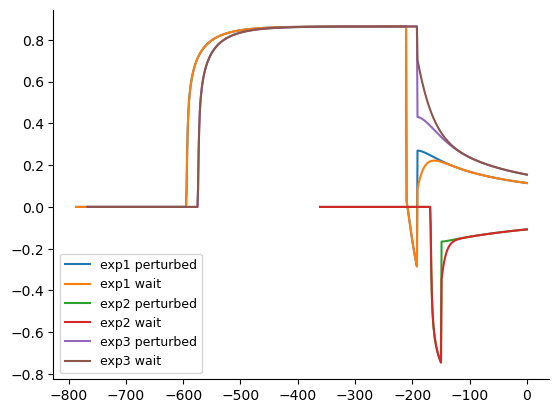

In [263]:
for exp in wm_manipu_program:
    # myplot(ooo[wm_manipu_program[exp]['ref_paradigm']], label=exp)
    base_result = perturbed_results[exp][0]
    #remove the 30 noise trials from the perturbed result for plotting
    noise_trial = wm_manipu_program[exp]['noise_trial']
    base_result = np.concatenate([base_result[:noise_trial], base_result[noise_trial+n_perturbs:]])
    wait_result = np.concatenate([wait_results[exp][0][:noise_trial], wait_results[exp][0][noise_trial+n_waits:]])  

    myplot(base_result, label=f'{exp} perturbed')
    myplot(wait_result, label=f'{exp} wait')
plt.legend()

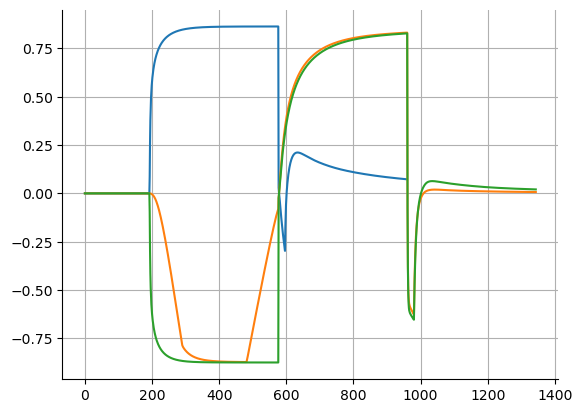

In [264]:
plt.plot(pooling_fun(ooo['pretrained_sr_baseline'], axis=1))
plt.plot(pooling_fun(ooo['pretrained_grad_sr'], axis=1))
plt.plot(pooling_fun(ooo['pretrained_sr'], axis=1))
plt.grid()

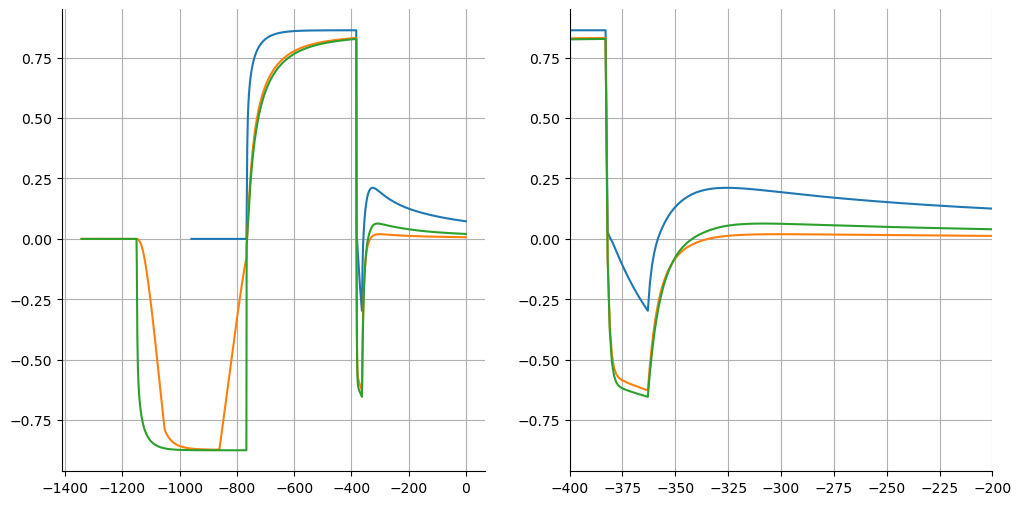

In [265]:


plt.figure(figsize=(12,6))
for ii in [1,2]:
    plt.subplot(1,2,ii)
    myplot(ooo['pretrained_sr_baseline'])
    myplot(ooo['pretrained_grad_sr'])
    myplot(ooo['pretrained_sr'])
    plt.grid()
    if ii==2:
        plt.xlim(-400,-200)

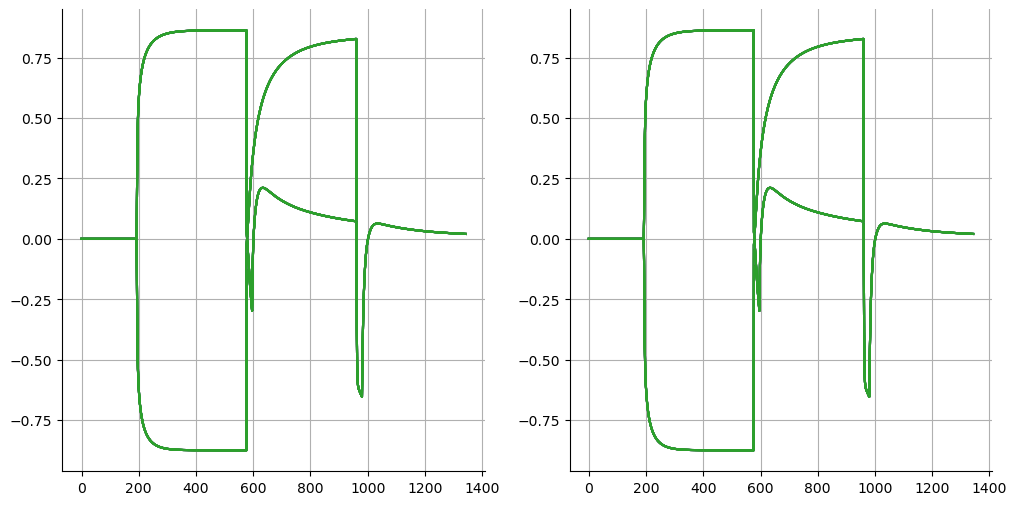

In [266]:
plt.figure(figsize=(12,6))
for ii in [1,2]:
    plt.subplot(1,2,ii)
    # plt.plot(ooo['pretrained_sr_baseline'])
    # plt.plot(ooo['pretrained_grad_sr'])
    plt.plot(ooo['pretrained_sr'][:,:8],'tab:purple')
    plt.plot(ooo['pretrained_sr'][:,8:],'tab:green')

    plt.plot(ooo['pretrained_sr_baseline'][:,:8],'tab:purple')
    plt.plot(ooo['pretrained_sr_baseline'][:,8:],'tab:green')
    plt.grid()
    if ii==2:
        # plt.xlim(-400,-200)
        pass

/scratch/ar2342/miconda3/envs/py_frogs/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


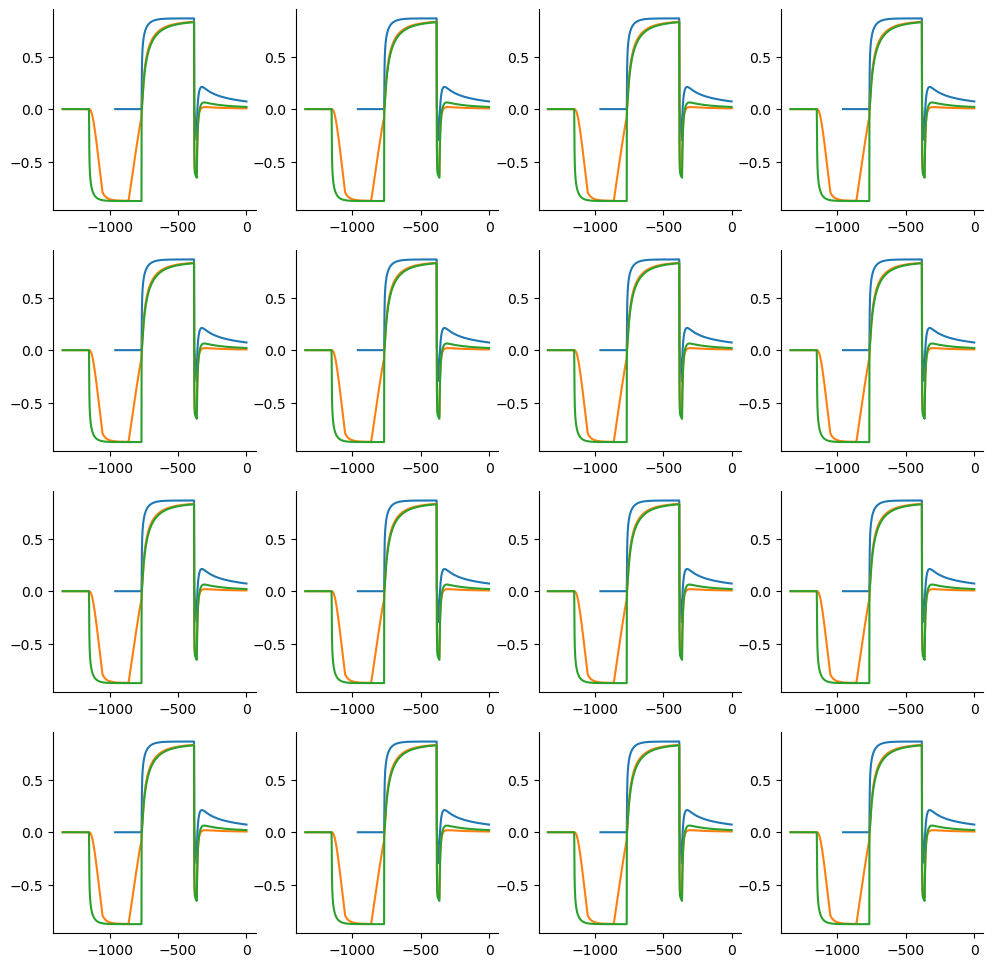

In [267]:

plt.figure(figsize=(12,12))
for s in range(16):
    plt.subplot(4,4,s+1)
    # plt.plot(ooo['pretrained_sr_baseline'])
    # plt.plot(ooo['pretrained_grad_sr'])
    myplot(ooo['pretrained_sr_baseline'][:,[s]])
    myplot(ooo['pretrained_grad_sr'][:,[s]])
    myplot(ooo['pretrained_sr'][:,[s]])



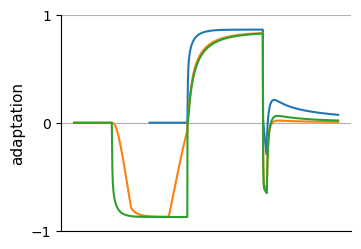

In [268]:
plt.figure(figsize=(ufigx,ufigy))
plt.rcParams.update(rcConf)
myplot(ooo['pretrained_sr_baseline'])
myplot(ooo['pretrained_grad_sr'])
myplot(ooo['pretrained_sr'])
plt.yticks([-1,0,1])
plt.ylabel('adaptation')
plt.xticks([])

plt.grid()
# plt.savefig('figPeknyADAv1.svg',format='svg') 


In [269]:
T=300
channel_frogs_paradigm = np.array([0]*20+[t/T for t in range(1, T)]+[np.nan]*400)
channel_anti_frogs_paradigm = np.array([0]*20+[1]*T+[np.nan]*400)

channel_frogsEXT_paradigm = np.array([0]*20+[t/T for t in range(1, T)]+[1]*T+[np.nan]*400)
channel_anti_frogsEXT_paradigm = np.array([0]*20+[1]*T+[1]*T+[np.nan]*400)

channel_frogs_out = eval_single_wrap(model, channel_frogs_paradigm, args, paradigm_name='channel_frogs', record_internals=False, record_vectors=False)[0]
channel_anti_frogs_out = eval_single_wrap(model, channel_anti_frogs_paradigm, args, paradigm_name='channel_anti_frogs', record_internals=False, record_vectors=False)[0]
channel_frogsEXT_out = eval_single_wrap(model, channel_frogsEXT_paradigm, args, paradigm_name='channel_frogsEXT', record_internals=False, record_vectors=False)[0]
channel_anti_frogsEXT_out = eval_single_wrap(model, channel_anti_frogsEXT_paradigm, args, paradigm_name='channel_anti_frogsEXT', record_internals=False, record_vectors=False)[0]   

evaluating paradigm channel_frogs with 719 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm channel_anti_frogs with 720 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm channel_frogsEXT with 1019 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm channel_anti_frogsEXT with 1020 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


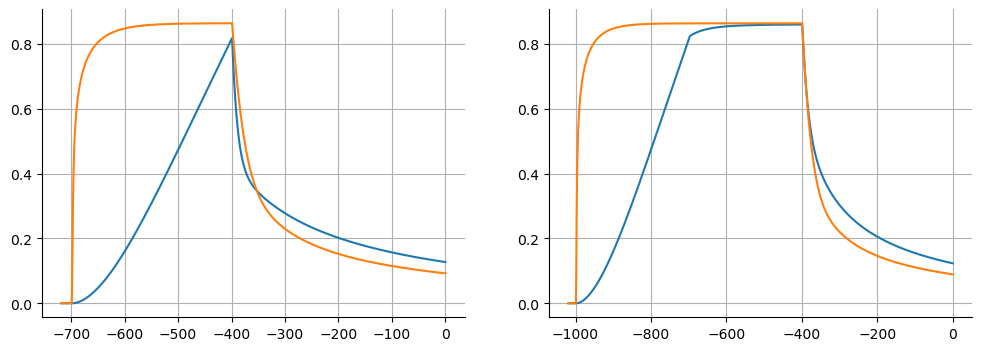

In [270]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
myplot(channel_frogs_out[:,:8])
myplot(channel_anti_frogs_out[:,:8])
plt.grid()
plt.subplot(1,2,2)
myplot(channel_frogsEXT_out[:,:8])
myplot(channel_anti_frogsEXT_out[:,:8])
plt.grid()


evaluating paradigm distab with 829 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm distab_ctrl with 829 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


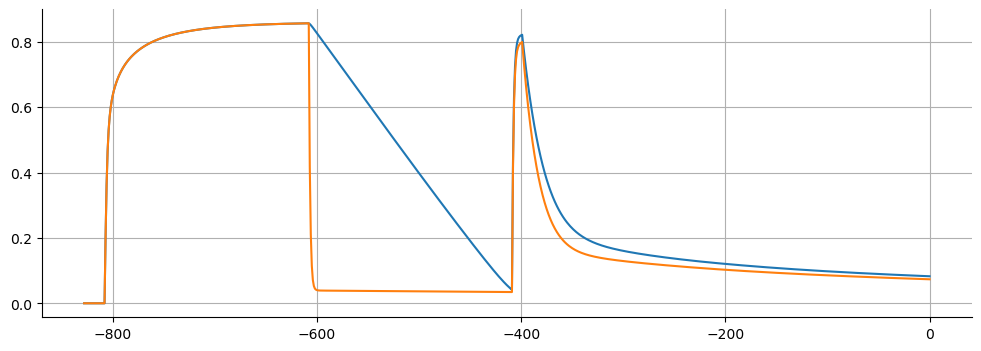

In [ ]:
T=200
distab_paradigm = np.array([0]*20+[1]*200+[(T-t)/T for t in range(1, T)]+ [1]*10+[np.nan]*400)
distab_ctrl_paradigm = np.array([0]*20+[1]*200+[0*(T-t)/T for t in range(1, T)]+ [1]*10+[np.nan]*400)
distab_out = eval_single_wrap(model, distab_paradigm, args, paradigm_name='distab', record_internals=False, record_vectors=False)[0]
distab_ctrl_out = eval_single_wrap(model, distab_ctrl_paradigm, args, paradigm_name='distab_ctrl', record_internals=False, record_vectors=False)[0]
plt.figure(figsize=(12,4))
myplot(distab_out[:,:8])
myplot(distab_ctrl_out[:,:8])
plt.grid()


evaluating paradigm very_fixed with 820 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm very_fixed_ctrl with 620 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm very_fixed_ctrl2 with 520 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


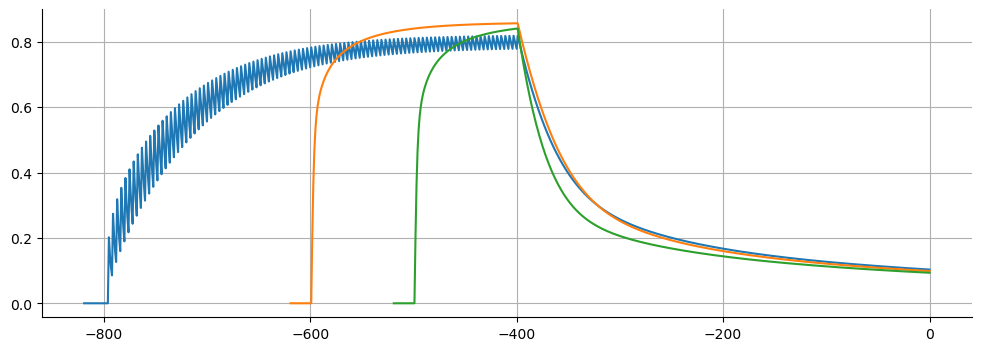

In [ ]:
very_fixed_paradigm = np.array([0]*20+[np.nan,np.nan,np.nan,1]*100+[np.nan]*400)
very_fixed_ctrl_paradigm = np.array([0]*20+[1,]*200+[np.nan]*400)
very_fixed_ctrl_paradigm2 = np.array([0]*20+[1,]*100+[np.nan]*400)

very_fixed_out = eval_single_wrap(model, very_fixed_paradigm, args, paradigm_name='very_fixed', record_internals=False, record_vectors=False)[0]
very_fixed_ctrl_out = eval_single_wrap(model, very_fixed_ctrl_paradigm, args, paradigm_name='very_fixed_ctrl', record_internals=False, record_vectors=False)[0]
very_fixed_ctrl_out2 = eval_single_wrap(model, very_fixed_ctrl_paradigm2, args, paradigm_name='very_fixed_ctrl2', record_internals=False, record_vectors=False)[0]
plt.figure(figsize=(12,4))
myplot(very_fixed_out[:,:8])
myplot(very_fixed_ctrl_out[:,:8])
myplot(very_fixed_ctrl_out2[:,:8])
plt.grid()

In [275]:
import copy
args_ = copy.deepcopy(args)
args_.channel_trial_extra_error = 2.7/30*1.5 # 5./100 #2.7/30.
args.noise_injection_node = 'u'
model_ = BatchedElboGenerativeModelTopMulti(device=device, args=args_,
                                           **({'fudge': args_.fudge} if hasattr(args_, 'fudge') else {})).to(device)
model_.get_biases_and_w_in(args_.n, device=device)
model_.load_state_dict(best_model_state_dict,strict=False)

_IncompatibleKeys(missing_keys=[], unexpected_keys=['sigma_b', 'input_scale', 'u_feedback_scale', 'weight_decay_exp', 'weight_learning_exp', 'q_scale', 'bias_lr', 'tauqlpf_m1', 'tauylpf_m1', 'tauelpf_m1', 'direct_injection_scale'])

In [276]:
# foo = eval_single_paradigm(model_, playlist['vaswFixedErr'], args, paradigm_name='vaswFixedErr', record_internals=False)
# foo = [foo_.detach().cpu().numpy() for foo_ in foo[0]]
# foo = np.array(foo)

def eval_single_wrap(model, paradigm, args, paradigm_name=None, record_internals=False, record_vectors=False):
    outputs, internals = eval_single_paradigm(model, paradigm, args, paradigm_name, record_internals, record_vectors)
    outputs = [o.detach().cpu().numpy() for o in outputs]
    outputs = np.array(outputs)
    if record_internals:
        # for k in internals:
        #     internals[k] = {kk: vv.detach().cpu().numpy() for kk, vv in internals[k].items()}
        return outputs, internals
    return outputs, None

foo, _ = eval_single_wrap(model_, playlist['vaswFixedErr'], args, paradigm_name='vaswFixedErr', record_internals=False)
#replace np.nan with np.inf in the paradigm for disabling plasticity
vaswFixedErr_infs = np.where(np.isnan(playlist['vaswFixedErr']), np.inf, playlist['vaswFixedErr'])
foo_infs, _ = eval_single_wrap(model_, vaswFixedErr_infs, args, paradigm_name='vaswFixedErr_nans', record_internals=False)

evaluating paradigm vaswFixedErr with 300 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])
evaluating paradigm vaswFixedErr_nans with 300 steps
noises shape: torch.Size([16]), ys shape: torch.Size([16])


(-0.5, 2.5)

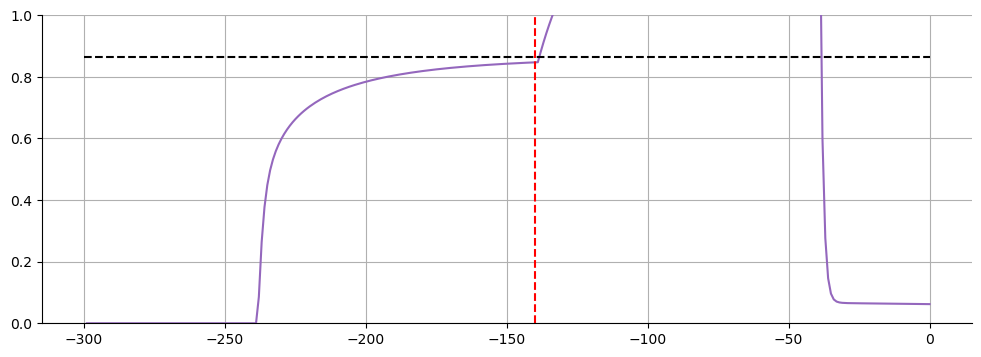

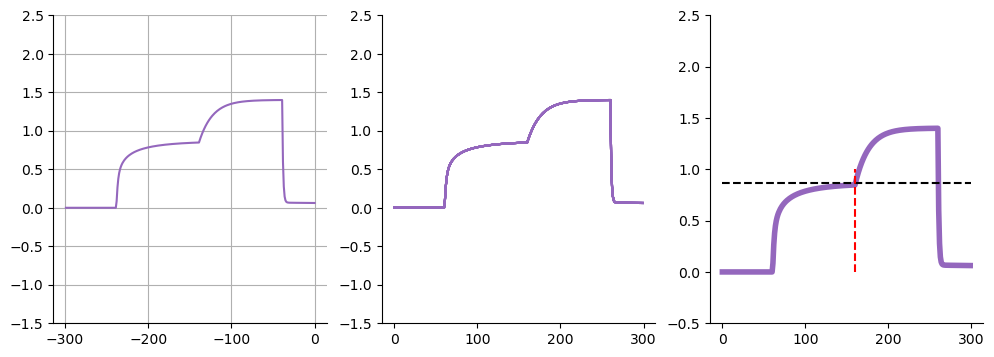

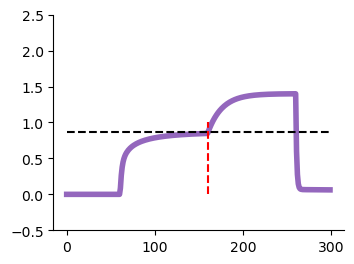

In [277]:
foo = foo_infs
plt.figure(figsize=(12,4))
myplot(foo, 'tab:purple')
plt.plot([-300,0], (1-args_.channel_trial_extra_error)*np.ones(2), 'k--')
plt.plot([-140,-140], [0,1], 'r--')

plt.grid()
plt.ylim(0, 1.0)
# foo = foo[:,8:]
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
myplot(foo, 'tab:purple')
plt.ylim(-1.5, 2.5)
plt.grid()
plt.subplot(1,3,2)
plt.plot(foo, 'tab:purple')
plt.ylim(-1.5, 2.5)
plt.subplot(1,3,3)
plt.plot(foo, 'tab:gray', alpha=0.3)
plt.plot(np.nanmedian(foo, axis=1), 'tab:purple', linewidth=4)
plt.plot([0,300], (1-args_.channel_trial_extra_error)*np.ones(2), 'k--')
plt.plot([-140+300,-140+300], [0,1], 'r--')
plt.ylim(-0.5, 2.5)

plt.figure(figsize=(ufigx,ufigy))
plt.plot(foo, 'tab:gray', alpha=0.3)
plt.plot(np.nanmedian(foo, axis=1), 'tab:purple', linewidth=4)
plt.plot([0,300], (1-args_.channel_trial_extra_error)*np.ones(2), 'k--')
plt.plot([-140+300,-140+300], [0,1], 'r--')
plt.ylim(-0.5, 2.5)


In [273]:
playlist['pekny_BgNRbase']

array([ 0.,  0.,  0., ..., nan, nan, nan])

In [274]:
def three_state_noise(size):
    #generate noise that is either -1, 0, or 1 with equal probability
    return np.random.choice([-1, 0, 1], size=size)

In [ ]:
# noisy_trials = []
# noises = []
# noise_start = -364-20
# noise_end = -364
# for ii in range(1,100):
#     this_paradigm = playlist['pekny_BgNRbase'] + 0.
#     this_noise = three_state_noise(size=np.abs(noise_end-noise_start))
#     this_paradigm[noise_start:noise_end] = this_paradigm[noise_start:noise_end] + this_noise
#     foo, _ = eval_single_wrap(model, this_paradigm, args, paradigm_name=f'pekny_BgNRbase_noisy_{ii}', record_internals=False)
#     # noisy_trials.append(foo)
#     # noises.append(this_noise)

In [ ]:
uu = np.array([three_state_noise(size=np.abs(noise_end-noise_start)) for i in range(10000)])
uu.mean(), uu.std()

(-0.0055, 0.8155855258647006)

In [ ]:
this_paradigm[-370:-363]

array([ 1.,  1.,  0.,  0.,  0., -1., nan])

In [ ]:
# myplot(ooo['pekny_BgN'], 'tab:purple')
# myplot(ooo['pekny_BgNRbase'], 'tab:purple')
# myplot(np.mean(noisy_trials, axis=0), 'tab:green')

In [ ]:
# for noisy_trial in noisy_trials[:10]:
#     myplot(noisy_trial, 'tab:gray', add_sem=False)
# myplot(np.mean(noisy_trials, axis=0), 'tab:green', add_sem=False)

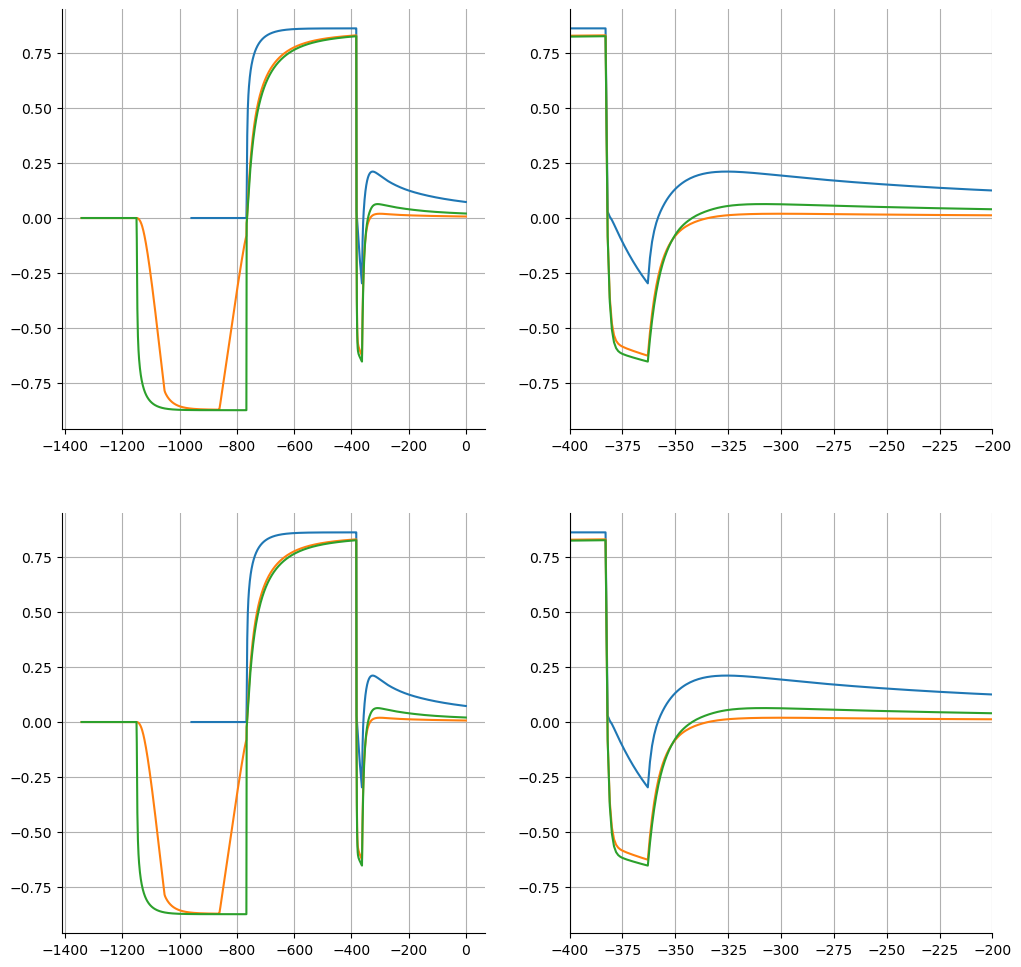

In [278]:
plt.figure(figsize=(12,12))
for ii in [1,2]:
    plt.subplot(2,2,ii)
    myplot(ooo['pretrained_sr_baseline'],subj=[0,8])
    myplot(ooo['pretrained_grad_sr'],subj=[0,8])
    myplot(ooo['pretrained_sr'],subj=[0,8])
    plt.grid()
    if ii==2:
        plt.xlim(-400,-200)

    plt.subplot(2,2,ii+2)
    myplot(ooo['pretrained_sr_baseline'],subj=[8,16])
    myplot(ooo['pretrained_grad_sr'],subj=[8,16])
    myplot(ooo['pretrained_sr'],subj=[8,16])
    plt.grid()
    if ii==2:
        plt.xlim(-400,-200)

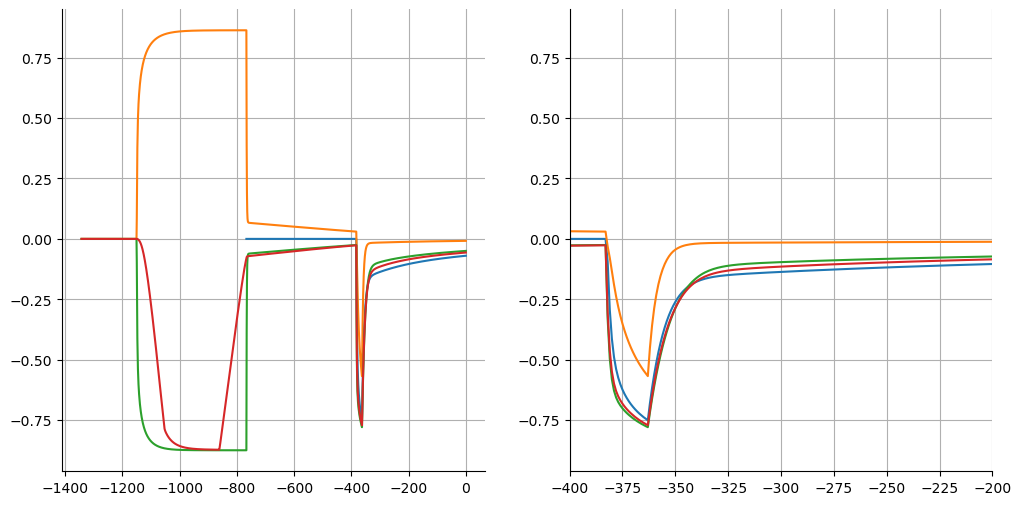

In [279]:
plt.figure(figsize=(12,6))
for ii in [1,2]:
    plt.subplot(1,2,ii)
    myplot(ooo['pekny_Nb'])
    myplot(ooo['pekny_ANb'])
    myplot(ooo['pekny_BNb'])
    myplot(ooo['pekny_BgNb'])
    plt.grid()
    if ii==2:
        plt.xlim(-400,-200)

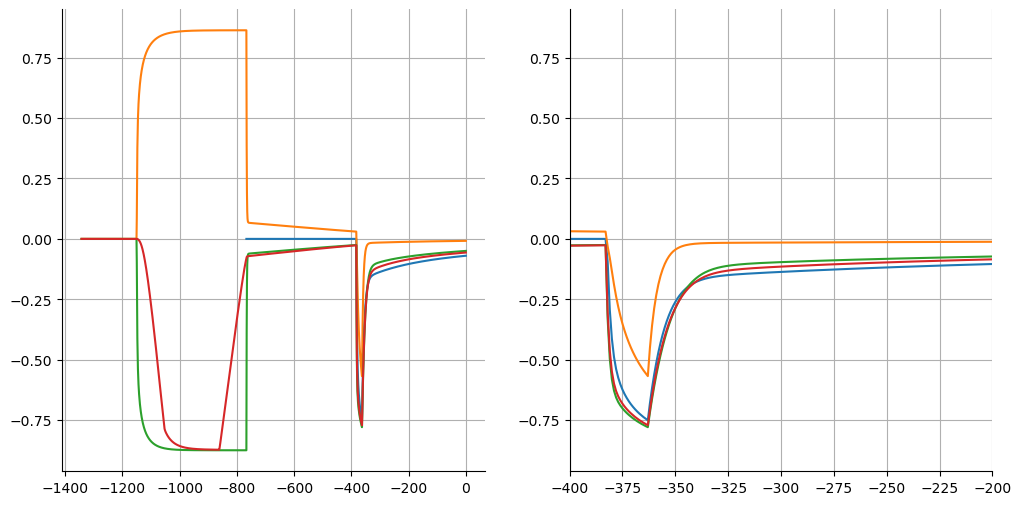

In [281]:
plt.figure(figsize=(12,6))
for ii in [1,2]:
    plt.subplot(1,2,ii)
    myplot(ooo['pekny_Nb'], subj=[0,8])
    myplot(ooo['pekny_ANb'], subj=[0,8])
    myplot(ooo['pekny_BNb'], subj=[0,8])
    myplot(ooo['pekny_BgNb'], subj=[0,8])
    plt.grid()
    if ii==2:
        plt.xlim(-400,-200)

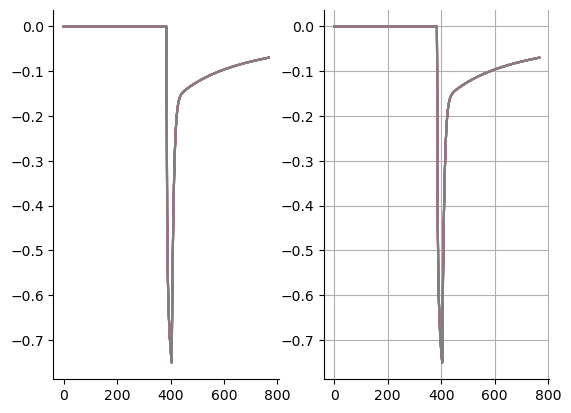

In [282]:
plt.subplot(1, 2, 1)
plt.plot(ooo['pekny_Nb'][:,:8])
plt.subplot(1, 2, 2)
plt.plot(ooo['pekny_Nb'][:,8:])
# plt.ylim(-0.1,0.1)
plt.grid()


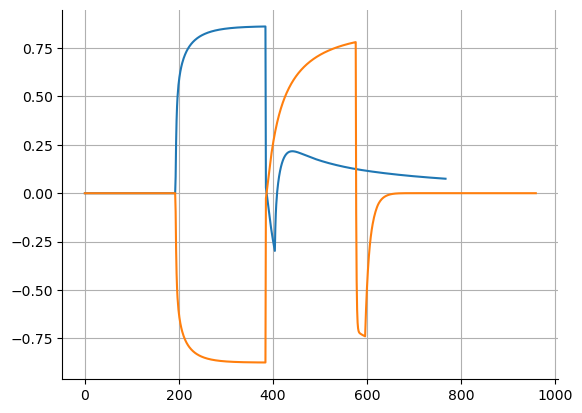

In [283]:
plt.plot(pooling_fun(ooo['pretrained_sr_baseline0p5'], axis=1))
plt.plot(pooling_fun(ooo['pretrained_sr0p5'], axis=1))
plt.grid()

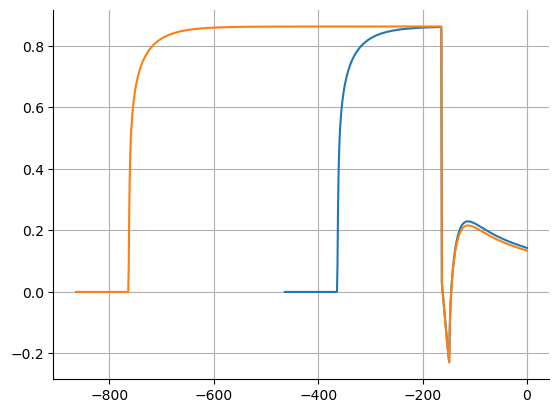

In [284]:
myplot(ooo['overlearning_baseline'])
myplot(ooo['overlearning'])
plt.grid()

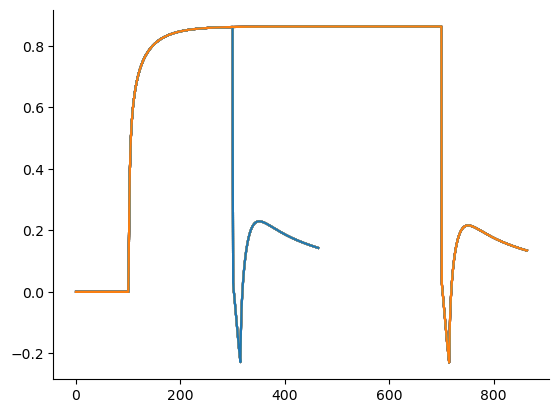

In [285]:
for ii in range(16):
    plt.plot(ooo['overlearning_baseline'][:,ii])
    plt.plot(ooo['overlearning'][:,ii])

In [ ]:
from optimise_clnn import load_subject_data

extend = 0  # 1000
# probe_values = np.arange(-1.5, 1.5 + 0.05 / 2, 0.05, dtype=np.float32)
probe_values = np.arange(-0.5, 1.5 + 0.05 / 2, 0.025, dtype=np.float32)
participant_ids = [(k % 8) + 1 for k in range(subjs)]

paradigm_file_templates = {
    'evoked': '/homes/ar2342/frogs_project/data/COIN_data/trial_data_evoked_recovery_participant{participant_id}.csv',
    'spontaneous': '/homes/ar2342/frogs_project/data/COIN_data/trial_data_spontaneous_recovery_participant{participant_id}.csv',
}

paradigm_data = {}

for paradigm_name, csv_template in paradigm_file_templates.items():
    ys_list_local = []
    a_exp_list_local = []

    for participant_id in participant_ids:
        csv_path = csv_template.format(participant_id=participant_id)
        experimental_data = load_subject_data(csv_path)
        a_exp_list_local.append(np.asarray(experimental_data[0], dtype=np.float32))
        ys_list_local.append(np.asarray(experimental_data[1], dtype=np.float32))

    lengths = [len(y) for y in ys_list_local]
    assert len(set(lengths)) == 1, (
        f'Expected same {paradigm_name} paradigm length for all participants, got {lengths}'
    )

    if extend > 0:
        ys_list_local = [
            np.concatenate([y, np.full(extend, np.nan, dtype=np.float32)]) for y in ys_list_local
        ]
        a_exp_list_local = [
            np.concatenate([a, np.full(extend, np.nan, dtype=np.float32)]) for a in a_exp_list_local
        ]

    ys_np = np.stack(ys_list_local, axis=0)
    a_exp_np = np.stack(a_exp_list_local, axis=0)

    ys_tensor = torch.tensor(ys_np, device=next(model.parameters()).device)
    noise_tensor = torch.zeros_like(ys_tensor)
    ys_time_list = [ys_tensor[:, t_idx] for t_idx in range(ys_tensor.shape[1])]
    noise_time_list = [noise_tensor[:, t_idx] for t_idx in range(noise_tensor.shape[1])]

    outputs_best_seed = None
    inoutmaps_best_seed = []

    model.eval()
    with torch.no_grad():
        for probe_value in probe_values:
            probing_vec = torch.full((args.bs,), probe_value, device=ys_tensor.device)
            outputs_, inoutmaps_ = model.f(
                args.n,
                noise_time_list,
                ys_time_list,
                args.model,
                qs=None,
                record_inoutmaps=True,
                inoutmaps_probing_vec=probing_vec,
            )

            if outputs_best_seed is None:
                outputs_best_seed = np.stack([z.cpu().numpy() for z in outputs_], axis=0)

            inoutmaps_best_seed.append(
                np.stack([hidden.cpu().numpy() for hidden, _ in inoutmaps_], axis=0)
            )

    inoutmaps_best_seed = np.stack(inoutmaps_best_seed, axis=0)
    inoutmaps_best_seed = np.moveaxis(inoutmaps_best_seed, 0, -1)

    paradigm_data[paradigm_name] = {
        'ys': ys_np,
        'a_exp': a_exp_np,
        'outputs_best_seed': outputs_best_seed,
        'inoutmaps_best_seed': inoutmaps_best_seed,
    }

# Backward-compatible names used later in notebook
evoked_ys = paradigm_data['evoked']['ys']
evoked_a_exp = paradigm_data['evoked']['a_exp']
evoked_outputs_best_seed = paradigm_data['evoked']['outputs_best_seed']
evoked_inoutmaps_best_seed = paradigm_data['evoked']['inoutmaps_best_seed']

spontaneous_ys = paradigm_data['spontaneous']['ys']
spontaneous_a_exp = paradigm_data['spontaneous']['a_exp']
spontaneous_outputs_best_seed = paradigm_data['spontaneous']['outputs_best_seed']
spontaneous_inoutmaps_best_seed = paradigm_data['spontaneous']['inoutmaps_best_seed']

for paradigm_name in ['evoked', 'spontaneous']:
    print(f"{paradigm_name}_ys shape:", paradigm_data[paradigm_name]['ys'].shape)
    print(
        f"{paradigm_name}_outputs_best_seed shape:",
        paradigm_data[paradigm_name]['outputs_best_seed'].shape,
    )
    print(
        f"{paradigm_name}_inoutmaps_best_seed shape:",
        paradigm_data[paradigm_name]['inoutmaps_best_seed'].shape,
    )

print('probe_values shape:', probe_values.shape)

evoked_ys shape: (16, 340)
evoked_outputs_best_seed shape: (340, 16)
evoked_inoutmaps_best_seed shape: (340, 16, 81)
spontaneous_ys shape: (16, 340)
spontaneous_outputs_best_seed shape: (340, 16)
spontaneous_inoutmaps_best_seed shape: (340, 16, 81)
probe_values shape: (81,)


In [ ]:
%history

# load a matrix from a space-separated file and show it as an image
import sys
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/experimental/optim/')
sys.path.append('/homes/ar2342/one_more_dir/contextual_frogs/')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import os
from stat_utils import bic_gaussian_from_rmse
from model_utils import force_model_params, migrate_output_scale_to_input_scale_state_dict



def compute_k_params(model_state_dict, 
                     exclude_by_startwith=['_'], 
                     exclude_by_name=['sigma_x'], 
                     count_for_one={'sigma_b', 'direct_injection_scale','output_scale','u_feedback_scale', 
                                    'x_slow_alpha', 'x_fast_gain', 'x_fast_alpha'}):
    k_params = 0
    for key in model_state_dict:
        if any([key.startswith(excl) for excl in exclude_by_startwith]):
            continue
        if key in exclude_by_name:
            continue
      

In [ ]:
sbj=3

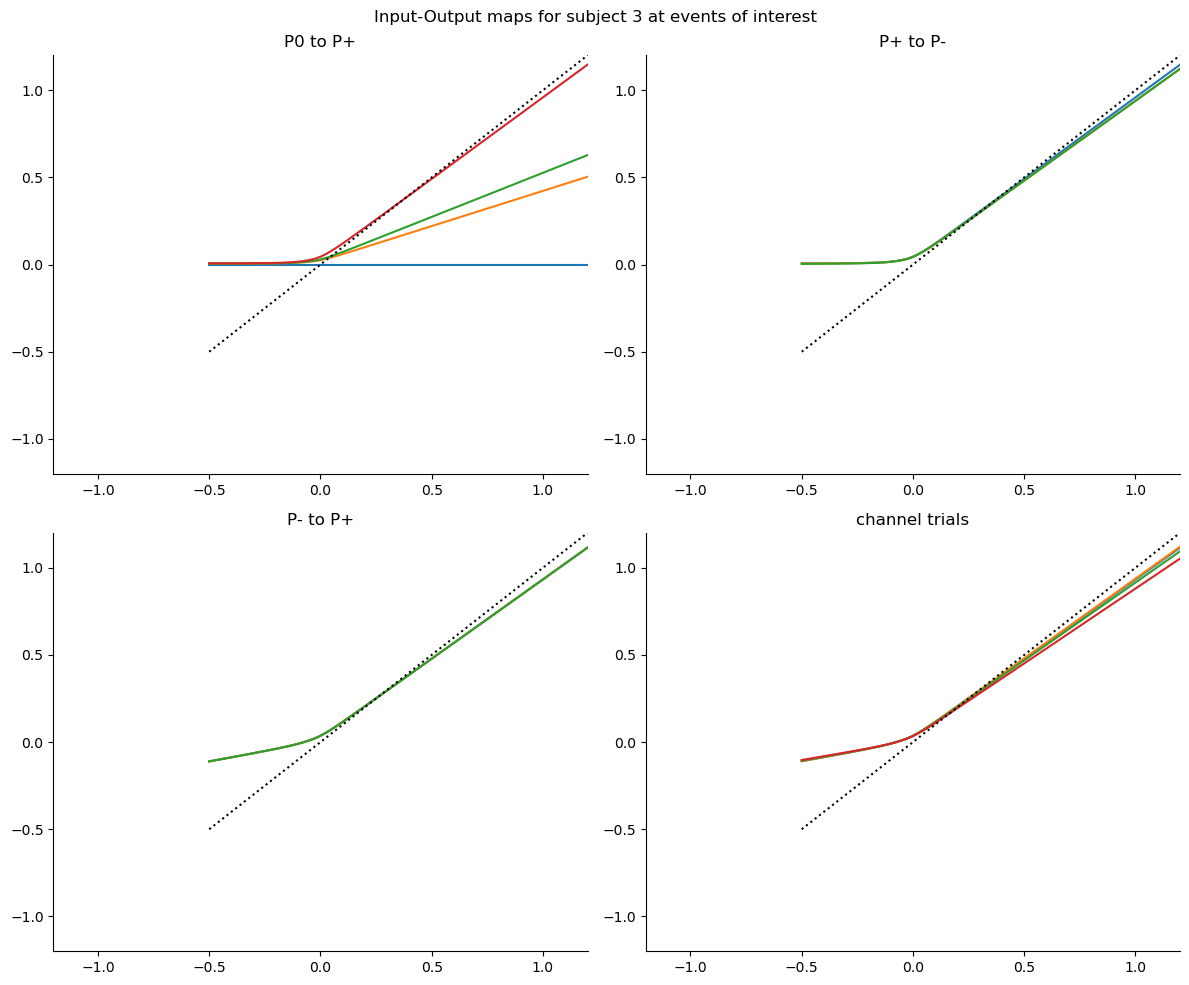

In [ ]:
# same but now a subplot per each group of events of interest
event_groups = {
    'P0 to P+': [50, 51, 52, 175],
    'P+ to P-': [175, 176, 177],
    'P- to P+': [190, 191, 192],
    'channel trials': [193, 194, 250, 339],
}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (event_group_name, tvec) in zip(axes.flat, event_groups.items()):
    for t in tvec:
        ax.plot(probe_values, evoked_inoutmaps_best_seed[t,sbj,:])
    ax.plot(probe_values,probe_values, 'k:')
    ax.set_xlim([-1.2, 1.2])
    ax.set_ylim([-1.2, 1.2])
    ax.set_title(event_group_name)
fig.suptitle(f'Input-Output maps for subject {sbj} at events of interest')
fig.tight_layout()

In [289]:
def find_fixed_points(x_values, y_values, tol=1e-3, selection='closest_to_zero'):
    x_values = np.asarray(x_values, dtype=np.float32)
    y_values = np.asarray(y_values, dtype=np.float32)

    if y_values.ndim == 1:
        y_values = y_values[None, :]

    fixed_points = []
    for y in y_values:
        diffs = y - x_values
        candidates = []

        close_idx = np.where(np.abs(diffs) <= tol)[0]
        candidates.extend(x_values[close_idx].tolist())

        sign_changes = np.where(np.signbit(diffs[:-1]) != np.signbit(diffs[1:]))[0]
        for idx in sign_changes:
            x0, x1 = x_values[idx], x_values[idx + 1]
            d0, d1 = diffs[idx], diffs[idx + 1]
            # if np.isclose(d0, d1):
            #     crossing = 0.5 * (x0 + x1)
            # else:
            crossing = x0 - d0 * (x1 - x0) / (d1 - d0)
            candidates.append(float(crossing))

        if not candidates:
            fixed_points.append(np.nan)
            continue

        candidates = np.array(sorted(set(np.round(candidates, 8))), dtype=np.float32)
        if selection == 'closest_to_zero':
            fixed_points.append(candidates[np.argmin(np.abs(candidates))])
        elif selection == 'first':
            fixed_points.append(candidates[0])
        elif selection == 'last':
            fixed_points.append(candidates[-1])
        else:
            raise ValueError(f'Unknown selection mode: {selection}')

    return np.asarray(fixed_points, dtype=np.float32)


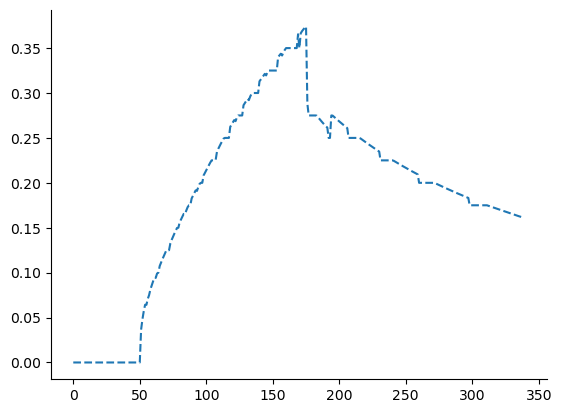

In [ ]:
event_group_name = 'channel trials'
# tvec = np.a
fixed_points_over_time = find_fixed_points(
    probe_values,
    evoked_inoutmaps_best_seed[:, sbj, :],
)
plt.plot( fixed_points_over_time, '--')
# plt.title(f'Fixed points for {event_group_name} (subject {sbj})')

In [287]:
def eval_paradigm_with_inoutmaps(model, args, paradigm, probe_values, *, name=None):
    if name is not None:
        print(f"evaluating {name} with {len(paradigm)} steps")

    device = next(model.parameters()).device
    ys_tensor = torch.tensor(paradigm, device=device).unsqueeze(0).repeat(args.bs, 1)
    noise_tensor = torch.zeros_like(ys_tensor)
    ys_list = [ys_tensor[:, t_idx] for t_idx in range(ys_tensor.shape[1])]
    noise_list = [noise_tensor[:, t_idx] for t_idx in range(noise_tensor.shape[1])]

    outputs = None
    inoutmaps = []

    model.eval()
    with torch.no_grad():
        for probe_value in probe_values:
            probing_vec = torch.full((args.bs,), float(probe_value), device=device)
            outputs_raw, inoutmaps_raw = model.f(
                args.n,
                noise_list,
                ys_list,
                args.model,
                qs=None,
                record_inoutmaps=True,
                inoutmaps_probing_vec=probing_vec,
            )

            if outputs is None:
                outputs = np.stack([
                    z.detach().cpu().numpy().reshape(-1) for z in outputs_raw
                ], axis=0)

            inoutmaps.append(np.stack([
                hidden.detach().cpu().numpy().reshape(-1) for hidden, _ in inoutmaps_raw
            ], axis=0))

    inoutmaps = np.stack(inoutmaps, axis=0)
    inoutmaps = np.moveaxis(inoutmaps, 0, -1)
    fixed_points = np.stack([
        find_fixed_points(probe_values, inoutmaps[:, subj_idx, :])
        for subj_idx in range(outputs.shape[1])
    ], axis=1)

    trial_idx = np.arange(len(paradigm))
    output_mean = outputs.mean(axis=1)
    fixed_point_mean = np.nanmean(fixed_points, axis=1)

    return {
        'name': name,
        'paradigm': paradigm,
        'outputs': outputs,
        'output_mean': output_mean,
        'inoutmaps': inoutmaps,
        'fixed_points': fixed_points,
        'fixed_point_mean': fixed_point_mean,
        'trial_idx': trial_idx,
    }


In [290]:
# inout map analysis for paradigms 'pretrained_sr_baseline','pretrained_grad_sr','pretrained_sr'
# plot at time -364; -384; -768
my_probe_values = np.arange(-1.5, 1.5 + 0.05 / 2, 0.025, dtype=np.float32)

recorded_paradigms = ['pretrained_sr_baseline', 'pretrained_grad_sr', 'pretrained_sr']
requested_timepoints = [-364, -384, -768]
records = {}
for paradigm in recorded_paradigms:
    records[paradigm] = eval_paradigm_with_inoutmaps(model, args, np.float32(playlist[paradigm]), my_probe_values)

In [291]:
records[paradigm].keys(), records[paradigm]['fixed_points'].shape

(dict_keys(['name', 'paradigm', 'outputs', 'output_mean', 'inoutmaps', 'fixed_points', 'fixed_point_mean', 'trial_idx']),
 (1344, 16))

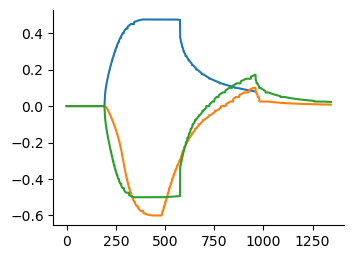

In [292]:
plt.figure(figsize=(ufigx,ufigy))
# plt.subplot(1,3,1)
for ii, paradigm in enumerate(recorded_paradigms):
    # plt.subplot(1,3,ii+1)
    # best_model_state_dict['input_scale'].numpy()

    # plt.plot(records[paradigm]['fixed_points'].mean(axis=1))
    plt.plot(records[paradigm]['fixed_points'].mean(axis=1))

    # plt.plot(my_probe_values,1./16*records[paradigm]['inoutmaps'][t].T @ best_model_state_dict['input_scale'].numpy())


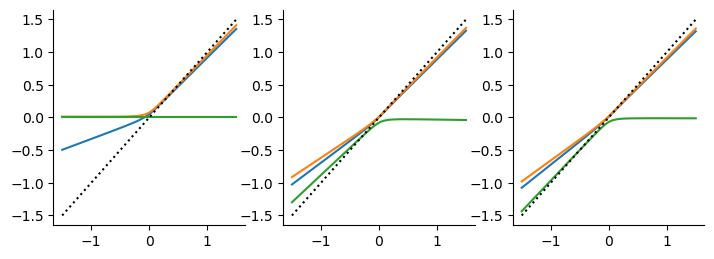

In [293]:
plt.figure(figsize=(3*ufigy,ufigy))
plt.subplot(1,3,1)
for ii, paradigm in enumerate(recorded_paradigms):
    plt.subplot(1,3,ii+1)

    for t in requested_timepoints:
        plt.plot(my_probe_values,records[paradigm]['inoutmaps'][t].mean(axis=0))
        # plt.plot(my_probe_values,1./16*records[paradigm]['inoutmaps'][t].T @ best_model_state_dict['input_scale'].numpy())
    plt.plot(my_probe_values,my_probe_values,'k:')

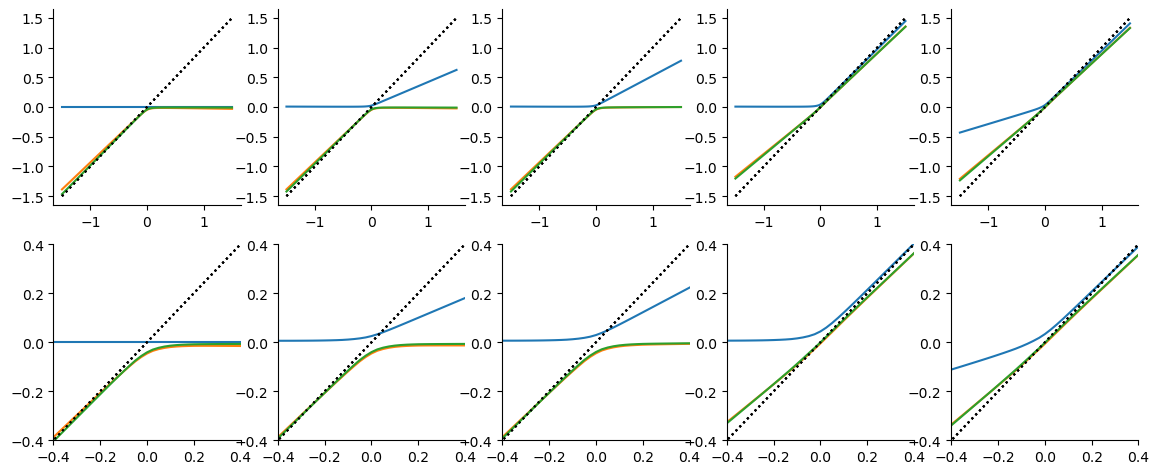

In [ ]:
extended_requested_timepoints = [-768, -767, -766, -384, -364, ]
pp = len(extended_requested_timepoints)
plt.figure(figsize=(pp*ufigy,2*ufigy))
plt.subplot(2,pp,1)
for ii, paradigm in enumerate(recorded_paradigms):

    for jj, t in enumerate(extended_requested_timepoints):
        plt.subplot(2,pp,jj+1)
        mean_inout = 1./16*records[paradigm]['inoutmaps'][t].T @ best_model_state_dict['input_scale'].numpy()
        # plt.plot(my_probe_values,records[paradigm]['inoutmaps'][t].mean(axis=0))
        plt.plot(my_probe_values,mean_inout)
        plt.plot(my_probe_values,my_probe_values,'k:')

        plt.subplot(2,pp,pp+jj+1)
        plt.plot(my_probe_values,mean_inout)
        plt.plot(my_probe_values,my_probe_values,'k:')

        plt.xlim(-0.4,0.4)
        plt.ylim(-0.4,0.4)



In [ ]:
# for sss in range(16):
#     plt.figure(figsize=(3*ufigy,ufigy))
#     plt.subplot(1,3,1)
#     for ii, paradigm in enumerate(recorded_paradigms):
#         plt.subplot(1,3,ii+1)

#         for t in requested_timepoints:
#             plt.plot(my_probe_values,records[paradigm]['inoutmaps'][t,sss])
#             # plt.plot(my_probe_values,1./16*records[paradigm]['inoutmaps'][t].T @ best_model_state_dict['input_scale'].numpy())
#         plt.plot(my_probe_values,my_probe_values,'k:')

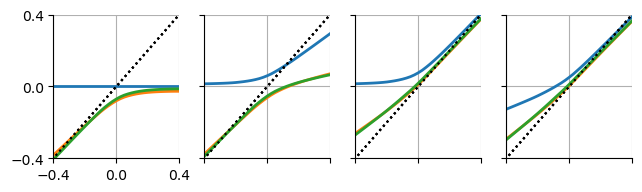

In [307]:
savedir = '/homes/ar2342/one_more_dir/contextual_frogs/gnu_fig_data/fitSRER_v1/fullRepertoires/aveOfSubj_v1/'
sss=0
plt.rcParams.update(rcConf)
plt.figure(figsize=(4*ufigy/1.5,ufigy/1.5))
requested_timepoints_v2 = [ -768, -758, -384, -364,]
for ii, paradigm in enumerate(recorded_paradigms):

        for jj, t in enumerate(requested_timepoints_v2):
            plt.subplot(1,4,jj+1)
            plt.plot(my_probe_values,records[paradigm]['inoutmaps'][t,sss],linewidth=2)
            np.savetxt(f'{savedir}inoutmap_{paradigm}_t_minus{-t}.txt', np.column_stack((my_probe_values, records[paradigm]['inoutmaps'][t,sss])))
            # plt.plot(my_probe_values,1./16*records[paradigm]['inoutmaps'][t].T @ best_model_state_dict['input_scale'].numpy())
            plt.plot(my_probe_values,my_probe_values,'k:')
            plt.xlim(-0.4,0.4)
            plt.ylim(-0.4,0.4)
            plt.xticks([-0.4,0,0.4])
            plt.yticks([-0.4,0,0.4])
            if jj>0:
                #   plt.xticks([])
                #   plt.yticks([])
                plt.gca().set_xticklabels([])
                plt.gca().set_yticklabels([])
for jj, t in enumerate(requested_timepoints_v2):
    plt.subplot(1,4,jj+1)
    plt.grid('on')
# plt.savefig('figPeknyFPvJn3.svg',format='svg') 

In [ ]:
# for sss in range(16):
#     plt.figure(figsize=(3*ufigy,ufigy))
#     plt.subplot(1,3,1)
#     for ii, paradigm in enumerate(recorded_paradigms):

#         for jj, t in enumerate(requested_timepoints):
#             plt.subplot(1,3,jj+1)
#             plt.plot(my_probe_values,records[paradigm]['inoutmaps'][t,sss])
#             # plt.plot(my_probe_values,1./16*records[paradigm]['inoutmaps'][t].T @ best_model_state_dict['input_scale'].numpy())
#             plt.plot(my_probe_values,my_probe_values,'k:')
#             plt.xlim(-0.2,0.4)
#             plt.ylim(-0.2,0.4)

In [ ]:
records['pretrained_sr_baseline']['inoutmaps'].shape

(960, 16, 81)

evaluating null50_Pplus150_channel150 with 300 steps


{'name': 'null50_Pplus150_channel150',
 'paradigm': array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  1.,  1., nan, nan, nan, nan, nan, nan,
        nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,


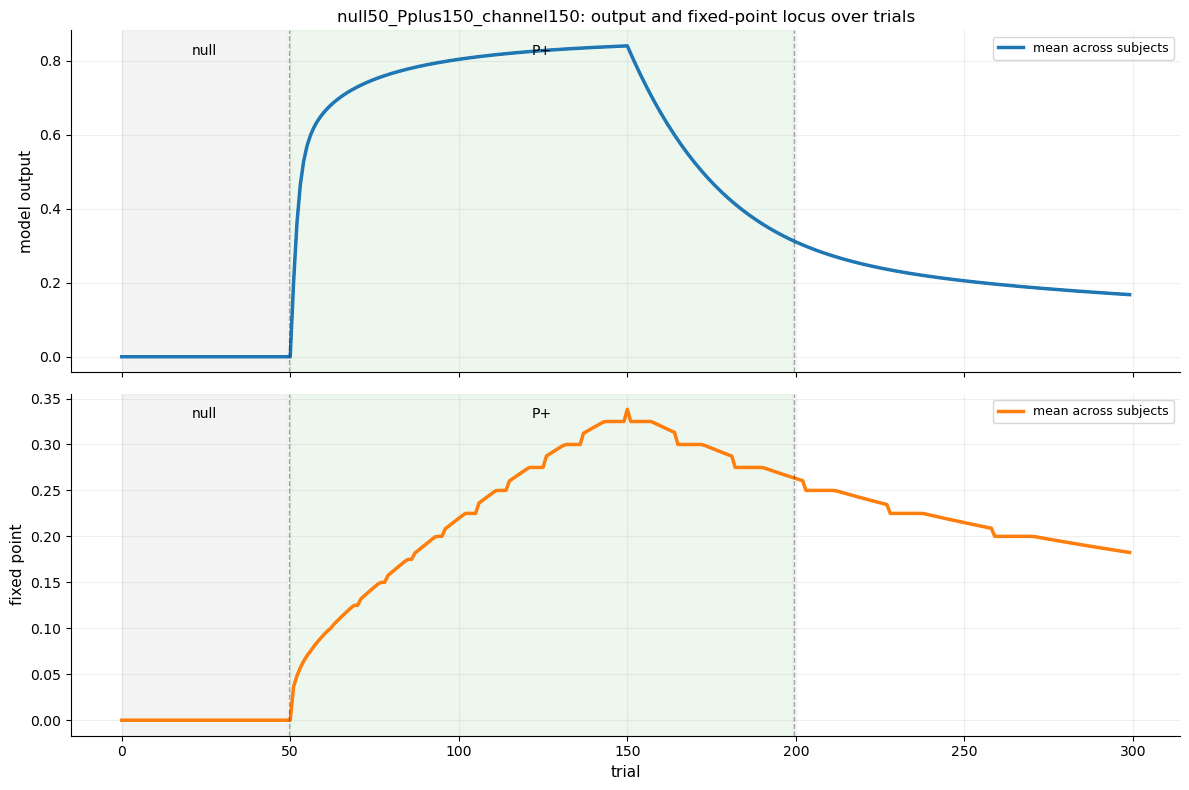

In [ ]:


def plot_outputs_and_fixed_points(eval_result, *, phase_edges=None, title=None):
    trial_idx = eval_result['trial_idx']
    outputs = eval_result['outputs']
    fixed_points = eval_result['fixed_points']
    output_mean = eval_result['output_mean']
    fixed_point_mean = eval_result['fixed_point_mean']

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    for subj_idx in range(outputs.shape[1]):
        axes[0].plot(trial_idx, outputs[:, subj_idx], color='tab:blue', alpha=0.18)
    axes[0].plot(trial_idx, output_mean, color='tab:blue', linewidth=2.5, label='mean across subjects')
    axes[0].set_ylabel('model output')
    axes[0].set_title(title or 'output and fixed-point locus over trials')
    axes[0].legend(loc='best')
    axes[0].grid(alpha=0.2)

    for subj_idx in range(fixed_points.shape[1]):
        axes[1].plot(trial_idx, fixed_points[:, subj_idx], color='tab:orange', alpha=0.18)
    axes[1].plot(trial_idx, fixed_point_mean, color='tab:orange', linewidth=2.5, label='mean across subjects')
    axes[1].set_xlabel('trial')
    axes[1].set_ylabel('fixed point')
    axes[1].legend(loc='best')
    axes[1].grid(alpha=0.2)

    if phase_edges is None:
        phase_edges = []
    for ax in axes:
        if len(trial_idx) >= 50:
            ax.axvspan(0, min(49, trial_idx[-1]), color='tab:gray', alpha=0.08)
        if len(trial_idx) >= 200:
            ax.axvspan(50, min(199, trial_idx[-1]), color='tab:green', alpha=0.08)
        if len(trial_idx) >= 350:
            ax.axvspan(200, min(349, trial_idx[-1]), color='tab:red', alpha=0.06)
        for edge in phase_edges:
            ax.axvline(edge - 0.5, color='k', linestyle='--', linewidth=1, alpha=0.35)
        if len(trial_idx) >= 50:
            ax.text(24.5, 0.96, 'null', transform=ax.get_xaxis_transform(), ha='center', va='top')
        if len(trial_idx) >= 200:
            ax.text(124.5, 0.96, 'P+', transform=ax.get_xaxis_transform(), ha='center', va='top')
        if len(trial_idx) >= 350:
            ax.text(274.5, 0.96, 'channel', transform=ax.get_xaxis_transform(), ha='center', va='top')

    fig.tight_layout()
    return fig, axes


name = 'null50_Pplus150_channel150'
paradigm = np.concatenate([
    np.zeros(50, dtype=np.float32),
    np.ones(100, dtype=np.float32),
    np.full(150, np.nan, dtype=np.float32),
])

eval_result = eval_paradigm_with_inoutmaps(
    model,
    args,
    paradigm,
    probe_values,
    name=name,
 )

phase_edges = [50, 200]
fig, axes = plot_outputs_and_fixed_points(
    eval_result,
    phase_edges=phase_edges,
    title=f"{name}: output and fixed-point locus over trials",
)

eval_result

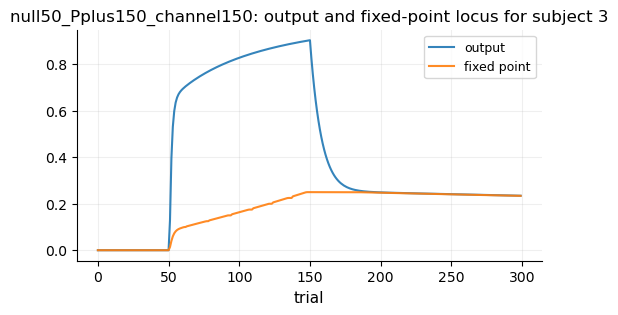

In [ ]:
# repeat plots for subject #3 only, plot over the same axis: fixed point locus and the output force

sbj = 3
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(eval_result['trial_idx'], eval_result['outputs'][:, sbj], color='tab:blue', alpha=0.9, label='output')
ax.plot(eval_result['trial_idx'], eval_result['fixed_points'][:, sbj], color='tab:orange', alpha=0.9, label='fixed point')
ax.set_xlabel('trial')
ax.set_title(f"{eval_result['name']}: output and fixed-point locus for subject {sbj}")
ax.legend(loc='best')
ax.grid(alpha=0.2)

In [ ]:
# Compare P+ duration 100 (solid) vs 150 (dashed) for a single subject.
subj_idx = 3  # change this to pick a different subject (0-based index)

paradigm_pplus50 = np.concatenate([
    np.zeros(50, dtype=np.float32),
    np.ones(50, dtype=np.float32),
    np.full(250, np.nan, dtype=np.float32),
])

paradigm_pplus150 = np.concatenate([
    np.zeros(50, dtype=np.float32),
    np.ones(150, dtype=np.float32),
    np.full(150, np.nan, dtype=np.float32),
])

paradigm_pplus150pplus50 = np.concatenate([
    np.zeros(50, dtype=np.float32),
    np.ones(150, dtype=np.float32),
    np.full(100, np.nan, dtype=np.float32),
    np.ones(50, dtype=np.float32),
])


eval_pplus50 = eval_paradigm_with_inoutmaps(
    model,
    args,
    paradigm_pplus50,
    probe_values,
    name='null50_Pplus100_channel150',
)
eval_pplus150 = eval_paradigm_with_inoutmaps(
    model,
    args,
    paradigm_pplus150,
    probe_values,
    name='null50_Pplus150_channel200',
)

eval_pplus150pplus50 = eval_paradigm_with_inoutmaps(
    model,
    args,
    paradigm_pplus150pplus50,
    probe_values,
    name='null50_Pplus150Pplus50',
)


evaluating null50_Pplus100_channel150 with 350 steps
evaluating null50_Pplus150_channel200 with 350 steps
evaluating null50_Pplus150Pplus50 with 350 steps


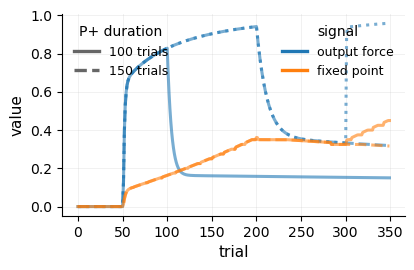

In [ ]:
plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
})

fig, ax = plt.subplots(figsize=(8.5/2, 4.2/1.5))
line_kw = dict(linewidth=2.2, alpha=0.6)

ax.plot(
    eval_pplus50['trial_idx'],
    eval_pplus50['outputs'][:, subj_idx],
    color='tab:blue',
    linestyle='-',
    **line_kw,
 )
ax.plot(
    eval_pplus150['trial_idx'],
    eval_pplus150['outputs'][:, subj_idx],
    color='tab:blue',
    linestyle='--',
    **line_kw,
 )
ax.plot(
    eval_pplus150pplus50['trial_idx'],
    eval_pplus150pplus50['outputs'][:, subj_idx],
    color='tab:blue',
    linestyle=':',
    **line_kw,
 )
ax.plot(
    eval_pplus150pplus50['trial_idx'],
    eval_pplus150pplus50['fixed_points'][:, subj_idx],
    color='tab:orange',
    linestyle='-',
    **line_kw,
 )
ax.plot(
    eval_pplus150['trial_idx'],
    eval_pplus150['fixed_points'][:, subj_idx],
    color='tab:orange',
    linestyle='--',
    **line_kw,
 )

ax.set_xlabel('trial')
ax.set_ylabel('value')
# ax.set_title(f"Subject {subj_idx}: adaptation and fixed point")
ax.grid(alpha=0.2, linestyle='-', linewidth=0.6)

# Legend 1: color coding
color_handles = [
    plt.Line2D([0], [0], color='tab:blue', linewidth=2.4, label='output force'),
    plt.Line2D([0], [0], color='tab:orange', linewidth=2.4, label='fixed point'),
]
color_legend = ax.legend(
    handles=color_handles,
    loc='upper right',
    frameon=False,
    title='signal',
 )
ax.add_artist(color_legend)

# Legend 2: line style coding (gray)
style_handles = [
    plt.Line2D([0], [0], color='0.4', linewidth=2.4, linestyle='-', label='100 trials'),
    plt.Line2D([0], [0], color='0.4', linewidth=2.4, linestyle='--', label='150 trials'),
]
ax.legend(
    handles=style_handles,
    loc='upper left',
    frameon=False,
    title='P+ duration',
 )

fig.tight_layout()

In [ ]:
# repeat fixed-point and adaptation analysis for eval_evoked
subj_idx = 3  # change as needed

trial_idx = eval_evoked['trial_idx']
outputs = eval_evoked['outputs'][:, subj_idx]
fixed_points = eval_evoked['fixed_points'][:, subj_idx]

# 1) adaptation trajectory and fixed-point locus
fig, ax = plt.subplots(figsize=(8.0, 3.0))
ax.plot(trial_idx, outputs, color='tab:blue', linewidth=2.0, alpha=0.85, label='output')
ax.plot(trial_idx, fixed_points, color='tab:orange', linewidth=2.0, alpha=0.85, label='fixed point')

# phase shading based on available length (evoked typically: null -> P+ -> channel)
if len(trial_idx) > 50:
    ax.axvspan(0, min(49, trial_idx[-1]), color='0.8', alpha=0.08, zorder=0)
if len(trial_idx) > 200:
    ax.axvspan(50, min(199, trial_idx[-1]), color='tab:green', alpha=0.08, zorder=0)
if len(trial_idx) > 340:
    ax.axvspan(200, min(339, trial_idx[-1]), color='tab:red', alpha=0.06, zorder=0)

ax.set_xlabel('trial')
ax.set_ylabel('adaptation')
ax.set_title(f"{eval_evoked['name']}: output and fixed-point locus (subject {subj_idx})")
ax.grid(alpha=0.2)
ax.legend(frameon=False, loc='best')
fig.tight_layout()

# 2) in-out maps at representative event groups
event_groups = {
    'P0 to P+': [50, 51, 52, 175],
    'P+ to P-': [175, 176, 177],
    'P- to P+': [190, 191, 192],
    'channel trials': [193, 194, 250, 339],
}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (event_group_name, tvec) in zip(axes.flat, event_groups.items()):
    for t in tvec:
        if 0 <= t < eval_evoked['inoutmaps'].shape[0]:
            ax.plot(probe_values, eval_evoked['inoutmaps'][t, subj_idx, :], linewidth=1.8, alpha=0.9)
    ax.plot(probe_values, probe_values, 'k:', linewidth=1.2, alpha=0.7)
    ax.set_xlim([-1.2, 1.2])
    ax.set_ylim([-1.2, 1.2])
    ax.grid(alpha=0.2)
    ax.set_title(event_group_name)

fig.suptitle(f"{eval_evoked['name']}: input-output maps (subject {subj_idx})")
fig.tight_layout()

NameError: name 'eval_evoked' is not defined

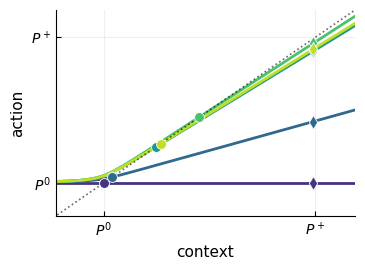

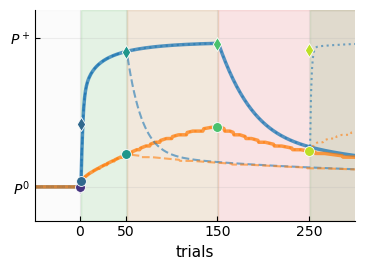

In [ ]:
# generate input-output map for the subject, with fixed-point markers
# Preps for FIG 1

plt.rcParams.update(rcConf)

enable_title_and_labels = False

subj_idx = 0  # change this for a different subject
pnt_size = 50
fig_scale = 3./4
time_steps = [50, 51, 100, 200, 300]
this_input_scale = model.softclamp(best_model_state_dict['output_scale'])[subj_idx].detach().cpu().numpy()
Pert = this_input_scale * 1
idx_pert = np.argmin(np.abs(probe_values-Pert))
x_pert = probe_values[idx_pert]
eval_ref = eval_pplus150  # use the P+ = 150 exposure condition

fixed_points = eval_ref['fixed_points'][:, subj_idx]
trial_idx = eval_ref['trial_idx'] - 50
outputs = eval_ref['outputs'][:, subj_idx]

fixed_points_pplus50 = eval_pplus50['fixed_points'][:, subj_idx]
trial_idx_pplus50 = eval_pplus50['trial_idx'] - 50
outputs_pplus50 = eval_pplus50['outputs'][:, subj_idx]

fixed_points_pplus150pplus50 = eval_pplus150pplus50['fixed_points'][:, subj_idx]
trial_idx_pplus150pplus50 = eval_pplus150pplus50['trial_idx'] - 50
outputs_pplus150pplus50 = eval_pplus150pplus50['outputs'][:, subj_idx]

colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(time_steps)))

# fig, (ax_map, ax_traj) = plt.subplots(1, 2, figsize=(11*fig_scale, 4.5*fig_scale))
fig1, ax_map = plt.subplots(figsize=(ufigx, ufigy))
fig2, ax_traj = plt.subplots(figsize=(ufigx, ufigy))
# Input-output maps with fixed-point dots
for color, t in zip(colors, time_steps):
    if t >= eval_ref['inoutmaps'].shape[0]:
        continue
    y_map = eval_ref['inoutmaps'][t, subj_idx, :]
    ax_map.plot(
        probe_values,
        y_map,
        color=color,
        linewidth=2.0,
        label=f't={t-50}',
    )
    ax_map.scatter(
        fixed_points[t],
        fixed_points[t],
        s=pnt_size,
        color=color,
        edgecolor='white',
        linewidth=0.6,
        zorder=5,
    )
    ax_traj.scatter(
        trial_idx[t],
        y_map[idx_pert],
        s=pnt_size,
        color=color,
        marker='d',
        edgecolor='white',
        linewidth=0.6,
        zorder=5,
    )

    ax_map.scatter(
        probe_values[idx_pert],
        y_map[idx_pert],
        s=pnt_size,
        color=color,
        marker='d',
        edgecolor='white',
        linewidth=0.6,
        zorder=5,
    )

adapt_lims = [-0.2, 1.05]
ax_map.plot(probe_values, probe_values, 'k:', linewidth=1.2, alpha=0.6, label='identity')
if enable_title_and_labels:
    ax_map.set_xlabel('input')
    ax_map.set_ylabel('output')
    ax_map.set_title('feed-forward \n in-out mapping')
ax_map.set_xlim(adapt_lims)
ax_map.set_ylim(adapt_lims)
ax_map.grid(alpha=0.2)
# ax_map.legend(frameon=False, title='trials from \nP+ onset', loc='upper left')

# Trajectories with fixed-point markers
x_traj = trial_idx + 1
x_traj_50 = trial_idx_pplus50 + 1

# Background shading for phases (P0, P+, Pc)
p0_start, p0_end = -49, 0
pplus50_start, pplus50_end = 1, 51
pplus150_start, pplus150_end = 1, 151
pc50_start, pc50_end = 51, 301
pc150_start, pc150_end = 151, 301
overlap_start, overlap_end = 51, 151
pplus50_recall_start, pplus50_recall_end = 251, 301

ax_traj.axvspan(p0_start-20, p0_end, color='0.8', alpha=0.08, zorder=0)
ax_traj.axvspan(pplus50_start, pplus50_end, color='tab:green', alpha=0.08, zorder=0)
ax_traj.axvspan(pplus150_start, pplus150_end, color='tab:green', alpha=0.05, zorder=0)
ax_traj.axvspan(pc50_start, pc50_end, color='tab:red', alpha=0.05, zorder=0)
ax_traj.axvspan(pc150_start, pc150_end, color='tab:red', alpha=0.08, zorder=0)
ax_traj.axvspan(overlap_start, overlap_end, color='tab:orange', alpha=0.06, zorder=0)
# Extra perturbation phase for dotted paradigm (last 50 trials)
ax_traj.axvspan(pplus50_recall_start, pplus50_recall_end, color='tab:green', alpha=0.12, zorder=0)

label_y = 0.02
# ax_traj.text((p0_start + p0_end) / 2, label_y, 'P0', transform=ax_traj.get_xaxis_transform(), ha='center', va='bottom', color='0.35')
# ax_traj.text((pplus50_start + pplus50_end) / 2, label_y, 'P+', transform=ax_traj.get_xaxis_transform(), ha='center', va='bottom', color='0.35')
# ax_traj.text((overlap_start + overlap_end) / 2, label_y, 'P+ \n(Pc)', transform=ax_traj.get_xaxis_transform(), ha='center', va='bottom', color='0.35')
# ax_traj.text((pc150_start + pc150_end) / 2, label_y, 'Pc', transform=ax_traj.get_xaxis_transform(), ha='center', va='bottom', color='0.35')
# ax_traj.text((pplus50_recall_start + pplus50_recall_end) / 2, label_y, 'Pc \n(P+)', transform=ax_traj.get_xaxis_transform(), ha='center', va='bottom', color='0.35')

ax_traj.plot(x_traj, outputs, color='tab:blue', linewidth=2.5, alpha=0.75, linestyle='-')
ax_traj.plot(x_traj, fixed_points*Pert, color='tab:orange', linewidth=2.5, alpha=0.75,linestyle='-')

# Add P+ = 50 trajectories (dashed)
thin_line_width = 1.5
ax_traj.plot(
    x_traj_50,
    outputs_pplus50,
    color='tab:blue',
    linewidth=thin_line_width,
    alpha=0.6,
    linestyle='--', label='output',
 )
ax_traj.plot(
    x_traj_50,
    fixed_points_pplus50*Pert,
    color='tab:orange',
    linewidth=thin_line_width,
    alpha=0.6,
    linestyle='--', label='fixed point',
 )

 # Add recall P+ trajectories (dotted)
ax_traj.plot(
    x_traj_50,
    outputs_pplus150pplus50,
    color='tab:blue',
    linewidth=thin_line_width,
    alpha=0.6,
    linestyle=':', label='output',
 )
ax_traj.plot(
    x_traj_50,
    fixed_points_pplus150pplus50*Pert,
    color='tab:orange',
    linewidth=thin_line_width,
    alpha=0.6,
    linestyle=':', label='fixed point',
 )
#
for color, t in zip(colors, time_steps):
    if t >= trial_idx.shape[0]:
        continue
    ax_traj.scatter(
        trial_idx[t],
        fixed_points[t]*Pert,
        s=pnt_size,
        color=color,
        edgecolor='white',
        linewidth=0.6,
        zorder=5,
    )

if enable_title_and_labels:
    ax_traj.set_xlabel('trials')
    ax_traj.set_ylabel('adaptation')
    ax_traj.set_title('adaptation trajectories')
ax_traj.grid(alpha=0.2)
ax_traj.set_ylim(adapt_lims)

# Legend for signal colors
# signal_legend = ax_traj.legend(frameon=False, loc='upper right', title='signal')
# ax_traj.add_artist(signal_legend)

# Legend for line styles
# style_handles = [
#     plt.Line2D([0], [0], color='0.4', linewidth=2.4, linestyle='-', label='50'),
#     plt.Line2D([0], [0], color='0.4', linewidth=2.4, linestyle='--', label='150'),
# ]
# ax_traj.legend(handles=style_handles, frameon=False, loc='upper left', title='P+ duration')

ax_traj.set_xticks([0,50,150,250])
ax_traj.set_xlabel('trials')
ax_traj.set_yticks([0, Pert])
ax_traj.set_yticklabels(['$P^0$', '$P^+$'])

ax_map.set_yticks([0, Pert])
ax_map.set_yticklabels(['$P^0$', '$P^+$'])
ax_map.set_xlabel('context')
ax_map.set_ylabel('action')

ax_map.set_xticks([0, Pert])
ax_map.set_xticklabels(['$P^0$', '$P^+$'])
response_x_min, response_x_max = x_traj_50[0], x_traj_50[-1]
ax_traj.set_xlim(response_x_min, response_x_max)

for this_ax in [ax_map, ax_traj]:
    this_ax.tick_params(axis='y',which='both',direction='in',right=False)
    this_ax.tick_params(axis='x',which='both',direction='in',right=False)

fig1.tight_layout()
fig1.savefig('fig1CvJn3.svg',format='svg')
fig2.tight_layout()
fig2.savefig('fig1DvJn3.svg',format='svg')    

In [ ]:
Pert

0.8832532167434692

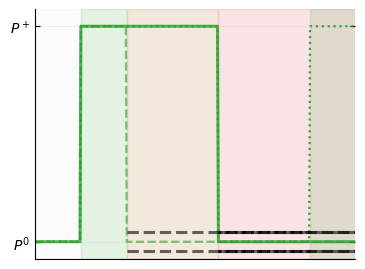

In [ ]:
def nan2zero(arr):
    arr = np.asarray(arr, dtype=np.float32)
    arr[np.isnan(arr)] = 0.0
    return arr

# A cartoon of the perturbation profile for all P+ duration paradigms,
# aligned to P+ onset and shaded with the same phase colors as above.
plt.rcParams.update(rcConf)

paradigm_50 = nan2zero(eval_pplus50['paradigm'])
paradigm_150 = nan2zero(eval_pplus150['paradigm'])
paradigm_150p50 = nan2zero(eval_pplus150pplus50['paradigm'])

trial_rel_50 = np.asarray(eval_pplus50['trial_idx']) - 50
trial_rel_150 = np.asarray(eval_pplus150['trial_idx']) - 50
trial_rel_150p50 = np.asarray(eval_pplus150pplus50['trial_idx']) - 50

fig, ax = plt.subplots(figsize=(ufigx,ufigy))

response_x_min, response_x_max = -49, 300
p0_start, p0_end = -49, 0
pplus50_start, pplus50_end = 1, 51
pplus150_start, pplus150_end = 1, 151
pc50_start, pc50_end = 51, 301
pc150_start, pc150_end = 151, 301
overlap_start, overlap_end = 51, 151
pplus50_recall_start, pplus50_recall_end = 251, 301
channel_offset = 0.045

ax.axvspan(p0_start - 1, p0_end, color='0.8', alpha=0.08, zorder=0)
ax.axvspan(pplus50_start, pplus50_end, color='tab:green', alpha=0.08, zorder=0)
ax.axvspan(pplus150_start, pplus150_end, color='tab:green', alpha=0.05, zorder=0)
ax.axvspan(pc50_start, pc50_end, color='tab:red', alpha=0.05, zorder=0)
ax.axvspan(pc150_start, pc150_end, color='tab:red', alpha=0.08, zorder=0)
ax.axvspan(overlap_start, overlap_end, color='tab:orange', alpha=0.06, zorder=0)
# Extra perturbation phase for dotted paradigm (last 50 trials)
ax.axvspan(pplus50_recall_start, pplus50_recall_end, color='tab:green', alpha=0.12, zorder=0)

line_kw = dict(color='tab:green', linewidth=1.6)
main_line_kw = dict(color='tab:green', linewidth=2.2)
ax.plot(trial_rel_50 + 1, paradigm_50, linestyle='--', alpha=0.6, **line_kw)
ax.plot(trial_rel_150 + 1, paradigm_150, linestyle='-', alpha=0.8, **main_line_kw)
ax.plot(trial_rel_150p50 + 1, paradigm_150p50, linestyle=':', alpha=0.95, **line_kw)

# Channel phase markers (around zero)
ax.hlines(
    [channel_offset, -channel_offset],
    pc50_start,
    response_x_max,
    colors='k',
    linewidth=2.2,
    linestyles='--',
    alpha=0.6,
)
ax.hlines(
    [channel_offset, -channel_offset],
    pc150_start,
    response_x_max,
    colors='k',
    linewidth=2.2,
    linestyles='-',
    alpha=0.6,
)
ax.hlines(
    [channel_offset, -channel_offset],
    pc150_start,
    pplus50_recall_start,
    colors='k',
    linewidth=2.2,
    linestyles=':',
    alpha=0.8,
)

# style_handles = [
#     plt.Line2D([0], [0], color='tab:green', linewidth=2.2, linestyle='--', label='P+50'),
#     plt.Line2D([0], [0], color='tab:green', linewidth=2.2, linestyle='-', label='P+150'),
#     plt.Line2D([0], [0], color='tab:green', linewidth=2.2, linestyle=':', label='P+150+50'),
#     plt.Line2D([0], [0], color='k', linewidth=2.2, linestyle='-', label='channel'),
# ]
# ax.legend(handles=style_handles, frameon=False, loc='upper right', title='profile')

if enable_title_and_labels:
    ax.set_xlabel('trials')
# # ax.set_ylabel('perturbation')
# ax.set_title('perturbation')
ax.set_xticks([])
ax.set_yticks([0, 1])
ax.set_yticklabels(['$P^0$', '$P^+$'])
ax.set_xlim(response_x_min, response_x_max)
ax.set_ylim(-0.08, 1.08)
ax.set_yticks([0, 1])
ax.grid(alpha=0.2, linestyle='-', linewidth=0.6)
ax.tick_params(axis='y',which='both',direction='in',right=True)

fig.tight_layout()
# plt.savefig('fig1Bv2.svg',format='svg')

In [ ]:
evoked_ys

array([[ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0., nan,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       ...,
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan],
       [ 0.,  0.,  0., ..., nan, nan, nan]], dtype=float32)

In [ ]:
eval_evoked = eval_paradigm_with_inoutmaps(
    model,
    args,
    evoked_ys[0],
    probe_values,
    name='evoked',
)



evaluating evoked with 340 steps


In [ ]:
eval_spontaneous = eval_paradigm_with_inoutmaps(
    model,
    args,
    -spontaneous_ys[0],
    probe_values,
    name='spontaneous',
)

evaluating spontaneous with 340 steps


In [ ]:
spontaneous_ys[0]

array([ 0., nan,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., nan,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., nan,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., nan,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., nan, -1., nan,
       -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
       -1., -1., -1., -1., nan, -1., nan, -1., -1., -1., -1., -1., -1.,
       -1., -1., -1., -1., nan, -1., -1., -1., -1., -1., -1., -1., -1.,
       -1., -1., -1., -1., -1., nan, -1., -1., -1., -1., -1., -1., -1.,
       nan, -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
       -1., nan, -1., -1., -1., -1., -1., -1., -1., -1., -1., nan, -1.,
       -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,
       nan, -1., -1., -1., -1., -1., -1., -1., nan, -1., -1., -1., -1.,
       -1., nan, -1., -1., -1., -1., -1., -1., -1., -1., nan, -1., -1.,
       -1., -1., -1., -1., -1., -1.,  1.,  1.,  1.,  1.,  1.,  1

In [ ]:

# FIG 2 compute:
# Recompute this cell only when the model, paradigms, or probe range changes.

fig2_time_points = [174, 176, 190]#, 194]
fig2_subj_idxs = {
    'evoked': 0,
    'spontaneous': 8,
}
fig2_swapped_paradigms = {
    'evoked': 'spontaneous',
    'spontaneous': 'evoked',
}

# Wider probing range so the maps cover the full dynamic range.
these_probe_values = np.arange(-1.2, 1.2 + 0.025 / 2, 0.025, dtype=np.float32)
fig2_eval_evoked = eval_paradigm_with_inoutmaps(
    model,
    args,
    # evoked_ys[0],
    np.array(playlist['evoked'], dtype=np.float32),
    these_probe_values,
    name='evoked_fig2',
)
fig2_eval_spontaneous = eval_paradigm_with_inoutmaps(
    model,
    args,
    # spontaneous_ys[0],
    np.array(playlist['spontaneous'], dtype=np.float32),
    these_probe_values,
    name='spontaneous_fig2',
)

fig2_cache = {
    'time_points': fig2_time_points,
    'subj_idxs': fig2_subj_idxs,
    'swapped_paradigms': fig2_swapped_paradigms,
    'probe_values': these_probe_values,
    'all_evals': {
        'evoked': fig2_eval_evoked,
        'spontaneous': fig2_eval_spontaneous,
    },
}

print('fig2_cache ready:', list(fig2_cache['all_evals'].keys()))


evaluating evoked_fig2 with 340 steps
evaluating spontaneous_fig2 with 340 steps
fig2_cache ready: ['evoked', 'spontaneous']


In [ ]:
fig2_cache['time_points']=[52, 174, 190]

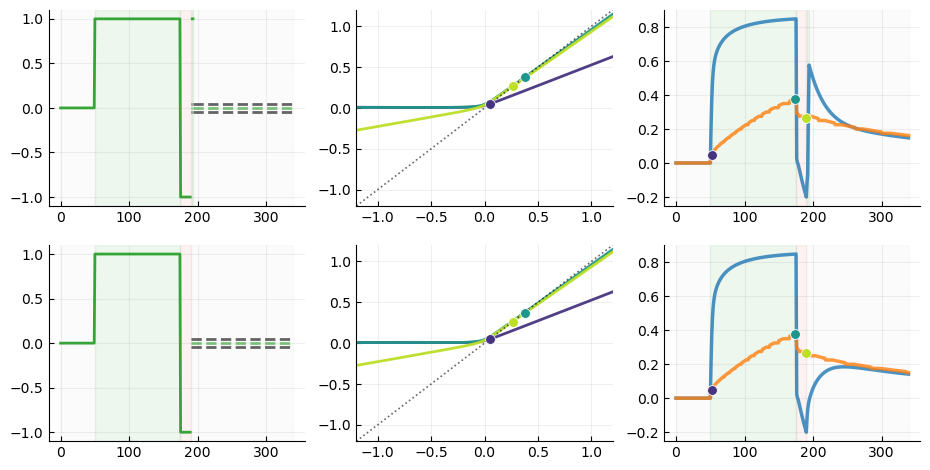

In [ ]:

# FIG 2 draw:
# Safe to rerun and tweak without recomputing the paradigm simulations above.

if 'fig2_cache' not in globals():
    raise RuntimeError('Run the FIG 2 compute cell first to populate fig2_cache.')

plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
})

def phase_segments_from_paradigm(paradigm, zero_tol=1e-8):
    sign_code = np.zeros(len(paradigm), dtype=int)
    sign_code[np.asarray(paradigm) > zero_tol] = 1
    sign_code[np.asarray(paradigm) < -zero_tol] = -1

    segments = []
    start = 0
    current_sign = sign_code[0]
    for idx in range(1, len(sign_code) + 1):
        if idx == len(sign_code) or sign_code[idx] != current_sign:
            segments.append((start, idx - 1, current_sign))
            if idx < len(sign_code):
                start = idx
                current_sign = sign_code[idx]
    return segments

def add_phase_shading(ax, paradigm):
    for start, end, sign_code in phase_segments_from_paradigm(paradigm):
        left = start - 0.5
        right = end + 0.5
        if sign_code == 0:
            ax.axvspan(left, right, color='0.8', alpha=0.08, zorder=0)
        elif sign_code > 0:
            ax.axvspan(left, right, color='tab:green', alpha=0.08, zorder=0)
        else:
            ax.axvspan(left, right, color='tab:red', alpha=0.06, zorder=0)

def add_channel_markers(ax, paradigm, channel_offset=0.045):
    seen_nonzero = False
    for start, end, sign_code in phase_segments_from_paradigm(paradigm):
        if sign_code != 0:
            seen_nonzero = True
            continue
        if not seen_nonzero:
            continue
        ax.hlines(
            [channel_offset, -channel_offset],
            start - 0.5,
            end + 0.5,
            colors='k',
            linewidth=2.0,
            linestyles='--',
            alpha=0.6,
            zorder=2,
        )
        ax.hlines(
            [0],
            start - 0.5,
            end + 0.5,
            colors='tab:green',
            linewidth=2.0,
            linestyles='--',
            alpha=0.6,
            zorder=2,
        )

time_points = fig2_cache['time_points']
subj_idxs = fig2_cache['subj_idxs']
swapped_paradigms = fig2_cache['swapped_paradigms']
all_evals = fig2_cache['all_evals']

pnt_size = 50
map_lims = [-1.2, 1.2]
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(time_points)))

fig, axes = plt.subplots(2, 3, figsize=(ufigx*3,ufigy*2))

for row_idx, (name, eval_result) in enumerate(all_evals.items()):
    subj_idx = subj_idxs[name]
    trial_idx = np.asarray(eval_result['trial_idx'])
    outputs = eval_result['outputs'][:, subj_idx]
    flipper = np.sign(np.nanmean(outputs[:150]))
    fixed_points = eval_result['fixed_points'][:, subj_idx]
    paradigm = np.asarray(eval_result['paradigm'])
    experiment = np.asarray(evoked_a_exp[subj_idx]) if name.startswith('evoked') else np.asarray(spontaneous_a_exp[subj_idx-8])

    outputs = outputs * flipper  # ensure same sign convention as model
    experiment = experiment * flipper  # ensure same sign convention as model
    fixed_points = fixed_points * flipper  # ensure same sign convention as model
    these_probe_values = fig2_cache['probe_values'] * flipper  # ensure same sign convention as model
    paradigm = paradigm * flipper  # ensure same sign convention as model

    swapped_name = swapped_paradigms[name]
    swapped_eval = all_evals[swapped_name]
    swapped_outputs = swapped_eval['outputs'][:, subj_idx]
    swapped_flipper = np.sign(np.nanmean(swapped_outputs[:150]))
    swapped_outputs = swapped_outputs * swapped_flipper  # ensure same sign convention as model
    swapped_trial_idx = np.asarray(swapped_eval['trial_idx'])

    # 1) In-out map at required time points, with FIG 1 markers.
    ax_map = axes[row_idx, 1]
    for color, t in zip(colors, time_points):
        if not (0 <= t < eval_result['inoutmaps'].shape[0]):
            continue

        y_map = eval_result['inoutmaps'][t, subj_idx, :] * flipper  # ensure same sign convention as model
        ax_map.plot(
            these_probe_values,
            y_map,
            color=color,
            linewidth=2.0,
            alpha=0.95,
            label=f't={t}',
        )

        ax_map.scatter(
            fixed_points[t],
            fixed_points[t],
            s=pnt_size,
            color=color,
            edgecolor='white',
            linewidth=0.6,
            zorder=6,
        )

        if np.isfinite(paradigm[t]):
            idx_input = np.argmin(np.abs(these_probe_values - paradigm[t]))
            # ax_map.scatter(
            #     these_probe_values[idx_input],
            #     y_map[idx_input],
            #     s=pnt_size,
            #     color=color,
            #     marker='d',
            #     edgecolor='white',
            #     linewidth=0.6,
            #     zorder=6,
            # )

    ax_map.plot(these_probe_values, these_probe_values, 'k:', linewidth=1.2, alpha=0.6)
    ax_map.set_xlim(map_lims)
    ax_map.set_ylim(map_lims)
    ax_map.grid(alpha=0.2)
    # ax_map.set_title(f'{name}: in-out map')
    # ax_map.set_xlabel('input')
    # ax_map.set_ylabel('output')
    # ax_map.legend(frameon=False, loc='best')

    # 2) Adaptation plot (actual output, swapped output, and fixed point).
    ax_adapt = axes[row_idx, 2]
    add_phase_shading(ax_adapt, paradigm)
    ax_adapt.plot(
        trial_idx,
        outputs,
        color='tab:blue',
        linewidth=2.5,
        alpha=0.8,
        label='output',
    )
    # ax_adapt.plot(
    #     swapped_trial_idx,
    #     swapped_outputs,
    #     color='tab:blue',
    #     linewidth=1.5,
    #     alpha=0.65,
    #     linestyle='--',
    #     label=f'{swapped_name} output',
    # )
    ax_adapt.plot(
        trial_idx,
        fixed_points,
        color='tab:orange',
        linewidth=2.5,
        alpha=0.8,
        label='fixed point',
    )

    for color, t in zip(colors, time_points):
        if 0 <= t < len(trial_idx):
            # ax_adapt.scatter(
            #     trial_idx[t],
            #     outputs[t],
            #     s=pnt_size,
            #     color=color,
            #     marker='d',
            #     edgecolor='white',
            #     linewidth=0.6,
            #     zorder=6,
            # )
            ax_adapt.scatter(
                trial_idx[t],
                fixed_points[t],
                s=pnt_size,
                color=color,
                edgecolor='white',
                linewidth=0.6,
                zorder=6,
            )

    #plot experimental data with black dots
    # ax_adapt.plot(experiment,'.',  color='k', linewidth=1.0, alpha=0.3, label='experiment')

    ax_adapt.grid(alpha=0.2)
    # ax_adapt.set_title(f'{name}: adaptation')
    # ax_adapt.set_xlabel('trial')
    # ax_adapt.set_ylabel('adaptation')
    # ax_adapt.legend(frameon=False, loc='best')

    # 3) Paradigm plot
    ax_par = axes[row_idx, 0]
    add_phase_shading(ax_par, paradigm)
    ax_par.plot(trial_idx, paradigm, color='tab:green', linewidth=2.0, alpha=0.95)
    add_channel_markers(ax_par, paradigm)

    for color, t in zip(colors, time_points):
        if 0 <= t < len(trial_idx):
            # ax_par.scatter(
            #     trial_idx[t],
            #     paradigm[t],
            #     s=pnt_size * 0.8,
            #     color=color,
            #     marker='d',
            #     edgecolor='white',
            #     linewidth=0.6,
            #     zorder=6,
            # )
            pass

    ax_par.grid(alpha=0.2)
    # ax_par.set_title(f'{name}: paradigm')
    # ax_par.set_xlabel('trial')
    # ax_par.set_ylabel('perturbation')

for ax_row in axes:
    for ax in ax_row:
        ax.tick_params(axis='y', which='both', direction='in', right=False)
        ax.tick_params(axis='x', which='both', direction='in', top=False)

# fig.suptitle('FIG 2: evoked and spontaneous analyses at t = 174, 176, 190, 194', y=1.02)

fig.savefig('fig2vJn3.svg', format='svg', bbox_inches='tight')


In [ ]:
long_long_ada = np.concatenate([
    np.zeros(50, dtype=np.float32),
    np.ones(400, dtype=np.float32),
    -np.ones(20, dtype=np.float32),
    np.full(150, np.nan, dtype=np.float32),
])

eval_long_long_ada = eval_paradigm_with_inoutmaps(
    model,
    args,
    long_long_ada,
    probe_values,
    name='long_long_ada',
)

evaluating long_long_ada with 620 steps


In [ ]:
eval_long_long_ada['outputs'].shape

(620, 16)

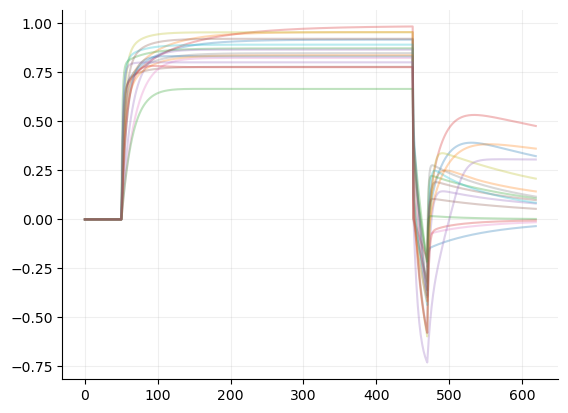

In [ ]:
for subj_idx in range(eval_long_long_ada['outputs'].shape[1]):
    plt.plot(eval_long_long_ada['trial_idx'], eval_long_long_ada['outputs'][:, subj_idx], alpha=0.3)
plt.grid(alpha=0.2)

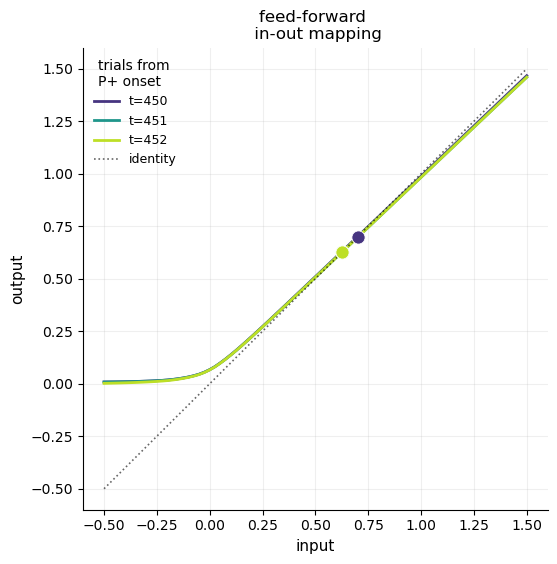

In [ ]:
#plot every 50 trials the in-out map with fixed point markers
subj_idx = 3

time_steps = [450, 451, 452]
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(time_steps)))
fig, ax = plt.subplots(figsize=(6, 6))
for color, t in zip(colors, time_steps):    
    if t >= eval_long_long_ada['inoutmaps'].shape[0]:
        continue
    y_map = eval_long_long_ada['inoutmaps'][t, subj_idx, :]
    ax.plot(
        probe_values,
        y_map,
        color=color,
        linewidth=2.0,
        label=f't={t}',
    )
    ax.scatter(
        eval_long_long_ada['fixed_points'][t, subj_idx],
        eval_long_long_ada['fixed_points'][t, subj_idx],
        s=90,
        color=color,
        edgecolor='white',
        linewidth=0.6,
        zorder=5,
    )
ax.plot(probe_values, probe_values, 'k:', linewidth=1.2, alpha=0.6, label='identity')
ax.set_xlabel('input')
ax.set_ylabel('output')
ax.set_title('feed-forward \n in-out mapping')
# ax.set_xlim(adapt_lims)
# ax.set_ylim(adapt_lims)
ax.grid(alpha=0.2)
ax.legend(frameon=False, title='trials from \nP+ onset', loc='upper left')

evaluating paradigm wm_sr_baseline_usual with 788 steps
evaluating paradigm wm_sr_baseline_rep_0 with 788 steps
evaluating paradigm wm_sr_baseline_rep_1 with 788 steps
evaluating paradigm wm_sr_baseline_rep_2 with 788 steps
evaluating paradigm wm_sr_baseline_rep_3 with 788 steps
evaluating paradigm wm_sr_baseline_rep_4 with 788 steps
evaluating paradigm wm_sr_baseline_usual with 362 steps
evaluating paradigm wmE2_sr_baseline_rep_0 with 362 steps
evaluating paradigm wmE2_sr_baseline_rep_1 with 362 steps
evaluating paradigm wmE2_sr_baseline_rep_2 with 362 steps
evaluating paradigm wmE2_sr_baseline_rep_3 with 362 steps
evaluating paradigm wmE2_sr_baseline_rep_4 with 362 steps
evaluating paradigm wm_sr_baseline_usual with 768 steps
evaluating paradigm wmE3_sr_baseline_rep_0 with 768 steps
evaluating paradigm wmE3_sr_baseline_rep_1 with 768 steps
evaluating paradigm wmE3_sr_baseline_rep_2 with 768 steps
evaluating paradigm wmE3_sr_baseline_rep_3 with 768 steps
evaluating paradigm wmE3_sr_ba

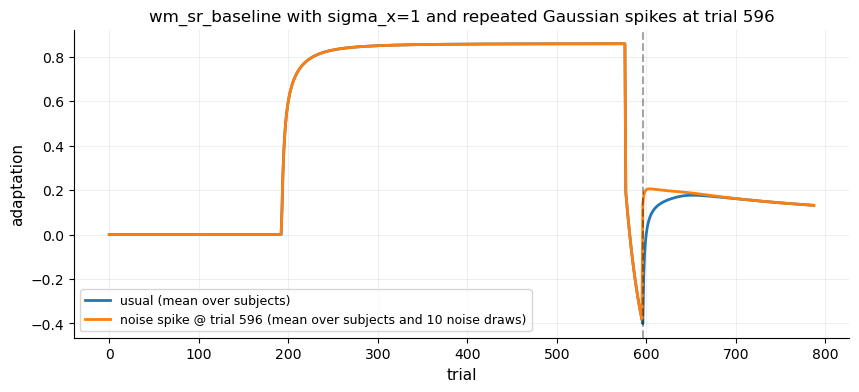

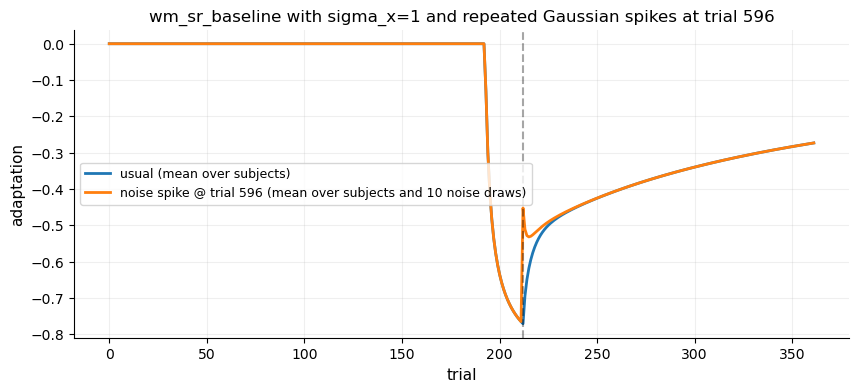

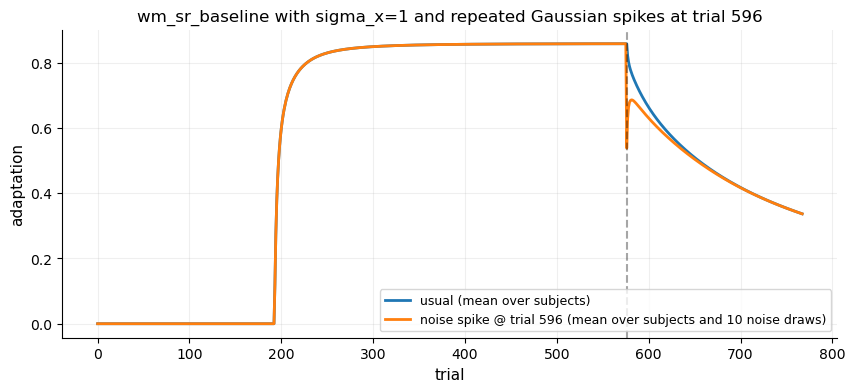

In [ ]:
# evaluate the paradigm wm_sr_baseline, first as usual and then with repeated Gaussian noise spikes at trial 596

wm_manipu_program = {'exp1': {'ref_paradigm':'wm_sr_baseline', 'noise_mu_sigma': (1, 1.0), 'noise_trial':596},
                     'exp2': {'ref_paradigm':'wmE2_sr_baseline', 'noise_mu_sigma': (1, 1.0), 'noise_trial':212},
                     'exp3': {'ref_paradigm':'wmE3_sr_baseline', 'noise_mu_sigma': (-1, 1.0), 'noise_trial':576}}

wm_manipu_results = {}

with open(paradigm_file, 'rb') as f:
    playlist = pickle.load(f)

for exp_name, wm_manipu in wm_manipu_program.items():
    wm_sr_baseline = playlist[wm_manipu['ref_paradigm']]
    noise_trial = wm_manipu['noise_trial']
    n_noise_repeats = 5
                                   
    noise_mu, noise_sigma = wm_manipu['noise_mu_sigma']

    with torch.no_grad():
        model.sigma_x.fill_(1.0)

    def _to_numpy_time_by_subject(outputs):
        rows = []
        for z in outputs:
            if torch.is_tensor(z):
                rows.append(z.detach().cpu().numpy().reshape(-1))
            else:
                rows.append(np.asarray(z).reshape(-1))
        return np.stack(rows, axis=0)

    def run_wm_sr_baseline_with_manual_noise(model, paradigm, args, noise_at_trial=None, paradigm_name=None):
        if paradigm_name is not None:
            print(f"evaluating paradigm {paradigm_name} with {len(paradigm)} steps")

        device = next(model.parameters()).device
        ys = torch.as_tensor(paradigm, device=device, dtype=torch.float32)
        ys = ys.unsqueeze(0).repeat(args.bs, 1)
        noises = torch.zeros((args.bs, ys.shape[1]), device=device, dtype=torch.float32)

        if noise_at_trial is not None:
            noise_at_trial = torch.as_tensor(noise_at_trial, device=device, dtype=torch.float32)
            if noise_at_trial.ndim == 0:
                noises[:, noise_trial] = noise_at_trial
            else:
                noises[:, noise_trial] = noise_at_trial.reshape(-1)

        noise_list = [noises[:, t_idx] for t_idx in range(noises.shape[1])]
        y_list = [ys[:, t_idx] for t_idx in range(ys.shape[1])]

        model.eval()
        with torch.no_grad():
            outputs_ = model.f(
                args.n,
                noise_list,
                y_list,
                args.model,
                qs=None,
            )

        return _to_numpy_time_by_subject(outputs_)

    wm_sr_baseline_usual = run_wm_sr_baseline_with_manual_noise(
        model,
        wm_sr_baseline,
        args,
        noise_at_trial=None,
        paradigm_name='wm_sr_baseline_usual',
    )

    wm_sr_baseline_noise596_runs = []
    wm_sr_baseline_noise596_values = []
    device = next(model.parameters()).device
    for repeat_idx in range(n_noise_repeats):
        sampled_noise = torch.randn(args.bs, device=device) * noise_sigma + noise_mu
        wm_sr_baseline_noise596_values.append(sampled_noise.detach().cpu().numpy())
        wm_sr_baseline_noise596_runs.append(
            run_wm_sr_baseline_with_manual_noise(
                model,
                wm_sr_baseline,
                args,
                noise_at_trial=sampled_noise,
                paradigm_name=f'{wm_manipu["ref_paradigm"]}_rep_{repeat_idx}',
            )
        )

    wm_sr_baseline_noise596_runs = np.stack(wm_sr_baseline_noise596_runs, axis=0)
    wm_sr_baseline_noise596_values = np.stack(wm_sr_baseline_noise596_values, axis=0)
    wm_manipu_results[exp_name] = {'base': wm_sr_baseline_usual, 'noisy': wm_sr_baseline_noise596_runs}
    
    wm_sr_baseline_usual_mean = wm_sr_baseline_usual.mean(axis=1)
    wm_sr_baseline_noise596_mean = wm_sr_baseline_noise596_runs.mean(axis=(0, 2))

    plt.figure(figsize=(10, 4))
    plt.plot(wm_sr_baseline_usual_mean, label='usual (mean over subjects)', linewidth=2)
    plt.plot(
        wm_sr_baseline_noise596_mean,
        label='noise spike @ trial 596 (mean over subjects and 10 noise draws)',
        linewidth=2,
    )
    plt.axvline(noise_trial, color='k', linestyle='--', alpha=0.35)
    plt.grid(alpha=0.2)
    plt.xlabel('trial')
    plt.ylabel('adaptation')
    plt.title('wm_sr_baseline with sigma_x=1 and repeated Gaussian spikes at trial 596')
    plt.legend()

    wm_sr_baseline_eval = {
        'sigma_x': model.sigma_x.detach().cpu().numpy().copy(),
        'usual': wm_sr_baseline_usual,
        'usual_mean_over_subjects': wm_sr_baseline_usual_mean,
        'noise596_runs': wm_sr_baseline_noise596_runs,
        'noise596_mean_over_subjects_and_runs': wm_sr_baseline_noise596_mean,
        'noise596_values': wm_sr_baseline_noise596_values,
    }


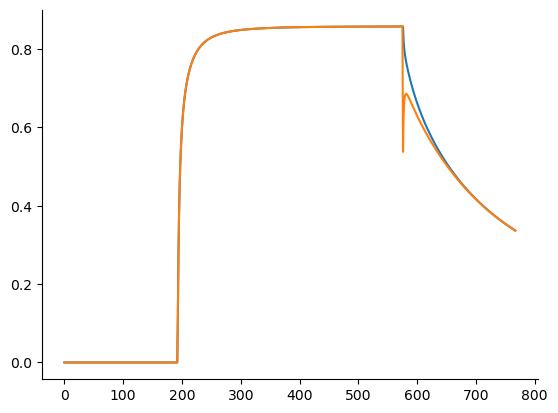

In [ ]:
plt.plot(np.mean(wm_sr_baseline_usual, axis=1))
plt.plot(np.mean(wm_sr_baseline_noise596_runs, axis=0).mean(axis=-1))

In [ ]:
np.shape(wm_sr_baseline_noise596_runs)

(5, 768, 16)

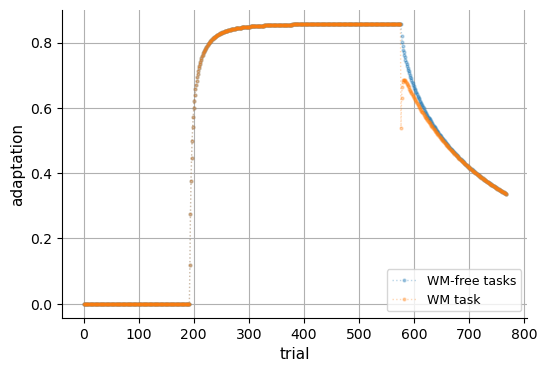

In [ ]:
plt.figure(figsize=(6, 4))

plt.plot(wm_sr_baseline_usual_mean, 'o:', label='WM-free tasks', linewidth=1, markersize=2, alpha=0.3)
plt.plot(
    wm_sr_baseline_noise596_mean, 'o:',
    label='WM task',
    linewidth=1,
    markersize=2,
    alpha=0.3,
)
plt.grid()
plt.xlabel('trial')
plt.ylabel('adaptation')
plt.legend()
# plt.xlim(580, 620)

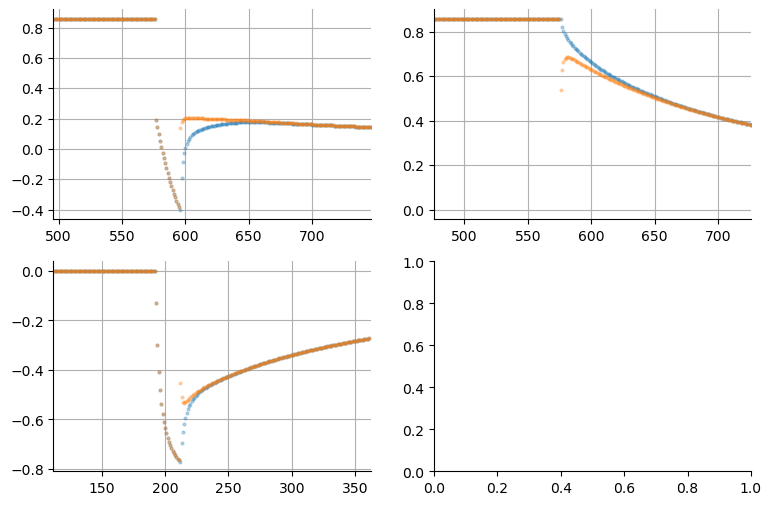

In [ ]:
fig, axs = plt.subplots(2,2,figsize=(9, 6))

for ii, (exp,result) in enumerate(wm_manipu_results.items()): 
    ax = axs[ii%2,ii//2]

    ax.plot(np.mean(result['base'], axis=1), '.',linewidth=1, markersize=4, alpha=0.3)
    ax.plot(np.mean(result['noisy'], axis=0).mean(axis=-1),'.' ,linewidth=1, markersize=4, alpha=0.3)
    # ax.plot(wm_sr_baseline_usual_mean, 'o:', label='WM-free tasks', linewidth=1, markersize=2, alpha=0.3)
    # ax.plot(
    #     wm_sr_baseline_noise596_mean, 'o:',
    #     label='WM task',
    #     linewidth=1,
    #     markersize=2,
    #     alpha=0.3,
    # )
    ax.grid()
    # plt.xlabel('trial')
    # plt.ylabel('adaptation')
    x0 = wm_manipu_program[exp]['noise_trial']
    ax.set_xlim(x0-100,x0+150)
    # plt.legend()
# plt.xlim(580, 620)

In [ ]:
wm_manipu_program[exp]['noise_trial']

576

In [ ]:
best_model_state_dict

OrderedDict([('log_learning_rate',
              tensor([[ -7.6139],
                      [ -7.8198],
                      [ -8.3296],
                      [ -7.3946],
                      [ -8.3731],
                      [ -7.2130],
                      [ -8.9496],
                      [ -7.7506],
                      [ -8.0251],
                      [ -7.8465],
                      [ -9.6313],
                      [ -7.1060],
                      [-10.5573],
                      [ -8.7070],
                      [ -7.0279],
                      [ -9.4148]])),
             ('log_learning_rate_decay',
              tensor([[ 2.8207],
                      [ 1.0260],
                      [ 2.2335],
                      [ 2.9026],
                      [-1.8546],
                      [ 1.7730],
                      [-1.3736],
                      [ 3.2317],
                      [ 1.7776],
                      [ 2.9313],
                      [ 2.1357],
              

In [ ]:
best_model_state_dict['u_feedback_scale'].mean()
best_model_state_dict['u_feedback_scale'].median()

tensor(1.0506)

In [ ]:
np.median([1.3076, 0.7217, 2.7786, 1.1200, 0.5776, 0.2920, 0.5650, 2.7543, 1.0040,
                      1.6135, 2.7785, 0.9009, 4.8955, 0.7458, 0.8289, 1.8321])

1.062

In [ ]:
#histogram of best seed output scales
best_output_scales = model_state_dict['output_scale'].cpu().numpy().reshape([subjs, seeds])[np.arange(subjs), best_seed_idx]   

In [ ]:
torch.nn.Sigmoid()(best_model_state_dict['direct_injection_scale']).numpy()

KeyError: 'direct_injection_scale'

In [ ]:
best_params = {}
for key in model_state_dict.keys():
    if not key.startswith('_'):  # skip batchnorm running stats
        best_params[key] = model_state_dict[key].cpu().numpy().reshape([subjs, seeds])[np.arange(subjs), best_seed_idx]

In [ ]:
best_params

{'log_learning_rate': array([ -7.300348 ,  -7.8582354,  -8.2358265,  -7.222224 ,  -8.892964 ,
         -7.4771338,  -9.196027 ,  -7.728507 ,  -7.777331 ,  -7.71817  ,
        -10.004287 ,  -7.36869  , -10.548333 ,  -8.710448 ,  -7.2314134,
         -9.094078 ], dtype=float32),
 'log_learning_rate_decay': array([ 2.412065  ,  2.0261178 ,  1.8543552 ,  2.927082  , -0.70237297,
         2.180756  , -1.3733099 ,  2.5003417 ,  1.762761  ,  2.1474776 ,
         1.157006  ,  2.2861192 ,  0.44707862,  0.80157906,  0.81594706,
         1.5493648 ], dtype=float32),
 'sigma_b': array([ 0.14671065,  0.18402733,  0.16369583,  0.16375452,  0.23686671,
        -0.64308846,  0.27192795,  0.17731808,  0.7082763 ,  0.67611665,
         1.9014565 ,  0.20102237,  1.5345466 ,  0.71962774,  0.32610103,
         1.3378776 ], dtype=float32),
 'output_scale': array([3.0516675, 8.071557 , 7.3504686, 6.577782 , 2.752281 , 2.2338696,
        2.8299525, 6.93826  , 4.7772017, 8.56221  , 7.786857 , 2.4195871,
      

In [ ]:
def softplus(x):
    return np.log1p(np.exp(x))

In [ ]:
softplus(best_params['x_fast_alpha'])

array([0.04143539, 0.2919958 , 0.5219538 , 0.06693911, 0.51074845,
       0.58835995, 0.6291622 , 0.5038105 , 0.23218946, 0.00506513,
       0.03013695, 0.6162954 , 0.01036325, 0.19335261, 0.26210815,
       0.01860958], dtype=float32)

In [ ]:
alpha_fast = np.mean(softplus(best_params['x_fast_alpha']))
alpha_slow1m = np.mean(softplus(best_params['sp_weight_decay']))

In [ ]:
np.median(softplus(best_params['x_fast_alpha']))

0.24714881

In [ ]:
tau_fast = (1-alpha_fast)**(-1)
tau_slow = alpha_slow1m**(-1)
tau_fast, tau_slow  

(1.3940349334325106, 328.7113358287523)

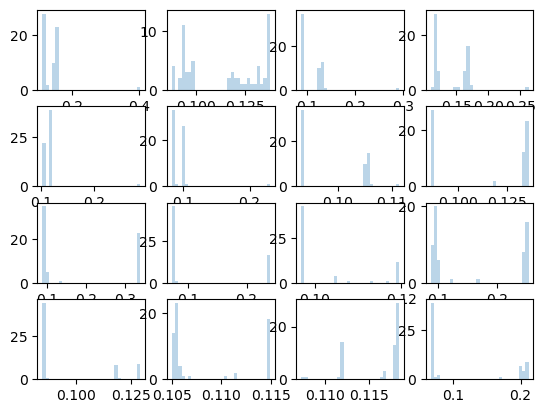

In [ ]:
plt.subplot(4,4,1)
for ii in range(subjs):
    plt.subplot(4,4,1+ii)
    plt.hist(rmse[ii,:], bins=30, alpha=0.3)

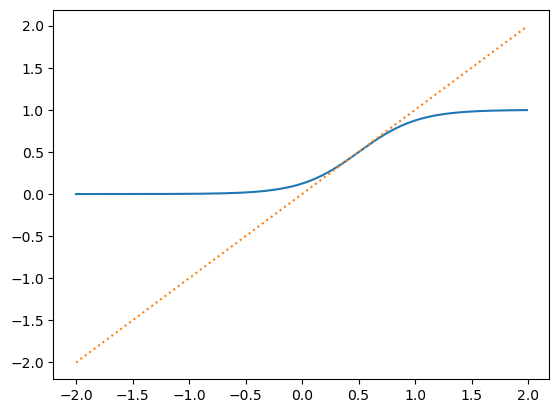

In [ ]:
sss = 0.4
nn = 1000
bbb = sss*np.random.normal(size=nn)
bbext = 0.2
xx = np.arange(-2,2,0.01)
yy = torch.nn.Sigmoid()(torch.tensor(4*xx.reshape(-1,1)-2+bbb.reshape(1,-1))).numpy().mean(axis=1)
plt.plot(xx, yy)
plt.plot(xx,xx,':')

In [ ]:
yy

array([4.84475275e-05, 5.04245929e-05, 5.24823343e-05, 5.46240432e-05,
       5.68531457e-05, 5.91732073e-05, 6.15879391e-05, 6.41012036e-05,
       6.67170209e-05, 6.94395748e-05, 7.22732200e-05, 7.52224886e-05,
       7.82920978e-05, 8.14869568e-05, 8.48121753e-05, 8.82730714e-05,
       9.18751798e-05, 9.56242610e-05, 9.95263105e-05, 1.03587568e-04,
       1.07814528e-04, 1.12213950e-04, 1.16792867e-04, 1.21558602e-04,
       1.26518775e-04, 1.31681315e-04, 1.37054477e-04, 1.42646851e-04,
       1.48467376e-04, 1.54525359e-04, 1.60830481e-04, 1.67392823e-04,
       1.74222873e-04, 1.81331547e-04, 1.88730208e-04, 1.96430678e-04,
       2.04445265e-04, 2.12786775e-04, 2.21468536e-04, 2.30504422e-04,
       2.39908867e-04, 2.49696898e-04, 2.59884149e-04, 2.70486894e-04,
       2.81522068e-04, 2.93007296e-04, 3.04960920e-04, 3.17402028e-04,
       3.30350487e-04, 3.43826968e-04, 3.57852987e-04, 3.72450934e-04,
       3.87644110e-04, 4.03456761e-04, 4.19914123e-04, 4.37042455e-04,
      

In [ ]:
best_model_state_dict['direct_injection_scale']

tensor([ 1.1913, -0.8288,  3.1312, -1.3732,  3.7969,  4.2563, -2.9289,  2.6430,
         1.7514,  4.3071,  2.3715,  3.9876, -2.5030, -0.1430,  1.4200,  2.5428])

In [ ]:
best_model_state_dict['u_feedback_scale']

KeyError: 'u_feedback_scale'

In [ ]:
best_model_state_dict['log_learning_rate']

tensor([[ -8.5036],
        [ -8.1889],
        [ -9.0752],
        [ -7.6101],
        [ -8.4537],
        [ -8.3702],
        [-10.1891],
        [ -6.9374],
        [ -7.6393],
        [ -9.2913],
        [ -7.2290],
        [ -8.2181],
        [-11.7016],
        [ -8.1480],
        [ -7.2848],
        [ -7.4659]])

In [ ]:
best_model_state_dict['log_learning_rate']

tensor([[ -8.5036],
        [ -8.1889],
        [ -9.0752],
        [ -7.6101],
        [ -8.4537],
        [ -8.3702],
        [-10.1891],
        [ -6.9374],
        [ -7.6393],
        [ -9.2913],
        [ -7.2290],
        [ -8.2181],
        [-11.7016],
        [ -8.1480],
        [ -7.2848],
        [ -7.4659]])

In [ ]:
np.exp(best_model_state_dict['log_learning_rate'])*128


tensor([[0.0260],
        [0.0355],
        [0.0147],
        [0.0634],
        [0.0273],
        [0.0297],
        [0.0048],
        [0.1243],
        [0.0616],
        [0.0118],
        [0.0928],
        [0.0345],
        [0.0011],
        [0.0370],
        [0.0878],
        [0.0733]])

In [ ]:
model.debug_lr0.sum(axis=1)

AttributeError: 'BatchedElboGenerativeModelTopMulti' object has no attribute 'debug_lr0'

In [ ]:
for key in best_model_state_dict:
    if not key.startswith('_'):
        print(key, best_model_state_dict[key].reshape(-1))

log_learning_rate tensor([ -8.3617,  -8.1247,  -8.4967,  -5.8379,  -9.4100,  -8.0888, -10.4307,
         -8.3321,  -8.2741,  -8.3314,  -9.7929,  -8.5760, -10.7210,  -7.0298,
         -8.3741,  -9.0634])
log_learning_rate_decay tensor([ 4.2657e+00,  4.2032e+00,  4.9990e+00,  6.1764e+00,  1.4173e+00,
         4.4232e+00,  4.2013e-03,  5.1707e+00,  3.8396e+00,  4.5598e+00,
         4.9993e+00,  3.0870e+00,  6.7557e+00,  4.5118e+00, -1.4903e+00,
         4.4029e+00])
sigma_b tensor([ 0.2012,  0.2980,  1.3175,  0.1976,  0.7285,  0.8187,  1.3013,  1.2038,
         0.5822, -0.7598, -1.0309,  0.1304,  1.8977,  0.2822,  0.2303, -1.3531])
output_scale tensor([0.9901, 1.0367, 1.0008, 0.8757, 0.9077, 0.8662, 1.0177, 1.0595, 1.0085,
        1.1819, 2.4706, 0.8599, 3.7581, 0.9288, 0.8408, 1.0420])
sp_weight_decay tensor([ -8.1878,  -6.1261,  -5.6568,  -9.2078,  -6.7253,  -6.2809,  -4.7845,
         -5.3328,  -7.0769,  -5.1222,  -3.4218,  -8.8017,  -3.4969,  -4.4678,
        -11.6433,  -5.6400])
sigm

In [ ]:
for key in best_model_state_dict:
    if not key.startswith('_'):
        print(key, best_model_state_dict[key].reshape(-1))

log_learning_rate tensor([ -8.2542,  -8.1918,  -8.1082,  -7.4592,  -9.4457,  -8.0151, -10.3804,
         -8.4306,  -8.3648,  -8.2055,  -9.6485,  -8.4772, -10.6201,  -6.9055,
         -8.1705,  -8.9159])
log_learning_rate_decay tensor([ 4.2433,  4.1664,  5.1265,  5.5417,  0.5003,  4.4531, -1.1994,  5.1191,
         3.6296,  4.5287,  4.9760,  3.1114,  6.7664,  4.4922, -0.8342,  4.3795])
sigma_b tensor([ 0.1885,  0.2882,  1.3648,  1.2518,  0.8294,  0.9271,  1.4334,  1.3876,
         0.6484, -0.7762, -1.0546,  0.1361,  2.0578,  0.3247,  0.1321, -1.3672])
output_scale tensor([0.9850, 1.0664, 0.9877, 0.9929, 0.9167, 0.8713, 1.0148, 1.0658, 1.0044,
        1.1878, 2.4703, 0.8596, 3.7779, 0.9304, 0.8153, 1.0452])
sp_weight_decay tensor([ -8.2613,  -6.1613,  -5.6898,  -5.6346,  -6.6327,  -6.1947,  -4.7597,
         -5.2916,  -7.0655,  -5.1402,  -3.4366,  -8.9174,  -3.4983,  -4.3725,
        -11.9049,  -5.6532])
sigma_x tensor([0.1005, 0.1088, 0.0553, 0.0325, 0.0921, 0.0340, 0.0220, 0.0712, 0.03

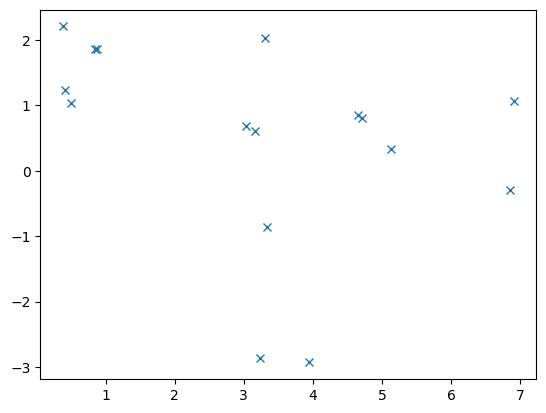

In [ ]:
plt.plot( best_model_state_dict['scsp_w_in_lr_'].reshape(-1), best_model_state_dict['scsp_w_in_decay_'].reshape(-1),'x')

In [ ]:
best_model_state_dict

OrderedDict([('log_learning_rate',
              tensor([[ -7.6139],
                      [ -7.8198],
                      [ -8.3296],
                      [ -7.3946],
                      [ -8.3731],
                      [ -7.2130],
                      [ -8.9496],
                      [ -7.7506],
                      [ -8.0251],
                      [ -7.8465],
                      [ -9.6313],
                      [ -7.1060],
                      [-10.5573],
                      [ -8.7070],
                      [ -7.0279],
                      [ -9.4148]])),
             ('log_learning_rate_decay',
              tensor([[ 2.8207],
                      [ 1.0260],
                      [ 2.2335],
                      [ 2.9026],
                      [-1.8546],
                      [ 1.7730],
                      [-1.3736],
                      [ 3.2317],
                      [ 1.7776],
                      [ 2.9313],
                      [ 2.1357],
              

In [ ]:
best_model_state_dict['sp_weight_decay']

tensor([[-7.0253, -2.2173],
        [-6.4083, -0.3292],
        [-5.6751,  1.4103],
        [ 0.0729, -6.9838],
        [-1.7333, -5.9443],
        [-5.5832,  0.6502],
        [-4.6110, -1.4350],
        [-5.7155,  0.9017],
        [-0.5803, -6.9070],
        [-5.2635,  0.4266],
        [-4.1996,  1.3261],
        [-3.1830, -6.7770],
        [-4.1871,  0.8330],
        [-4.4521, -0.6007],
        [-8.4699, -2.9765],
        [ 1.5468, -5.6760]])

In [ ]:
best_model_state_dict['output_scale']

tensor([1.0175, 1.0832, 0.8990, 0.9687, 0.9536, 0.9727, 0.8093, 1.1681, 0.9845,
        1.2220, 2.3499, 0.7986, 3.9132, 0.9858, 0.7938, 1.0301])

In [ ]:
best_model_state_dict['weight_decay_exp']

tensor([[2.0808],
        [0.9450],
        [1.1880],
        [2.1035],
        [1.1311],
        [1.1508],
        [0.6067],
        [1.1646],
        [2.0996],
        [2.0544],
        [0.5691],
        [1.4121],
        [0.6120],
        [0.6636],
        [1.6556],
        [1.1629]])

In [ ]:
best_model_state_dict['weight_learning_exp']

tensor([[0.5334],
        [0.5426],
        [0.6072],
        [0.5542],
        [0.7000],
        [0.6433],
        [1.1701],
        [0.5534],
        [0.5206],
        [0.5440],
        [1.1434],
        [0.6275],
        [0.6173],
        [1.2276],
        [1.6392],
        [0.6333]])

In [ ]:
model.args

namespace(apply_lr_decay=True,
          assume_opt_output_noise=True,
          bs=24,
          channel_trial_extra_error=0.0,
          direct_inj_limiter=1.0,
          disable_lpfs=True,
          enable_direct_injection=True,
          enable_elpf=False,
          enable_output_scale_tuning=True,
          enable_q_scale_tuning=True,
          enable_qlpf=False,
          enable_u_feedback_scale_tuning=False,
          enable_ylpf=False,
          injection_opt=3,
          lr_min_mult=0.1,
          model='default',
          model_tie_lr_weight_decay=False,
          multirate_m=1,
          n=256,
          nl_activation='relu',
          noise_injection_node='a',
          optimizer_alg='RMSprop',
          skip_gain=0.0,
          weight_decay_mode='softplus',
          zzz_legacy_init=False)

In [ ]:
ooo.keys()

dict_keys(['savings', 'AB0', 'AB1', 'AB2', 'AB3', 'AB4', 'AB5', 'spontaneous', 'evoked', 'visw1p2', 'visw1p1', 'visw1p3', 'albert_block_0', 'albert_block_1', 'albert_block_2', 'albert_block_3', 'albert_block_4', 'albert_block_5', 'albert_block_6', 'albert_block_7', 'albert_block_8', 'albert_block_9', 'albert_block_10', 'albert_block_11', 'albert_block_12', 'albert_block_13', 'albert_block_14', 'albert_block_15', 'albert_block_16', 'albert_block_17', 'albert_block_18', 'albert_block_19', 'albert_block_20', 'albert_block_21', 'albert_block_22', 'albert_block_23', 'albert_block_24', 'albert_block_25', 'albert_block_26', 'albert_block_27', 'albert_block_28', 'albert_block_29', 'albert_block_30', 'albert_block_31', 'albert_block_32', 'albert_block_33', 'albert_block_34', 'albert_block_35', 'albert_block_36', 'albert_block_37', 'albert_block_38', 'albert_block_39', 'albert_block_40', 'albert_block_41', 'albert_block_42', 'albert_block_43', 'albert_block_44', 'albert_block_45', 'albert_block_

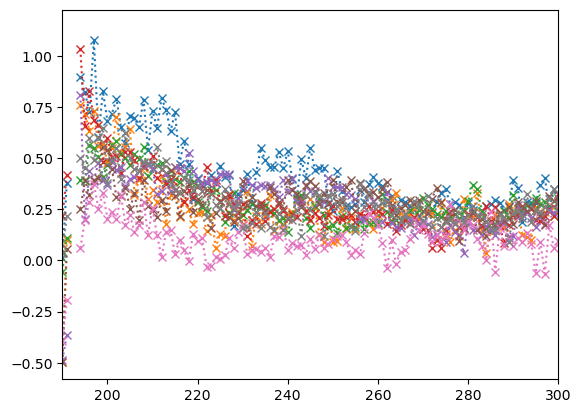

In [ ]:
for k in range(8):
    dd = a_exp[:,seeds*k]
    dd = dd*np.sign(np.nansum(dd))
    plt.plot(dd,':x')
    plt.xlim([190,300])

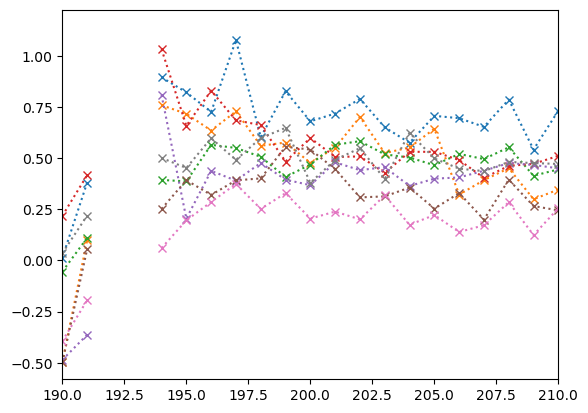

In [ ]:
for k in range(8):
    dd = a_exp[:,seeds*k]
    dd = dd*np.sign(np.nansum(dd))
    plt.plot(dd,':x')
    plt.xlim([190,210])

In [ ]:
p = np.sign(np.nansum(a_exp[:175,::seeds],axis=0))
dd = a_exp[:,::seeds]

Text(0.5, 1.0, 'ER: just before and just after the P+')

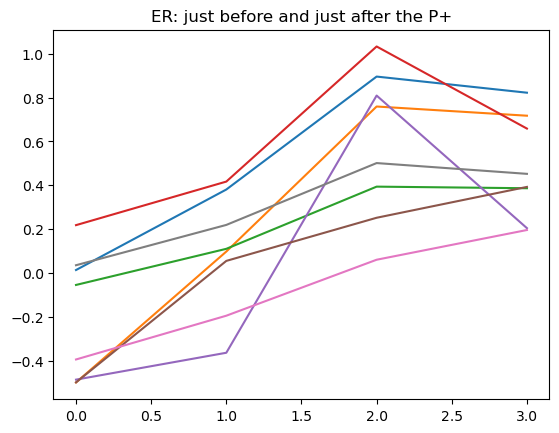

In [ ]:
plt.plot(dd[[190,191,194,195],:8]*p[:8])
plt.title('ER: just before and just after the P+')

(array([1., 0., 0., 0., 3., 3., 2., 3., 3., 1.]),
 array([-1.10669494, -0.97418321, -0.84167148, -0.70915975, -0.57664801,
        -0.44413628, -0.31162455, -0.17911282, -0.04660109,  0.08591064,
         0.21842237]),
 <BarContainer object of 10 artists>)

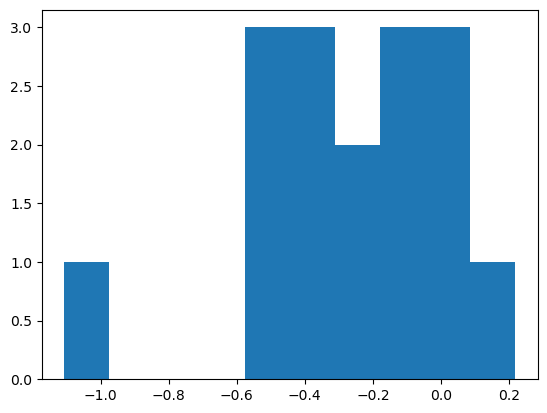

In [ ]:
plt.hist(dd[190,:]*p)

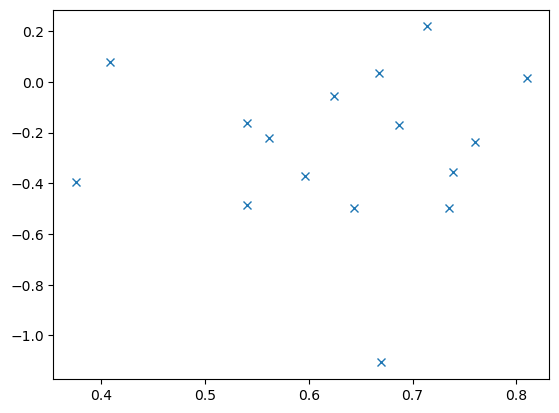

In [ ]:
plt.plot(np.nanmean(dd[50:80,:]*p, axis=0), dd[190,:]*p, 'x')

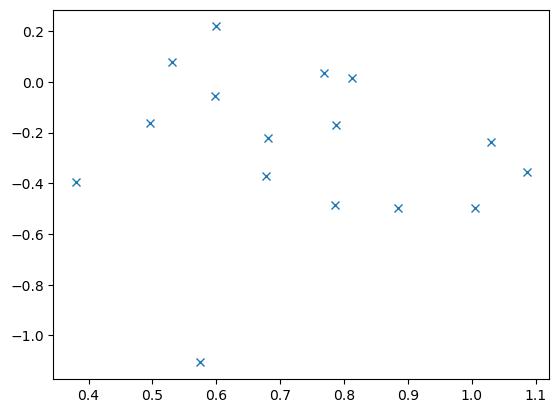

In [ ]:
plt.plot(np.nanmean(dd[60:70,:]*p, axis=0), dd[190,:]*p, 'x')

In [ ]:
from scipy.stats import spearmanr
spearmanr(np.nanmean(dd[60:70,:]*p, axis=0), dd[190,:]*p)

SignificanceResult(statistic=-0.22941176470588234, pvalue=0.39272049088161975)

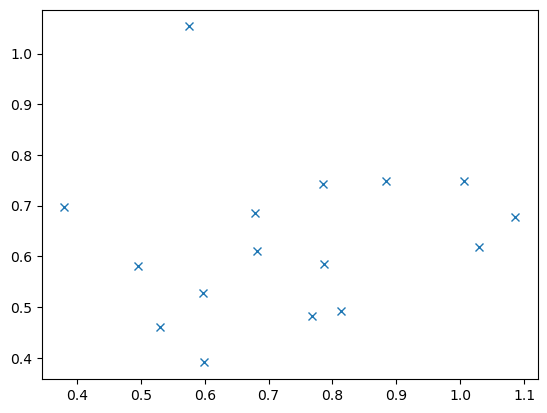

In [ ]:
plt.plot(np.nanmean(dd[60:70,:]*p, axis=0), (1-dd[190,:]*p)/2, 'x')

In [ ]:
template = 'multirate'#'state-space'
mode = 'ERSR'
n_subjects = 1
n_seeds = 1
priority_intervals = None
priority_factor = None
if template == 'lr_reduct':
        args = SimpleNamespace(
        model='default',
        enable_q_scale_tuning= mode == 'MU',
        assume_opt_output_noise=True,
        enable_qlpf=False,
        enable_ylpf=False,
        enable_elpf=False,
        multirate_m=1,          # 
        apply_lr_decay=True, #False,
        noise_injection_node='a',
        model_tie_lr_weight_decay=False,
        bs=n_subjects * n_seeds,                      # IMPORTANT: one batch entry per subject
        zzz_legacy_init=False,
        enable_output_scale_tuning= True, #False,# mode == 'MU',
        enable_u_feedback_scale_tuning=False, #True,
        enable_direct_injection= True , #mode == 'MU',
        injection_opt=3,            # 
        skip_gain=0.0,
        channel_trial_extra_error=0.0,
        lr_min_mult = 1e-1,
        weight_decay_mode='softplus', #'sigmoid', #
        # weight_decay_mode='sigmoid',
        nl_activation='relu',
        n=128 if mode == 'ERSR' else 256,
        disable_lpfs=True,
        optimizer_alg='RMSprop',
        n_seeds=n_seeds,
        # direct_inj_limiter=0.45,
    )
elif template == 'multirate':
    args = SimpleNamespace(
        model='default',
        enable_q_scale_tuning= mode == 'MU',
        assume_opt_output_noise=True,
        enable_qlpf=False,
        enable_ylpf=False,
        enable_elpf=False,
        multirate_m=1,          # 
        apply_lr_decay=False, #False,
        noise_injection_node='a',
        model_tie_lr_weight_decay=False,
        bs=n_subjects * n_seeds,                      # IMPORTANT: one batch entry per subject
        zzz_legacy_init=False,
        enable_output_scale_tuning= False, #False,# mode == 'MU',
        enable_u_feedback_scale_tuning=False, #True,
        enable_direct_injection= True , #mode == 'MU',
        injection_opt=3,            # 
        skip_gain=0.0,
        channel_trial_extra_error=0.0,
        lr_min_mult = 1e-1,
        weight_decay_mode='softplus', #'sigmoid', #
        # weight_decay_mode='clipped_sigmoid',
        weight_decay_max=1.0,
        nl_activation= 'rescaled_sigmoid',#'rescaled_sigmoid',#'relu', #['relu', 'const'], # 'rescaled_sigmoid', #'relu', #
        n=128 if mode == 'ERSR' else 256,
        disable_lpfs=True,
        optimizer_alg= 'RMSprop', # 'RMSprop',
        n_seeds=n_seeds,
        priority_intervals=priority_intervals,
        priority_factor=priority_factor,
        lr_bound = None, #1./512.,
        bound_weight_decay = True,
        enable_weight_learning_exp = True,
        enable_weight_decay_exp = True,
        enable_bias_update = False,
        develop_b_tgt = -2.0,
        enable_w_in_plasticity = True,

        # direct_inj_limiter=0.45,
    )
elif template == 'state-space':
    args = SimpleNamespace(
        model='default',
        enable_q_scale_tuning= mode == 'MU',
        assume_opt_output_noise=True,
        enable_qlpf=False,
        enable_ylpf=False,
        enable_elpf=False,
        multirate_m=1,          # 
        apply_lr_decay=False, #False,
        noise_injection_node='a',
        model_tie_lr_weight_decay=False,
        bs=n_subjects * n_seeds,                      # IMPORTANT: one batch entry per subject
        zzz_legacy_init=False,
        enable_output_scale_tuning= False, #False,# mode == 'MU',
        enable_u_feedback_scale_tuning=False, #True,
        enable_direct_injection= False , #mode == 'MU',
        injection_opt=3,            # you’re using opt=2 in the model code
        skip_gain=0.0,
        channel_trial_extra_error=0.0,
        lr_min_mult = 1e-1,
        weight_decay_mode='softplus', #'sigmoid', #
        # weight_decay_mode='clipped_sigmoid',
        weight_decay_max=1.0,
        nl_activation='const', #['relu', 'const'], # 'rescaled_sigmoid', #'relu', #
        n=1 if mode == 'ERSR' else 256,
        disable_lpfs=True,
        optimizer_alg= 'RMSprop', # 'RMSprop',
        n_seeds=n_seeds,
        priority_intervals=priority_intervals,
        priority_factor=priority_factor,
        enable_sigma_b_tuning = False,
        lr_bound = None, #0.99,
        bound_weight_decay = True,
        enable_weight_decay_exp = True,
        enable_weight_learning_exp = True,
        enable_bias_update = True
        # direct_inj_limiter=0.45,
    )

In [ ]:
model = BatchedElboGenerativeModelTopMulti(device=device, args=args).to(device)
model.get_biases_and_w_in(args.n, device=device)


(tensor([[ 0.0504, -0.6542,  0.1057,  0.8525, -0.0510,  0.0358,  0.2735, -0.2431,
           0.3110, -0.2728,  0.4888,  0.1611,  0.3387, -0.2516, -0.1031,  0.0723,
          -0.1146, -0.0565,  0.5255, -0.2016,  0.4458, -0.6245,  0.2140,  0.3246,
          -0.8554, -0.1893,  0.5485,  0.6955,  0.0921,  0.0433,  0.3781, -0.4911,
           0.2981,  0.0761, -0.2190, -0.3054, -0.2167, -0.0393,  0.1958,  0.0134,
          -0.0436, -0.0912,  0.2099,  0.0311, -0.2707, -0.7426,  0.1453, -0.0114,
          -0.4138, -0.4529,  0.4656, -0.6175, -0.4555, -0.5340, -0.3283,  0.1538,
          -0.1774, -0.2352,  0.1361,  0.0985,  0.5355, -0.1737,  0.0514, -0.6489,
           0.1751,  0.2077,  0.1641, -0.2215, -0.6385, -0.4455,  0.3846,  0.7606,
           0.1109,  0.0208,  0.2984,  0.1029,  0.1694,  0.3426, -0.0880,  0.3739,
           0.3389,  0.0367, -0.0415, -0.2672, -0.1364,  0.0655,  0.3116,  0.0716,
          -0.1372,  0.0047,  0.2006, -0.3774, -0.3000, -0.5203,  0.9797, -0.0913,
          -0.504

In [ ]:
model_state_dict = model.state_dict()
k_params = compute_k_params(model_state_dict)

param: log_learning_rate, size: 1
param: sigma_b, size: 1
param: sp_weight_decay, size: 1
param: weight_decay_exp, size: 1
param: weight_learning_exp, size: 1
param: w_in_lr, size: 1
param: w_in_decay, size: 1
param: direct_injection_scale, size: 1


In [ ]:
from optimise_clnn import load_subject_data

all_ys = []
all_a_exp = []
all_qs = []
lengths = []

mode =  'ERSR' #'ERSR' #'MU' 
paradigm_ = {k: 'evoked' if k <= 8 else 'spontaneous' for k in range(1, 17)}

for k in range(1, n_subjects + 1):
    if mode == 'ERSR':
        csv_path = f'/homes/ar2342/frogs_project/data/COIN_data/trial_data_{paradigm_[k]}_recovery_participant{(k-1)%8+1}.csv'
    else:
        csv_path = f'/homes/ar2342/frogs_project/data/COIN_data/trial_data_memory_updating_participant{k}.csv'
    experimental_data = load_subject_data(csv_path)

    a_exp = np.asarray(experimental_data[0], dtype=np.float32)  # target (your a_exp)
    ys    = np.asarray(experimental_data[1], dtype=np.float32)  # input ys (your ys)
    if mode == 'MU':
        qs = np.asarray(experimental_data[2], dtype=np.float32)  # input qs (your qs)

    for _ in range(n_seeds):
        all_a_exp.append(a_exp)
        all_ys.append(ys)
        if mode == 'MU':
            all_qs.append(qs)
        lengths.append(len(a_exp))

NameError: name 'n_subjects' is not defined

In [ ]:
outputs = []
# pp_list = [0.25, 0.5,1,2,3]
pp_list = [0.0,3e-3,1e-2,3e-2,1e-1]
for pp in pp_list:
    forced_params = {
                    #'log_learning_rate_decay': -20., 
                    # 'sigma_x': 1e-7, 
                    'log_learning_rate': -5.50,
                    'sp_weight_decay': -6.5,
                    # 'output_scale': 1.0,
                    # 'u_feedback_scale': 1.0,
                    'sigma_b': 0.5,
                    #'q_scale': 0.9,
                    #  'tauelpf_m1': -1000.0,
                    #  'tauqlpf_m1': -1000.0,
                     'direct_injection_scale': 0.5,
                    'weight_decay_exp': 1.0,
                    'weight_learning_exp': 1.0,
                    'weight_decay_exp': 1.0,
                    'bias_lr':pp,
                    }
    force_model_params(model, forced_params)


    ys = torch.tensor(all_ys[0], device=next(model.parameters()).device)
    #duplicate ys across batch size
    ys = ys.unsqueeze(0).repeat(args.bs, 1)  # [bs, t]
    print(f'ys shape after unsqueeze and repeat: {ys.shape}')
    # noises = torch.randn((args.bs, ys.shape[1]), device=next(model.parameters()).device) * model.sigma_x  # [bs, t]
    noises = torch.zeros((args.bs, ys.shape[1]), device=next(model.parameters()).device)  # [bs, t]
    print(f'noises shape before splitting: {noises.shape}')
    noises = [noises[:, t_idx] for t_idx in range(noises.shape[1])]
    print(f'noises shape after splitting: {noises[0].shape}, number of noise tensors: {len(noises)}')
    ys = [ys[:, t_idx] for t_idx in range(ys.shape[1])]
    print(f'noises shape: {noises[0].shape}, ys shape: {ys[0].shape}')
    model_setting = args.model
    outputs_ = model.f(args.n,
                        noises,
                        ys,  
                        model_setting,
                        qs=None,
                        )
    outputs.append(np.array([z.cpu().detach().numpy().reshape(-1) for z in outputs_]))
# plt.ylim(-1.2,1.2)

Forcing parameter log_learning_rate to value -5.5
Forcing parameter sigma_b to value 0.5
Forcing parameter sp_weight_decay to value -6.5


IndexError: list index out of range

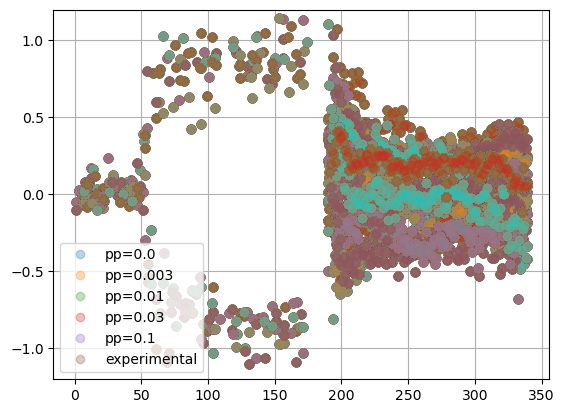

In [ ]:
for oo, out in enumerate(outputs):
    print(out.shape)
    plt.plot(out,'-')
plt.plot(a_exp, 'o',alpha=0.3)
plt.ylim(-1.2,1.2)
plt.legend([f'pp={pp}' for pp in pp_list]+['experimental'], loc='lower left')
# plt.plot(outputs[0],'-',linewidth=3, color='black')
# plt.xlim(188,200)#,53)
plt.grid()

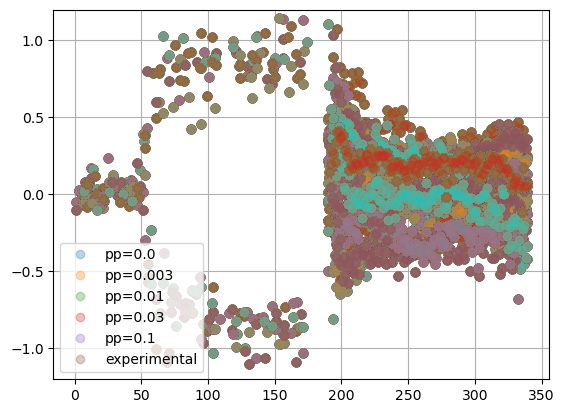

In [ ]:
for oo, out in enumerate(outputs):
    print(out.shape)
    plt.plot(out,'-')
plt.plot(a_exp, 'o',alpha=0.3)
plt.ylim(-1.2,1.2)
plt.legend([f'pp={pp}' for pp in pp_list]+['experimental'], loc='lower left')
# plt.plot(outputs[0],'-',linewidth=3, color='black')
# plt.xlim(188,200)#,53)
plt.grid()

In [ ]:
plt.plot(all_ys[0])

IndexError: list index out of range

In [ ]:
a_exp


array([        nan,         nan,         nan,         nan,  0.02277484,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan, -0.0534388 ,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,  0.12124509,
               nan,         nan,         nan,         nan,         nan,
        0.03530996,         nan,         nan,         nan,         nan,
               nan,         nan,  0.09142897,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,         nan,
               nan,         nan,         nan,         nan,  0.7877995 ,
               nan,         nan,         nan,         nan,  0.8127609 ,
               nan,         nan,         nan,         nan,      

In [ ]:
ms = [1, 2]
gs = [1, 2]
clnn_flags = [False, True]
outs_by_flag = {}
for clnn_flag in clnn_flags:
    outs_for_flag = {}
    clnn_prefix = 'CLNN' if clnn_flag else ''
    for m in ms:
        for g in gs:
            result_path = f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group{g}_{clnn_prefix}m{m}/'
            outs_for_flag[(g, m)] = read_rmse_and_bic_from_path(result_path, seeds=128)
    outs_by_flag[clnn_flag] = outs_for_flag

# Keep the downstream cells working with the CLNN results by default.
outs = outs_by_flag[True]

param: log_learning_rate, size: 1
param: sp_weight_decay, size: 1
detected k_params: 2
detected subjs: 16
param: log_learning_rate, size: 1
param: sp_weight_decay, size: 1
detected k_params: 2
detected subjs: 21
param: log_learning_rate, size: 2
param: sp_weight_decay, size: 2
detected k_params: 4
detected subjs: 16
param: log_learning_rate, size: 2
param: sp_weight_decay, size: 2
detected k_params: 4
detected subjs: 21
param: log_learning_rate, size: 1
param: sigma_b, size: 1
param: sp_weight_decay, size: 1
detected k_params: 3
detected subjs: 16


FileNotFoundError: [Errno 2] No such file or directory: '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group2_CLNNm1/model_state_dict.pt'

In [ ]:
outs[(1,1)]['best_bics']-outs[(1,2)]['best_bics']

NameError: name 'outs' is not defined

NameError: name 'gs' is not defined

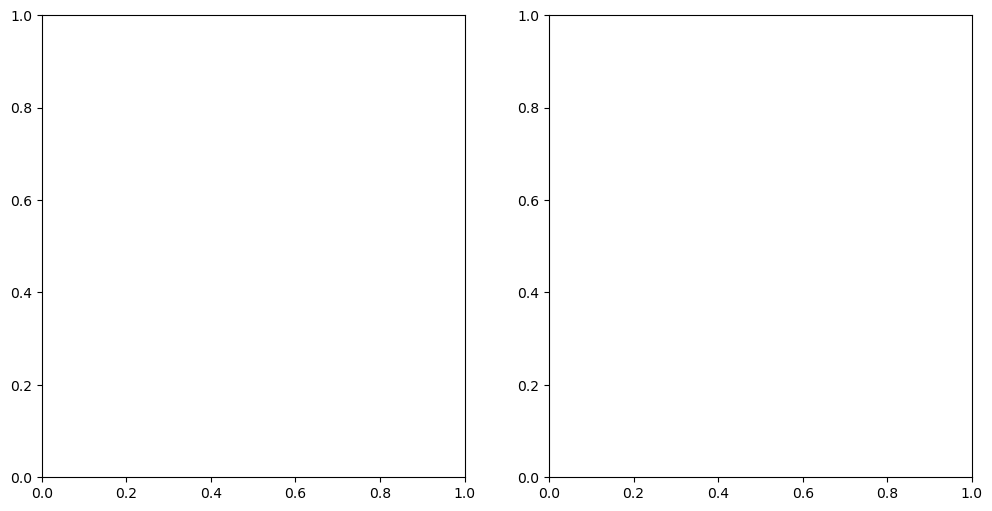

In [ ]:
plt.subplots(1,2, figsize=(12,6))
for i, g in enumerate(gs):
    plt.subplot(1,2,i+1)
    plt.stem(outs[(g,1)]['best_bics']-outs[(g,2)]['best_bics'])
    plt.title(f'group {g}')
    plt.xlabel('participant')
    if i==0:
        plt.ylabel('multirate BIC difference\nm=1 minus m=2\npositive = m=2 better')

In [ ]:
slowing_down_bics = read_rmse_and_bic_from_path('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_LRmin_basicBwdCapatRMSprop_NEW/', seeds=128)

param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
detected k_params: 5


In [ ]:
dual_rate_bics = read_rmse_and_bic_from_path('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m2/', seeds=128)
xconsolidation_bics = read_rmse_and_bic_from_path('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_CLNNm1Xconsolidation/', seeds=128)

param: log_learning_rate, size: 2
param: sp_weight_decay, size: 2
detected k_params: 4
param: log_learning_rate, size: 1
param: sigma_b, size: 1
param: sp_weight_decay, size: 1
param: x_slow_alpha, size: 1
param: x_fast_gain, size: 1
detected k_params: 5


/tmp/ipykernel_1007404/419064470.py:10: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])


<StemContainer object of 3 artists>

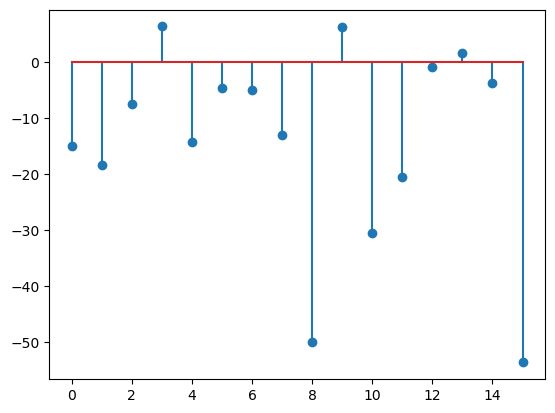

In [ ]:
plt.stem(slowing_down_bics['best_bics'] - dual_rate_bics['best_bics'])

<StemContainer object of 3 artists>

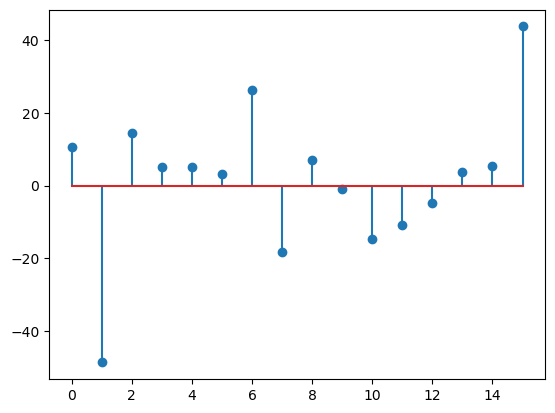

In [ ]:
plt.stem(xconsolidation_bics['best_bics'] - dual_rate_bics['best_bics'])

In [ ]:
dual_rate_bics

{'best_rmse': array([0.1484945 , 0.15463776, 0.11533262, 0.30985589, 0.15546782,
        0.15663422, 0.12667992, 0.15403454, 0.16300271, 0.31236461,
        0.19450053, 0.16488302, 0.2476111 , 0.12852243, 0.19182354,
        0.06255188]),
 'best_bics': array([-119.79350727, -108.1997922 , -192.07359317,   90.57648184,
        -106.66872197, -104.5310155 , -165.23442862, -109.3176259 ,
         -93.13289581,   92.88273176,  -42.60583396,  -89.85264089,
          26.44157192, -161.10462386,  -46.56950988, -367.05527339])}

In [ ]:
run1 = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp_repeat/'
run2 = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_rich_scsp/'

run1 ='/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled/'
run2 = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/hello_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_try2/'


param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
detected k_params: 5
detected subjs: 16


/tmp/ipykernel_667391/4101126321.py:11: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])


param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
detected k_params: 5
detected subjs: 16


<StemContainer object of 3 artists>

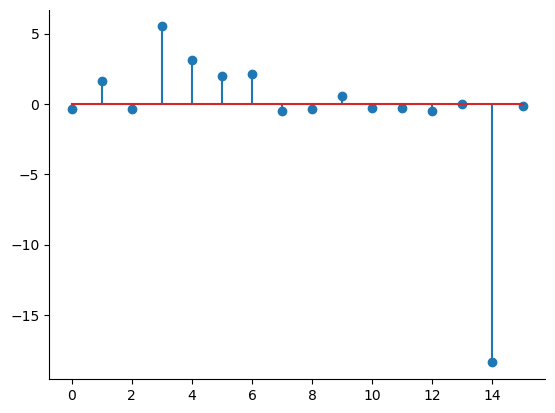

In [ ]:
#compare bics
bic1 = read_rmse_and_bic_from_path(run1, seeds=128//2)['best_bics']
bic2 = read_rmse_and_bic_from_path(run2, seeds=128//2)['best_bics']
plt.stem(bic1 - bic2)

In [ ]:


lerner_dual_rate_bics = read_rmse_and_bic_from_path('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_group1_m2/', seeds=128)
signoff_candidate_bics = read_rmse_and_bic_from_path('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/lerner_g1_part2_LRmin_basicBwdCapatRMSprop_NEWveryFudgeDisabled_LRrecover5em3_noLRmin/', seeds=128//2)

param: log_learning_rate, size: 2
param: sp_weight_decay, size: 2
detected k_params: 4
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
detected k_params: 5
detected subjs: 16


<StemContainer object of 3 artists>

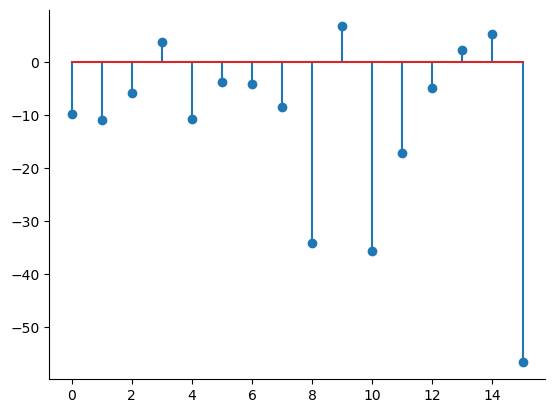

In [ ]:
plt.stem(signoff_candidate_bics['best_bics'] - lerner_dual_rate_bics['best_bics'])

In [ ]:
# runs = [f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/default_with_seeds_{i}' for i in range(1,6)]

# runs = [f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/defaultXL_with_seeds_{i}' for i in range(1,41)]
# runs = [f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/inj0p4_with_seeds_{i}' for i in range(1,21)]
# runs = [f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/scaleOutClmp_inj0p4_with_seeds_{i}' for i in range(1,21)]
runs = [f'/homes/ar2342/one_more_dir/contextual_frogs/results_part2/xlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_{i}' for i in range(1,11)]



In [ ]:
bics = [read_rmse_and_bic_from_path(run, seeds=128//2)['best_bics'] for run in runs]

param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16


/tmp/ipykernel_1407845/1418099574.py:40: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2,axis=0)).reshape([subjs, seeds])


param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b, size: 1
param: output_scale, size: 1
param: sp_weight_decay, size: 1
param: x_fast_alpha, size: 1
detected k_params: 6
detected subjs: 16
param: log_learning_rate, size: 1
param: log_learning_rate_decay, size: 1
param: sigma_b

In [ ]:
bics

[array([-265.67977726, -302.27608887, -340.35124262, -282.02128436,
        -263.3118503 , -336.4610868 , -308.70586978, -348.04567194,
        -324.45630448, -358.84459386, -256.35794327, -329.11653436,
        -274.87823048, -244.19372136, -235.32648986, -400.41242423]),
 array([-266.68219209, -298.78802567, -340.70071212, -287.54670248,
        -257.69019214, -336.6371467 , -308.75554868, -340.93980271,
        -324.11717382, -362.73425332, -256.9927757 , -325.75836199,
        -276.84461908, -244.46807387, -253.04794499, -402.0847001 ]),
 array([-268.59361892, -301.73882323, -341.60115295, -289.80221295,
        -256.56420451, -336.62382535, -308.7193237 , -345.37020212,
        -324.35677566, -358.53809293, -257.1835084 , -324.25748659,
        -277.96718878, -244.21324709, -250.35608015, -402.22269559]),
 array([-268.69922418, -300.92474274, -343.00119029, -288.96754538,
        -266.04110956, -336.17354717, -308.7504118 , -342.61544975,
        -324.31380761, -362.89155589, -256

In [ ]:
from scipy.special import logsumexp
properly_pooled_bics = -2*(logsumexp(-np.array(bics)/2, axis=0) - np.log(len(bics)))

Text(0, 0.5, 'BIC difference from mean across runs')

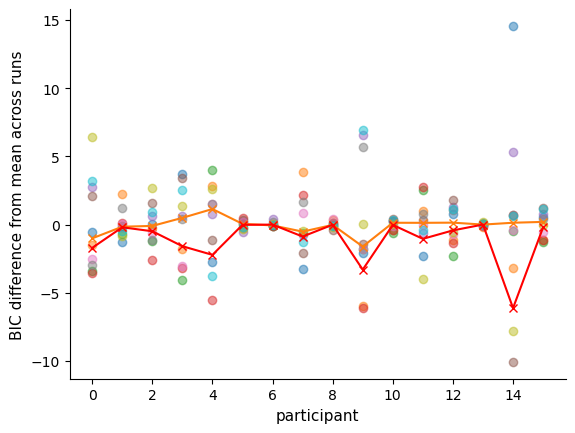

In [ ]:
for bic in bics:
    plt.plot(bic - np.mean(bics, axis=0), 'o', alpha=0.5)
# plt.plot(these_bics - np.mean(bics, axis=0), 'x-', color='k')
plt.plot(np.median(bics, axis=0) - np.mean(bics, axis=0), 'x-', color='tab:orange')
plt.plot(properly_pooled_bics - np.mean(bics, axis=0), 'x-', color='r')
plt.xlabel('participant')
plt.ylabel('BIC difference from mean across runs')

(array([1., 0., 1., 3., 1., 0., 0., 2., 1., 1.]),
 array([-306.00843822, -305.79004217, -305.57164611, -305.35325006,
        -305.134854  , -304.91645794, -304.69806189, -304.47966583,
        -304.26126978, -304.04287372, -303.82447766]),
 <BarContainer object of 10 artists>)

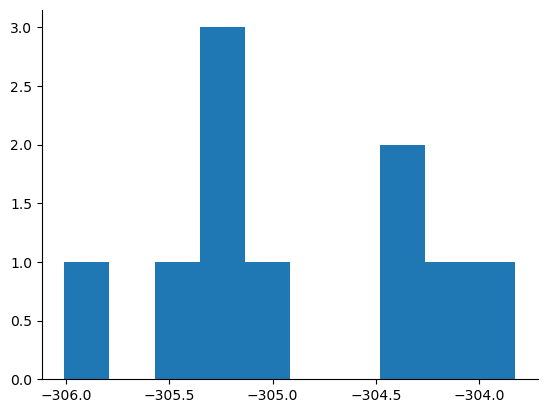

In [ ]:
plt.hist(np.mean(bics, axis=1))

In [ ]:
np.argmin([bic for bic in bics],axis=0)

array([3, 0, 3, 2, 3, 4, 1, 0, 5, 3, 2, 8, 2, 1, 5, 2])

In [ ]:
bics[3]

array([-241.91478041, -308.5536589 , -312.70440824, -229.43403182,
       -258.2422228 , -304.59981745, -288.2753702 , -319.15199686,
       -313.19665537, -357.29733406, -272.58532513, -318.38333267,
       -309.84812831, -253.23261677, -254.59421272, -397.12548602])

In [ ]:
x = [100] +[97]*10 
x_ = logsumexp(x) - np.log(len(x))
x_

98.00614928258814

In [ ]:
bics_np = np.array([bic for bic in bics])

In [ ]:
bics_np[:,3]

array([-223.46859197, -226.30515229, -226.91006908, -229.43403182,
       -233.40315139, -222.52536608, -238.86157191, -222.0051274 ,
       -220.56899021, -221.05649487, -281.15559643, -221.29046264,
       -215.90354139, -221.08395528, -223.27877789, -225.62334564,
       -219.31520461, -222.85395681, -254.18780252, -221.72752911])

In [ ]:
best_model_state_dict

OrderedDict([('log_learning_rate',
              tensor([[ -7.5999],
                      [ -8.0984],
                      [ -9.5668],
                      [ -7.1843],
                      [ -9.0629],
                      [ -7.5463],
                      [-10.4069],
                      [ -9.1919],
                      [ -7.7472],
                      [ -7.8463],
                      [ -9.6030],
                      [ -7.6878],
                      [-10.5777],
                      [ -8.6260],
                      [ -7.3237],
                      [ -9.1971]])),
             ('log_learning_rate_decay',
              tensor([[ 1.0182],
                      [ 0.6782],
                      [-0.1314],
                      [ 2.0614],
                      [-2.4649],
                      [ 0.6447],
                      [-2.9630],
                      [ 0.4421],
                      [ 0.1261],
                      [ 0.8604],
                      [-0.3417],
              

In [ ]:
args

namespace(apply_lr_decay=True,
          apply_scaled_soft_plus_on_w_in_params=False,
          assume_opt_output_noise=True,
          bound_weight_decay=False,
          bs=16,
          channel_trial_extra_error=0.0,
          debug_flag_win2nd_column_positive_only=False,
          develop_b_tgt=0.0,
          direct_inj_limiter=1.0,
          disable_lpfs=True,
          enable_bias_update=False,
          enable_direct_injection=False,
          enable_elpf=False,
          enable_input_scale_tuning=True,
          enable_output_scale_tuning=False,
          enable_q_scale_tuning=False,
          enable_qlpf=False,
          enable_separate_win_per_rate=False,
          enable_sigma_b_tuning=True,
          enable_u_feedback_scale_tuning=False,
          enable_w_in_plasticity=False,
          enable_w_in_scale_tuning=False,
          enable_weight_decay_exp=False,
          enable_weight_learning_exp=False,
          enable_ylpf=False,
          enforce_positive_biases=False,
   

In [ ]:
x_pert

0.8999977

In [ ]:
Ppert

NameError: name 'Ppert' is not defined

/tmp/ipykernel_1407845/4209771798.py:63: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2, axis=0)).reshape(subjs, seeds_for_compare)
/tmp/ipykernel_1407845/4209771798.py:85: RuntimeWarning: Mean of empty slice
  'mean_exp_er': np.nanmean(best_exp[:, :split_idx], axis=1),
/tmp/ipykernel_1407845/4209771798.py:86: RuntimeWarning: Mean of empty slice
  'mean_exp_sr': np.nanmean(best_exp[:, split_idx:], axis=1),
/scratch/ar2342/miconda3/envs/py_frogs/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1878: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


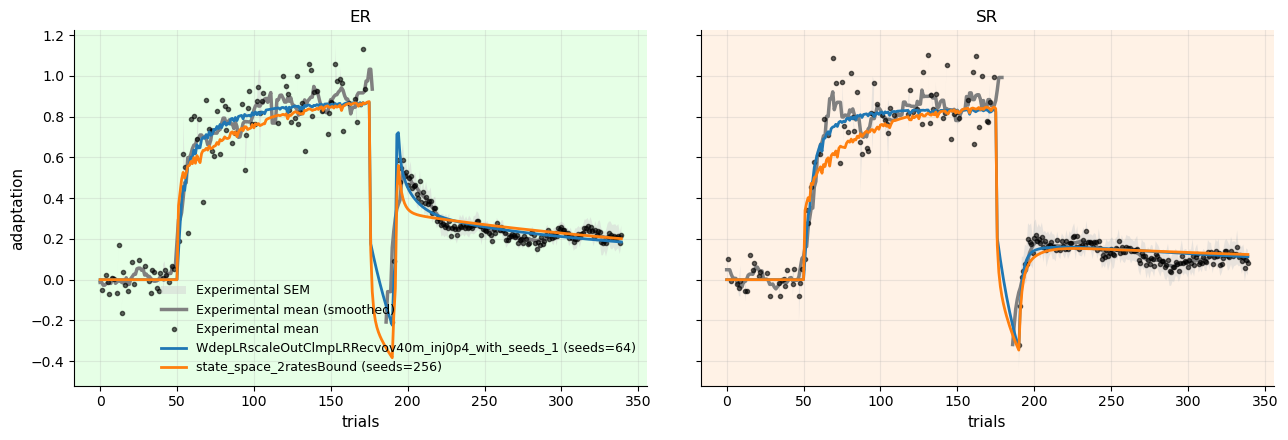

In [ ]:
# Compare two result folders via best-MSE fits, averaged over ER and SR participants separately.
# result_path_a = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
# result_path_a = result_path
result_path_a = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/WdepLRscaleOutClmpLRRecvov40m_inj0p4_with_seeds_1'
result_path_b = '/homes/ar2342/one_more_dir/contextual_frogs/results_part2/state_space_2ratesBound/'
split_idx = 8  # first 8 participants are ER; the remainder are SR

# Set these explicitly when known. If one is left as None, it can be inferred from the other path's subject count.
seeds_a = seeds
seeds_b = None

def moving_average(x, window=9):
    x = np.asarray(x, dtype=float)
    window = max(1, int(window))
    if window == 1:
        return x.copy()

    pad_left = window // 2
    pad_right = window - 1 - pad_left
    x_pad = np.pad(x, (pad_left, pad_right), mode='edge')

    valid = np.isfinite(x_pad).astype(float)
    x_filled = np.where(np.isfinite(x_pad), x_pad, 0.0)
    kernel = np.ones(window, dtype=float)

    numer = np.convolve(x_filled, kernel, mode='valid')
    denom = np.convolve(valid, kernel, mode='valid')

    out = np.full_like(numer, np.nan, dtype=float)
    np.divide(numer, denom, out=out, where=denom > 0)
    return out

def load_best_fit_summary(result_path, split_idx=8, seeds_for_compare=None, expected_subjs=None):
    a_exp = np.loadtxt(os.path.join(result_path, 'a_exp.txt'))
    a_pred = np.loadtxt(os.path.join(result_path, 'a_pred.txt'))

    if a_exp.shape != a_pred.shape:
        raise ValueError(f'Shape mismatch in {result_path}: a_exp {a_exp.shape} vs a_pred {a_pred.shape}')

    n_cols = a_exp.shape[1]
    if seeds_for_compare is None:
        if expected_subjs is None:
            raise ValueError(
                'Need either seeds_for_compare or expected_subjs to determine the seed count for '
                f'{result_path}'
            )
        if n_cols % expected_subjs != 0:
            raise ValueError(
                f'Number of columns ({n_cols}) in {result_path} is not divisible by expected_subjs={expected_subjs}'
            )
        subjs = expected_subjs
        seeds_for_compare = n_cols // subjs
    else:
        if n_cols % seeds_for_compare != 0:
            raise ValueError(
                f'Number of columns ({n_cols}) in {result_path} is not divisible by seeds={seeds_for_compare}'
            )
        subjs = n_cols // seeds_for_compare

    if split_idx <= 0 or split_idx >= subjs:
        raise ValueError(f'Invalid split_idx={split_idx} for subjs={subjs}')

    rmse = np.sqrt(np.nanmean((a_exp - a_pred) ** 2, axis=0)).reshape(subjs, seeds_for_compare)
    best_seed_idx = np.nanargmin(rmse, axis=1)
    best_exp = np.full((a_exp.shape[0], subjs), np.nan)
    best_pred = np.full((a_pred.shape[0], subjs), np.nan)

    for subj in range(subjs):
        col_idx = subj * seeds_for_compare + best_seed_idx[subj]
        this_exp = a_exp[:, col_idx].copy()
        this_pred = a_pred[:, col_idx].copy()
        polarity = np.sign(np.nanmean(this_exp[:175]))
        if not np.isfinite(polarity) or polarity == 0:
            polarity = 1.0
        best_exp[:, subj] = polarity * this_exp
        best_pred[:, subj] = polarity * this_pred

    return {
        'result_path': result_path,
        'subjs': subjs,
        'seeds_for_compare': seeds_for_compare,
        'best_seed_idx': best_seed_idx,
        'best_exp': best_exp,
        'best_pred': best_pred,
        'mean_exp_er': np.nanmean(best_exp[:, :split_idx], axis=1),
        'mean_exp_sr': np.nanmean(best_exp[:, split_idx:], axis=1),
        'mean_pred_er': np.nanmean(best_pred[:, :split_idx], axis=1),
        'mean_pred_sr': np.nanmean(best_pred[:, split_idx:], axis=1),
    }

summary_a = load_best_fit_summary(
    result_path_a,
    split_idx=split_idx,
    seeds_for_compare=seeds_a,
)
summary_b = load_best_fit_summary(
    result_path_b,
    split_idx=split_idx,
    seeds_for_compare=seeds_b,
    expected_subjs=summary_a['subjs'],
)

if summary_a['subjs'] != summary_b['subjs']:
    raise ValueError(f"Subject count mismatch: {summary_a['subjs']} vs {summary_b['subjs']}")
if not np.allclose(summary_a['mean_exp_er'], summary_b['mean_exp_er'], equal_nan=True):
    raise ValueError('Averaged ER experimental data differs between the two result paths.')
if not np.allclose(summary_a['mean_exp_sr'], summary_b['mean_exp_sr'], equal_nan=True):
    raise ValueError('Averaged SR experimental data differs between the two result paths.')

label_a = os.path.basename(os.path.normpath(result_path_a)) or result_path_a
label_b = os.path.basename(os.path.normpath(result_path_b)) or result_path_b
trial_idx = np.arange(summary_a['mean_exp_er'].shape[0])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
group_specs = [
    ('ER', 'mean_exp_er', 'mean_pred_er', (0.90, 1.00, 0.90), summary_a['best_exp'][:, :split_idx]),
    ('SR', 'mean_exp_sr', 'mean_pred_sr', (1.00, 0.95, 0.90), summary_a['best_exp'][:, split_idx:]),
]

for ax, (group_name, exp_key, pred_key, facecolor, exp_mat) in zip(axes, group_specs):
    ax.set_facecolor(facecolor)

    exp_mean = summary_a[exp_key]
    exp_n = np.sum(~np.isnan(exp_mat), axis=1)
    exp_sem = np.divide(
        np.nanstd(exp_mat, axis=1, ddof=1),
        np.sqrt(exp_n),
        out=np.zeros_like(exp_mean, dtype=float),
        where=exp_n > 1,
    )
    exp_mean_smooth = moving_average(exp_mean, window=10)

    ax.fill_between(
        trial_idx,
        exp_mean - exp_sem,
        exp_mean + exp_sem,
        color='lightgray',
        alpha=0.5,
        linewidth=0,
        label='Experimental SEM',
    )
    ax.plot(trial_idx, exp_mean_smooth, color='gray', linewidth=2.5, label='Experimental mean (smoothed)')
    ax.plot(trial_idx, exp_mean, '.', color='black', alpha=0.6, label='Experimental mean')

    ax.plot(
        trial_idx,
        summary_a[pred_key],
        color='tab:blue',
        linewidth=2,
        label=f'{label_a} (seeds={summary_a["seeds_for_compare"]})',
    )
    ax.plot(
        trial_idx,
        summary_b[pred_key],
        color='tab:orange',
        linewidth=2,
        label=f'{label_b} (seeds={summary_b["seeds_for_compare"]})',
    )
    ax.set_title(group_name)
    ax.set_xlabel('trials')
    ax.grid(alpha=0.25)

axes[0].set_ylabel('adaptation')
axes[0].legend(frameon=False)
# plt.suptitle('Best-MSE fit means by participant group')
plt.tight_layout()


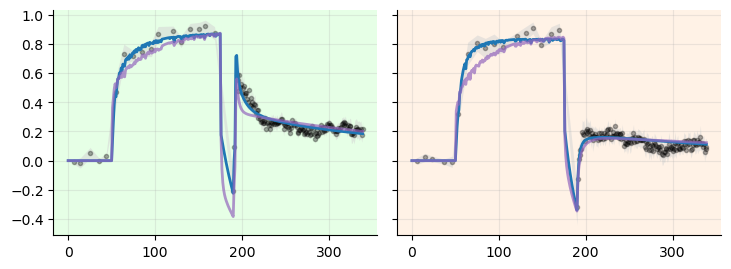

In [ ]:
# Alternative experimental averaging: enforce equal non-NaN counts per trace,
# then average y and x over non-NaN entry index.

def strict_nonan_average_with_sem(exp_mat, x_full):
    exp_mat = np.asarray(exp_mat, dtype=float)
    x_full = np.asarray(x_full, dtype=float)

    if exp_mat.ndim != 2:
        raise ValueError(f'exp_mat must be 2D, got shape {exp_mat.shape}')

    # 1) same number of non-NaNs in each trace (column)
    nn_counts = np.sum(~np.isnan(exp_mat), axis=0)
    if not np.all(nn_counts == nn_counts[0]):
        raise ValueError(f'Non-NaN counts differ across traces: {nn_counts}')

    k = int(nn_counts[0])
    if k == 0:
        raise ValueError('All experimental traces are fully NaN.')

    n_traces = exp_mat.shape[1]
    y_stack = np.empty((k, n_traces), dtype=float)
    x_stack = np.empty((k, n_traces), dtype=float)

    # 2) drop NaNs per trace; average by non-NaN entry index
    for j in range(n_traces):
        mask = ~np.isnan(exp_mat[:, j])
        y_valid = exp_mat[mask, j]
        x_valid = x_full[mask]
        if y_valid.shape[0] != k:
            raise ValueError('Internal consistency error after non-NaN count check.')
        y_stack[:, j] = y_valid
        x_stack[:, j] = x_valid

    x_mean = np.mean(x_stack, axis=1)
    y_mean = np.mean(y_stack, axis=1)

    sem = np.zeros(k, dtype=float)
    if n_traces > 1:
        sem = np.std(y_stack, axis=1, ddof=1) / np.sqrt(n_traces)

    return x_mean, y_mean, sem

plt.rcParams.update(rcConf) 

fig, axes = plt.subplots(1, 2, figsize=(ufigx*2, ufigy), sharey=True)
group_specs = [
    ('ER', 'mean_pred_er', (0.90, 1.00, 0.90), summary_a['best_exp'][:, :split_idx]),
    ('SR', 'mean_pred_sr', (1.00, 0.95, 0.90), summary_a['best_exp'][:, split_idx:]),
]

for ax, (group_name, pred_key, facecolor, exp_mat) in zip(axes, group_specs):
    ax.set_facecolor(facecolor)

    x_exp, y_exp, y_sem = strict_nonan_average_with_sem(exp_mat, trial_idx)
    y_exp_smooth = moving_average(y_exp, window=10)

    ax.fill_between(
        x_exp,
        y_exp - y_sem,
        y_exp + y_sem,
        color='lightgray',
        alpha=0.5,
        linewidth=0,
        label='Experimental SEM (non-NaN aligned)',
    )
    # ax.plot(x_exp, y_exp_smooth, color='gray', linewidth=2.5, label='Experimental mean (smoothed, non-NaN aligned)')
    ax.plot(x_exp, y_exp, '.', color='black', alpha=0.3, label='Experimental mean (non-NaN aligned)')

    ax.plot(
        trial_idx,
        summary_a[pred_key],
        color='tab:blue',
        linewidth=2,
        label=f'{label_a} (seeds={summary_a["seeds_for_compare"]})',
    )
    ax.plot(
        trial_idx,
        summary_b[pred_key],
        color='tab:purple',
        linewidth=2, alpha = 0.7,
        label=f'{label_b} (seeds={summary_b["seeds_for_compare"]})',
    )

    # ax.set_title(group_name)
    # ax.set_xlabel('trial (mean non-NaN index mapped to x)')
    ax.grid(alpha=0.25)

# axes[0].set_ylabel('adaptation')
# axes[0].legend(frameon=False)
# plt.suptitle('Best-MSE fit means by participant group (strict non-NaN averaging)')
plt.tight_layout()


In [ ]:
best_model_state_dict.keys()

odict_keys(['log_learning_rate', 'log_learning_rate_decay', 'sigma_b', 'sp_weight_decay', 'sigma_x', 'x_fast_alpha', '_z_biases', '_w_in', '_w_inq', 'input_scale'])

In [ ]:
exp_mat.shape

(340, 8)

In [ ]:
np.inf

inf

In [ ]:
np.nan == np.nan

False

In [ ]:
args

namespace(apply_lr_decay=True,
          apply_scaled_soft_plus_on_w_in_params=False,
          assume_opt_output_noise=True,
          batch_param_period=64,
          batch_param_tie_grad='sum',
          batch_param_tie_names='all',
          bound_weight_decay=False,
          bs=16,
          channel_trial_extra_error=0.0,
          debug_flag_win2nd_column_positive_only=False,
          develop_b_tgt=0.0,
          direct_inj_limiter=1.0,
          disable_lpfs=True,
          enable_bias_update=False,
          enable_direct_injection=False,
          enable_elpf=False,
          enable_input_scale_tuning=False,
          enable_output_scale_tuning=True,
          enable_q_scale_tuning=False,
          enable_qlpf=False,
          enable_separate_win_per_rate=False,
          enable_sigma_b_tuning=False,
          enable_u_feedback_scale_tuning=False,
          enable_w_in_plasticity=False,
          enable_w_in_scale_tuning=False,
          enable_weight_decay_exp=False,
      

In [ ]:
model.sigma_b

tensor([0.1757, 0.1757, 0.1757, 0.1757, 0.1757, 0.1757, 0.1757, 0.1757, 0.1757,
        0.1757, 0.1757, 0.1757, 0.1757, 0.1757, 0.1757, 0.1757],
       device='cuda:0')

In [ ]:
debu_v1 = np.loadtxt('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/froB_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1/a_pred.txt')
debu_v2 = np.loadtxt('/homes/ar2342/one_more_dir/contextual_frogs/results_part2/froBmedian_MEANWZeroORDERxlpfSftPlusWdepLRscaleOutClmpLRRecvov40m_inj0p4_with_Nseeds_1/a_pred.txt')

In [ ]:
debu_v1.shape

(340, 1024)

In [ ]:
debu_v2.shape

(340, 1024)

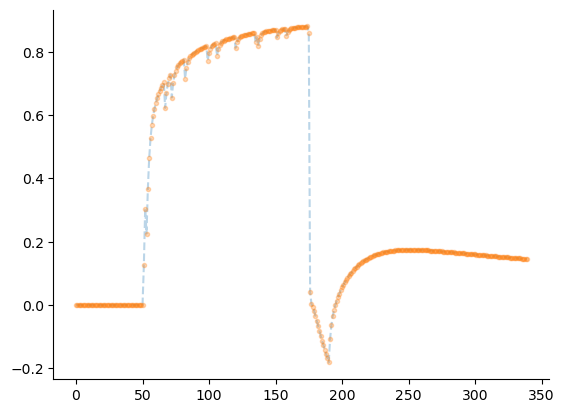

In [ ]:
plt.plot(debu_v1[:,64*9+1], '--', alpha=0.3)
plt.plot(debu_v2[:,64*9+1], '.', alpha=0.3)